# 🏈 What Wins in the NFL?
## A hands-on introduction to linear and logistic regression

In this notebook you will use real NFL data to answer three questions:

1. **Which stats explain how many points a team scores and allows?** (linear regression)
2. **Which stats explain how many games a team wins?** (linear regression)
3. **What is a team's chance of winning at any moment of a game, and which plays change it the most?** (logistic regression)

### Learning goals
By the end you should be able to:
* fit and interpret a **simple** and a **multiple linear regression**
* turn coefficients into a prediction **by hand**
* explain why we test a model on data it has **never seen**
* explain why a yes/no outcome needs **logistic regression**, and compute a probability from its coefficients
* explain what a **win-probability swing (WPA)** is and calculate one

### How to use this notebook
Run the cells **in order, from top to bottom** (Runtime → Run all works too). Look for these boxes:

| Icon | Meaning |
|---|---|
| 💡 | **Key idea**: the concept to remember |
| 🔍 | **Check your understanding**: answer in your head, then click to reveal |
| ✏️ | **Try it**: change a value in the cell and run it again |

### Roadmap
| Part | Topic | Method |
|---|---|---|
| 0 | Setup | |
| 1 | Building the dataset | data cleaning |
| 2 | Exploring the data | scatter plots, correlation |
| 3 | One stat, one line | simple linear regression |
| 4 | Many stats at once | multiple linear regression |
| 5 | From points to wins | regression on win % |
| 6 | Win probability | **logistic regression** |
| 7 | The most important plays | win probability added |
| 8 | The 2026 season so far | applying the models |
| 9 | Limitations and exercises | |

## Part 0 · Setup

This installs the data package ([nflverse](https://github.com/nflverse)) and loads the Python libraries we use. It takes about 30 seconds the first time.

In [1]:
!pip -q install nflreadpy pyarrow statsmodels

import nflreadpy as nfl
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from sklearn.metrics import mean_absolute_error, r2_score

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:.3f}".format)

FIRST_SEASON   = 2010
CURRENT_SEASON = 2026        # partial season, used only at the end
TEST_SEASONS   = [2024, 2025]  # held out to check out-of-sample accuracy
SEASONS = list(range(FIRST_SEASON, CURRENT_SEASON + 1))

### Team colors and logos
These helper functions put team logos and colors on our charts. You don't need to understand this code. If a logo can't load, the chart shows a team-colored circle instead.

In [2]:
import io, urllib.request
from PIL import Image
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
from IPython.display import display, HTML

TEAM = nfl.load_teams().to_pandas().drop_duplicates("team_abbr").set_index("team_abbr")
COLOR  = TEAM.team_color.to_dict()     # primary color, e.g. COLOR["KC"] -> "#E31837"
COLOR2 = TEAM.team_color2.to_dict()    # secondary color
LOGO_URL = TEAM.team_logo_espn.to_dict()
_logos = {}

def get_logo(team, size=120):
    """Download a team logo once, cache it, and return it as a PIL image (or None)."""
    if team not in _logos:
        _logos[team] = None
        backup = (TEAM.at[team, "team_logo_squared"]
                  .replace("https://github.com/", "https://raw.githubusercontent.com/").replace("/raw/", "/"))
        for url in [TEAM.at[team, "team_logo_espn"], backup]:
            try:
                req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
                img = Image.open(io.BytesIO(urllib.request.urlopen(req, timeout=10).read())).convert("RGBA")
                img.thumbnail((size, size))
                _logos[team] = img
                break
            except Exception:
                pass
    return _logos[team]

def add_logo(ax, team, x, y, zoom=0.28):
    """Place a team logo on a matplotlib chart at data coordinates (x, y)."""
    img = get_logo(team)
    if img is None:   # fallback: team-colored dot with the abbreviation
        ax.scatter(x, y, s=420, color=COLOR.get(team, "gray"), edgecolor="white", zorder=3)
        ax.annotate(team, (x, y), ha="center", va="center", color="white", fontsize=7, weight="bold", zorder=4)
    else:
        ax.add_artist(AnnotationBbox(OffsetImage(img, zoom=zoom), (x, y), frameon=False, zorder=3))

def logo_html(team, width=30):
    return f'<img src="{LOGO_URL.get(team, "")}" width="{width}" style="vertical-align:middle">'

print("Loaded colors/logos for", len(TEAM), "team codes")

Loaded colors/logos for 36 team codes


## Part 1 · Building the dataset

Every row of our final dataset will be one **team-season**, for example *the 2023 Ravens*. Why seasons and not single games? One game is noisy: a tipped interception can swing 14 points. Over a full season that luck mostly averages out, so the numbers describe what a team **is**.

### Step 1: Load game-by-game stats and final scores

In [3]:
games = nfl.load_team_stats(seasons=SEASONS, summary_level="week").to_pandas()
games = games[games["season_type"] == "REG"].copy()

sched = nfl.load_schedules(seasons=SEASONS).to_pandas()
sched = sched[(sched["game_type"] == "REG") & sched["home_score"].notna()].copy()

print("Team-game rows:", len(games))
print("Completed games:", len(sched))
print("Latest 2026 week with results:", int(sched.loc[sched.season == CURRENT_SEASON, "week"].max()))

Team-game rows: 8650
Completed games: 4325
Latest 2026 week with results: 10


### Step 2: Get each team's **defensive** stats
A team's defense stats are just its **opponent's offense** stats in the same game. So we match every row with the opposing team's row and add the prefix `opp_`.

Example: if the 49ers' opponent threw for 180 yards, then `opp_passing_yards = 180` on the 49ers' row means *the 49ers' defense allowed 180 passing yards*.

In [4]:
raw_cols = [
    "attempts", "completions", "passing_yards", "sack_yards_lost", "sacks_suffered",
    "passing_interceptions", "carries", "rushing_yards",
    "sack_fumbles_lost", "rushing_fumbles_lost", "receiving_fumbles_lost",
    "passing_first_downs", "rushing_first_downs", "penalty_yards",
]

opp = games[["game_id", "team"] + raw_cols].rename(
    columns={"team": "opponent_team", **{c: f"opp_{c}" for c in raw_cols}}
)

games = games.merge(opp, on=["game_id", "opponent_team"], how="inner")
games[["team", "opponent_team", "week", "passing_yards", "opp_passing_yards"]].head()

,team,opponent_team,week,passing_yards,opp_passing_yards
0,ARI,LA,1,297,253
1,ATL,PIT,1,252,236
2,BAL,NYJ,1,248,74
3,BUF,MIA,1,139,182
4,CAR,NYG,1,182,263


### Step 3: Add points scored and allowed
A small cleanup is hidden in here: older seasons use old codes for teams that moved (OAK → LV, SD → LAC, STL → LA). Without fixing them, those teams would silently disappear.

In [5]:
relocated = {"OAK": "LV", "SD": "LAC", "STL": "LA"}
sched["home_team"] = sched["home_team"].replace(relocated)
sched["away_team"] = sched["away_team"].replace(relocated)

home = sched[["game_id", "home_team", "home_score", "away_score"]].rename(
    columns={"home_team": "team", "home_score": "pts_for", "away_score": "pts_against"})
away = sched[["game_id", "away_team", "away_score", "home_score"]].rename(
    columns={"away_team": "team", "away_score": "pts_for", "home_score": "pts_against"})
scores = pd.concat([home, away], ignore_index=True)

scores["win"] = np.select(
    [scores.pts_for > scores.pts_against, scores.pts_for == scores.pts_against],
    [1.0, 0.5], default=0.0)  # ties count as half a win

games = games.merge(scores, on=["game_id", "team"], how="inner")
print(games.shape)
assert games.groupby("season").team.nunique().eq(32).all(), "a team is missing from some season"

(8650, 155)


### Step 4: Add up each season and compute the stats we'll use

| Offense stat | What it means | Defense version |
|---|---|---|
| `off_ny_a` | **Net yards per pass attempt** = (pass yards − sack yards) ÷ (attempts + sacks) | `def_ny_a`: allowed |
| `off_ypc` | **Yards per carry** (rushing) | `def_ypc`: allowed |
| `off_to_pg` | **Giveaways per game**: interceptions + fumbles lost | `def_to_pg`: **takeaways** per game |
| `off_sack_rate` | Share of dropbacks that end in a **sack** | `def_sack_rate`: sacks **made** |
| `off_fd_pg` | **First downs** per game | `def_fd_pg`: allowed |
| `off_pen_ypg` | **Penalty yards** per game | |

The things we want to explain (**outcomes**): `ppg` (points scored per game), `papg` (points allowed per game), `diff_pg` (point differential per game) and `win_pct`.

💡 **Key idea:** we leave out touchdowns and field goals on purpose. They *are* points, so "predicting" points with them would be circular. We want the stats that **lead to** points.

In [6]:
sum_cols = raw_cols + [f"opp_{c}" for c in raw_cols] + ["pts_for", "pts_against", "win"]

season = (games.groupby(["season", "team"])
               .agg(games=("game_id", "nunique"), **{c: (c, "sum") for c in sum_cols})
               .reset_index())

g = season["games"]

# ---------- Offense ----------
season["off_ny_a"]      = (season.passing_yards + season.sack_yards_lost) / (season.attempts + season.sacks_suffered)
season["off_ypc"]       = season.rushing_yards / season.carries
season["off_to_pg"]     = (season.passing_interceptions + season.sack_fumbles_lost
                           + season.rushing_fumbles_lost + season.receiving_fumbles_lost) / g
season["off_sack_rate"] = season.sacks_suffered / (season.attempts + season.sacks_suffered)
season["off_fd_pg"]     = (season.passing_first_downs + season.rushing_first_downs) / g
season["off_pen_ypg"]   = season.penalty_yards / g

# ---------- Defense (what opponents did against this team) ----------
season["def_ny_a"]      = (season.opp_passing_yards + season.opp_sack_yards_lost) / (season.opp_attempts + season.opp_sacks_suffered)
season["def_ypc"]       = season.opp_rushing_yards / season.opp_carries
season["def_to_pg"]     = (season.opp_passing_interceptions + season.opp_sack_fumbles_lost
                           + season.opp_rushing_fumbles_lost + season.opp_receiving_fumbles_lost) / g
season["def_sack_rate"] = season.opp_sacks_suffered / (season.opp_attempts + season.opp_sacks_suffered)
season["def_fd_pg"]     = (season.opp_passing_first_downs + season.opp_rushing_first_downs) / g

# ---------- Outcomes ----------
season["ppg"]      = season.pts_for / g        # points scored per game
season["papg"]     = season.pts_against / g    # points allowed per game
season["diff_pg"]  = season.ppg - season.papg  # point differential per game
season["win_pct"]  = season.win / g

OFF = ["off_ny_a", "off_ypc", "off_to_pg", "off_sack_rate", "off_fd_pg", "off_pen_ypg"]
DEF = ["def_ny_a", "def_ypc", "def_to_pg", "def_sack_rate", "def_fd_pg"]

full    = season[season.season <  CURRENT_SEASON].copy()   # complete seasons
current = season[season.season == CURRENT_SEASON].copy()   # 2026 so far

print(f"Complete team-seasons: {len(full)}  ({full.season.min()}–{full.season.max()})")
full[["season", "team", "games"] + OFF + ["ppg"]].sort_values("ppg", ascending=False).head(10)

Complete team-seasons: 512  (2010–2025)


,season,team,games,off_ny_a,off_ypc,off_to_pg,off_sack_rate,off_fd_pg,off_pen_ypg,ppg
105,2013,DEN,16,7.833,4.063,1.312,0.029,25.000,62.500,37.875
271,2018,KC,16,8.136,4.793,1.125,0.043,21.688,72.000,35.312
43,2011,GB,16,8.306,3.944,0.688,0.069,19.938,36.938,35.000
85,2012,NE,16,6.979,4.176,0.938,0.040,25.438,52.500,34.812
54,2011,NO,16,7.846,4.952,1.188,0.035,24.938,53.188,34.188
193,2016,ATL,16,8.232,4.580,0.688,0.064,21.688,52.938,33.750
290,2019,BAL,16,6.891,5.530,0.875,0.060,22.438,54.188,33.188
458,2024,DET,17,7.661,4.659,0.882,0.057,22.706,57.235,33.176
272,2018,LA,16,7.499,4.861,1.125,0.055,23.125,54.875,32.938
21,2010,NE,16,7.231,4.346,0.562,0.047,19.688,47.875,32.375


> 🔍 **Check your understanding:** Why do we add up yards and attempts over the whole season first, and only *then* divide, instead of averaging each game's yards per attempt?

<details><summary><b>Click to reveal the answer</b></summary>

Averaging game rates gives a 10-attempt game the same weight as a 50-attempt game. Dividing season totals weights every attempt equally.

</details>

### Step 5: Check the data
Good analysts check their data before modeling. This should print **0**, **[32]**, **[16, 17]** and **True**.

In [7]:
official = nfl.load_team_stats(seasons=list(range(FIRST_SEASON, CURRENT_SEASON)), summary_level="reg").to_pandas()
check_cols = ["attempts", "passing_yards", "sack_yards_lost", "sacks_suffered", "passing_interceptions",
              "carries", "rushing_yards", "passing_first_downs", "rushing_first_downs", "penalty_yards"]
diff = (full.set_index(["season", "team"])[check_cols]
        - official.set_index(["season", "team"])[check_cols]).abs().max()
print("Largest difference vs. official season totals:", int(diff.max()))
print("Teams per season:", full.groupby("season").team.nunique().unique())
print("Games per team-season:", sorted(full.games.unique()))
print("Points scored == points allowed league-wide:",
      bool((full.groupby("season").pts_for.sum() == full.groupby("season").pts_against.sum()).all()))

Largest difference vs. official season totals: 0
Teams per season: [32]
Games per team-season: [np.int64(16), np.int64(17)]
Points scored == points allowed league-wide: True


## Part 2 · Exploring the data

Before fitting any model, **look at the data**. Each dot below is one team-season. The number in each title is the **correlation** *r*: how tightly the dots follow a straight line, from −1 (perfect downhill) through 0 (no pattern) to +1 (perfect uphill).

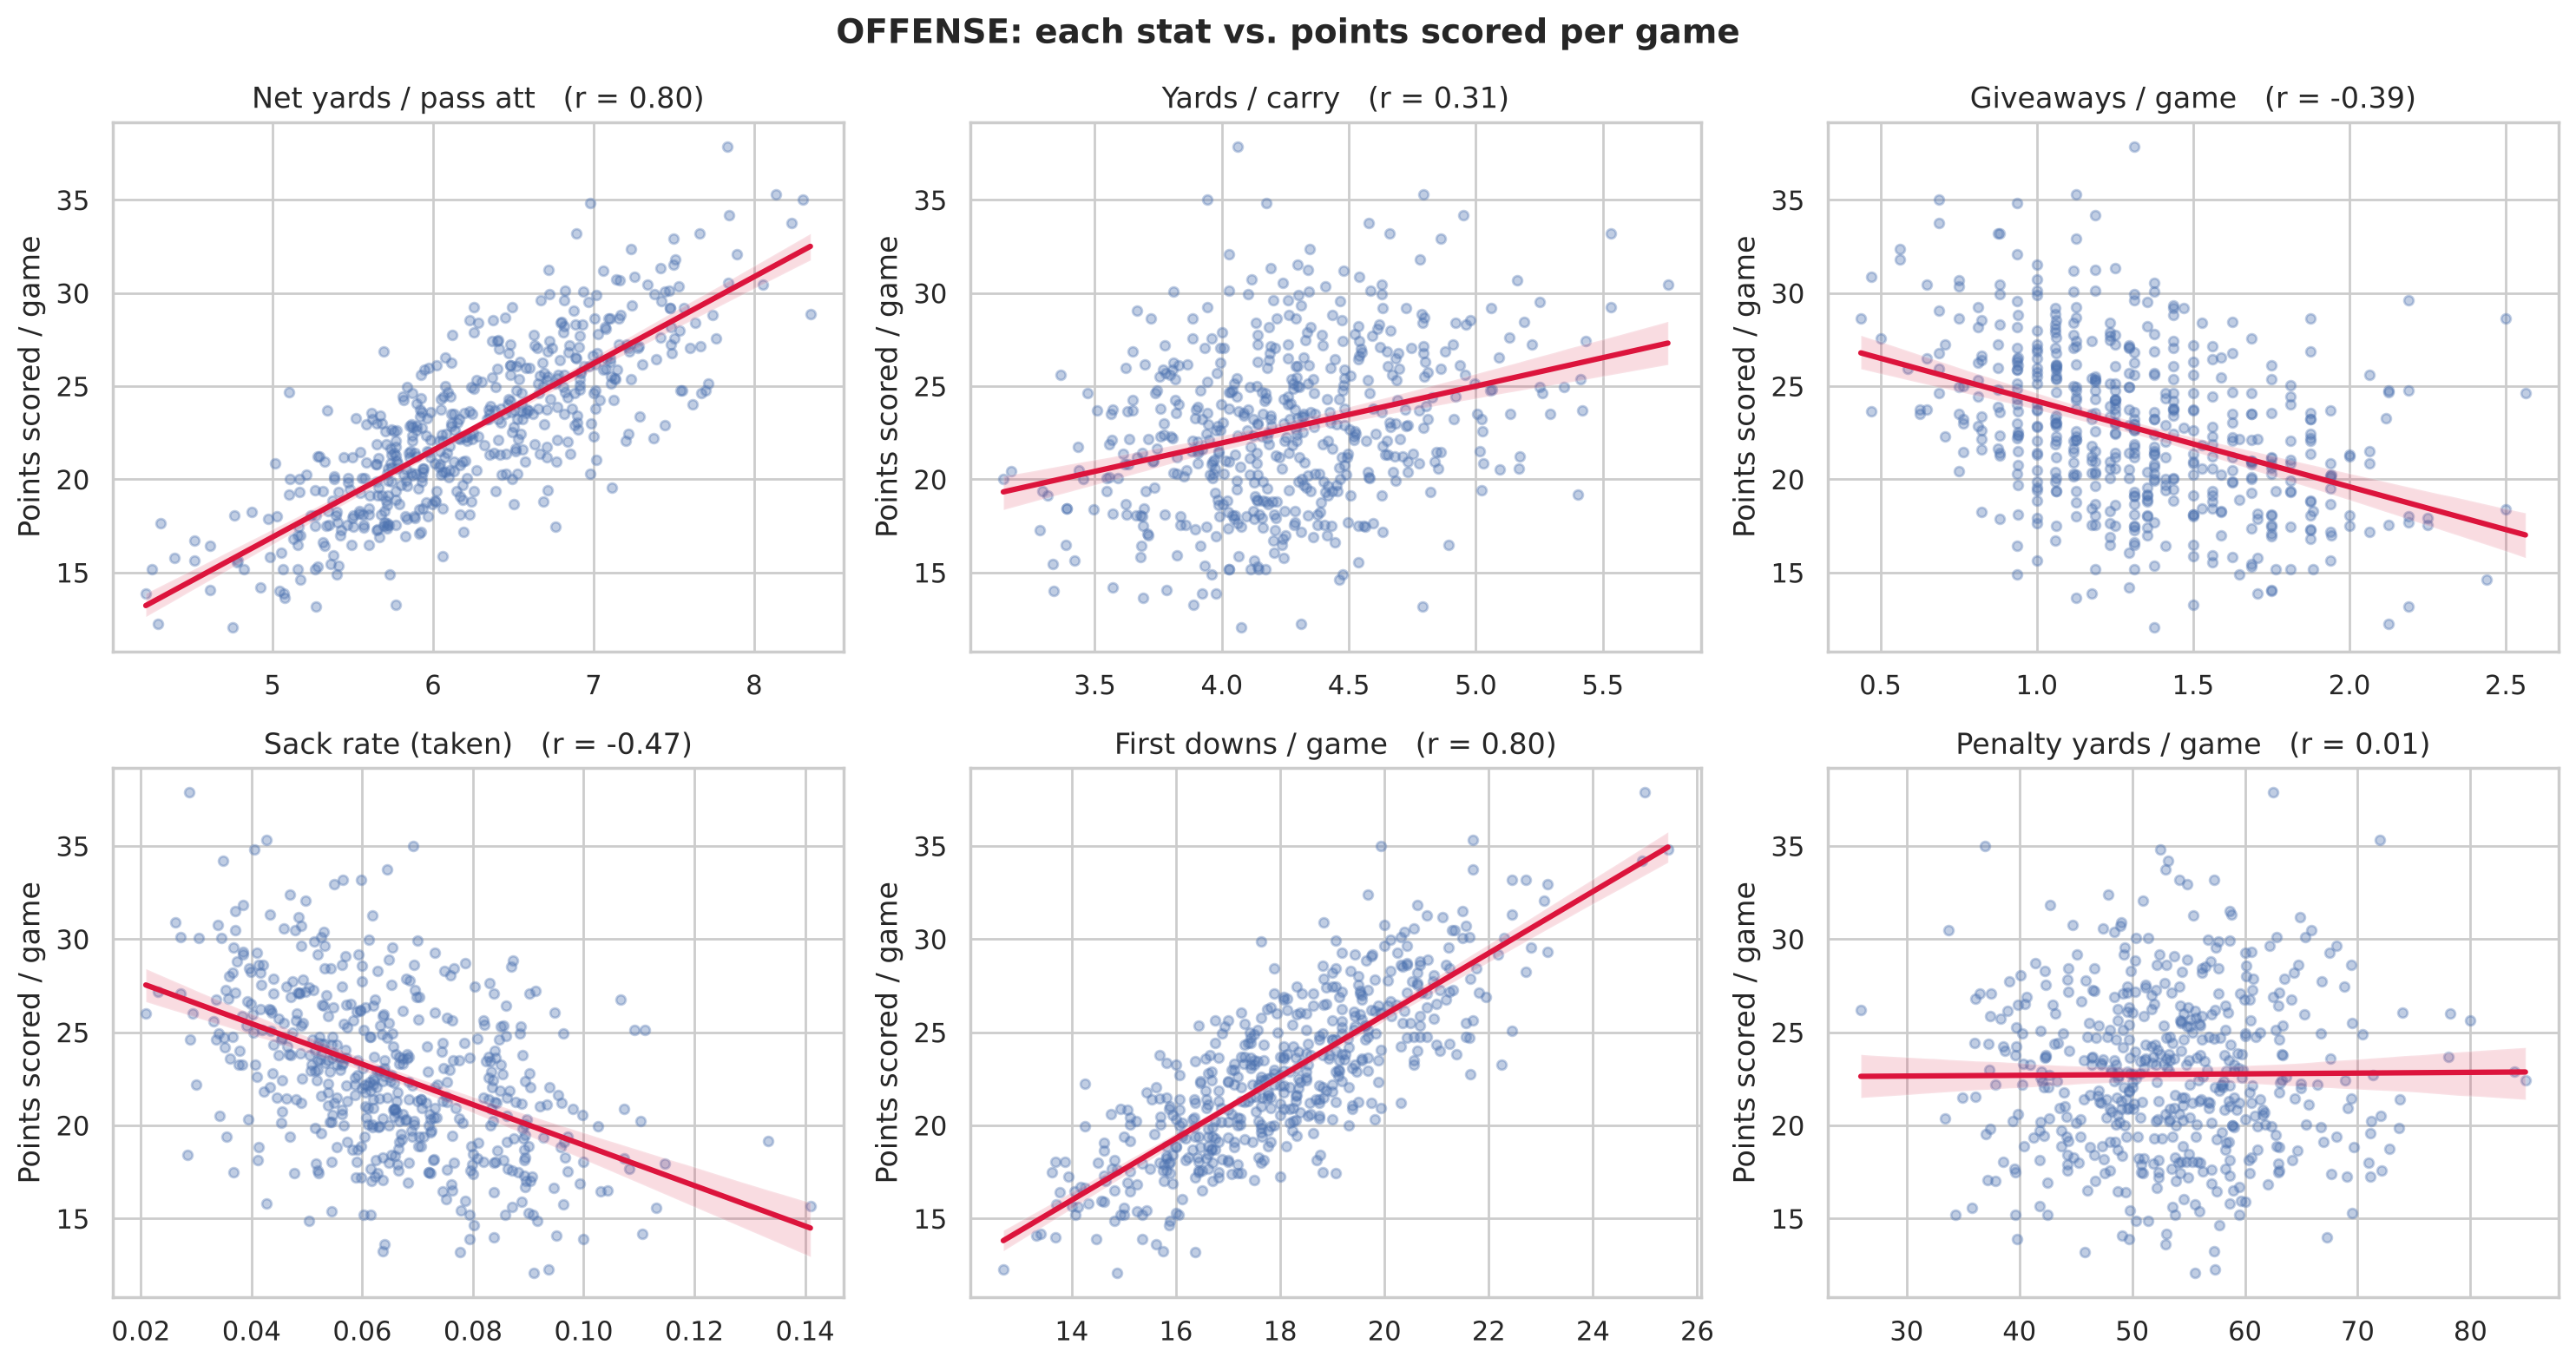

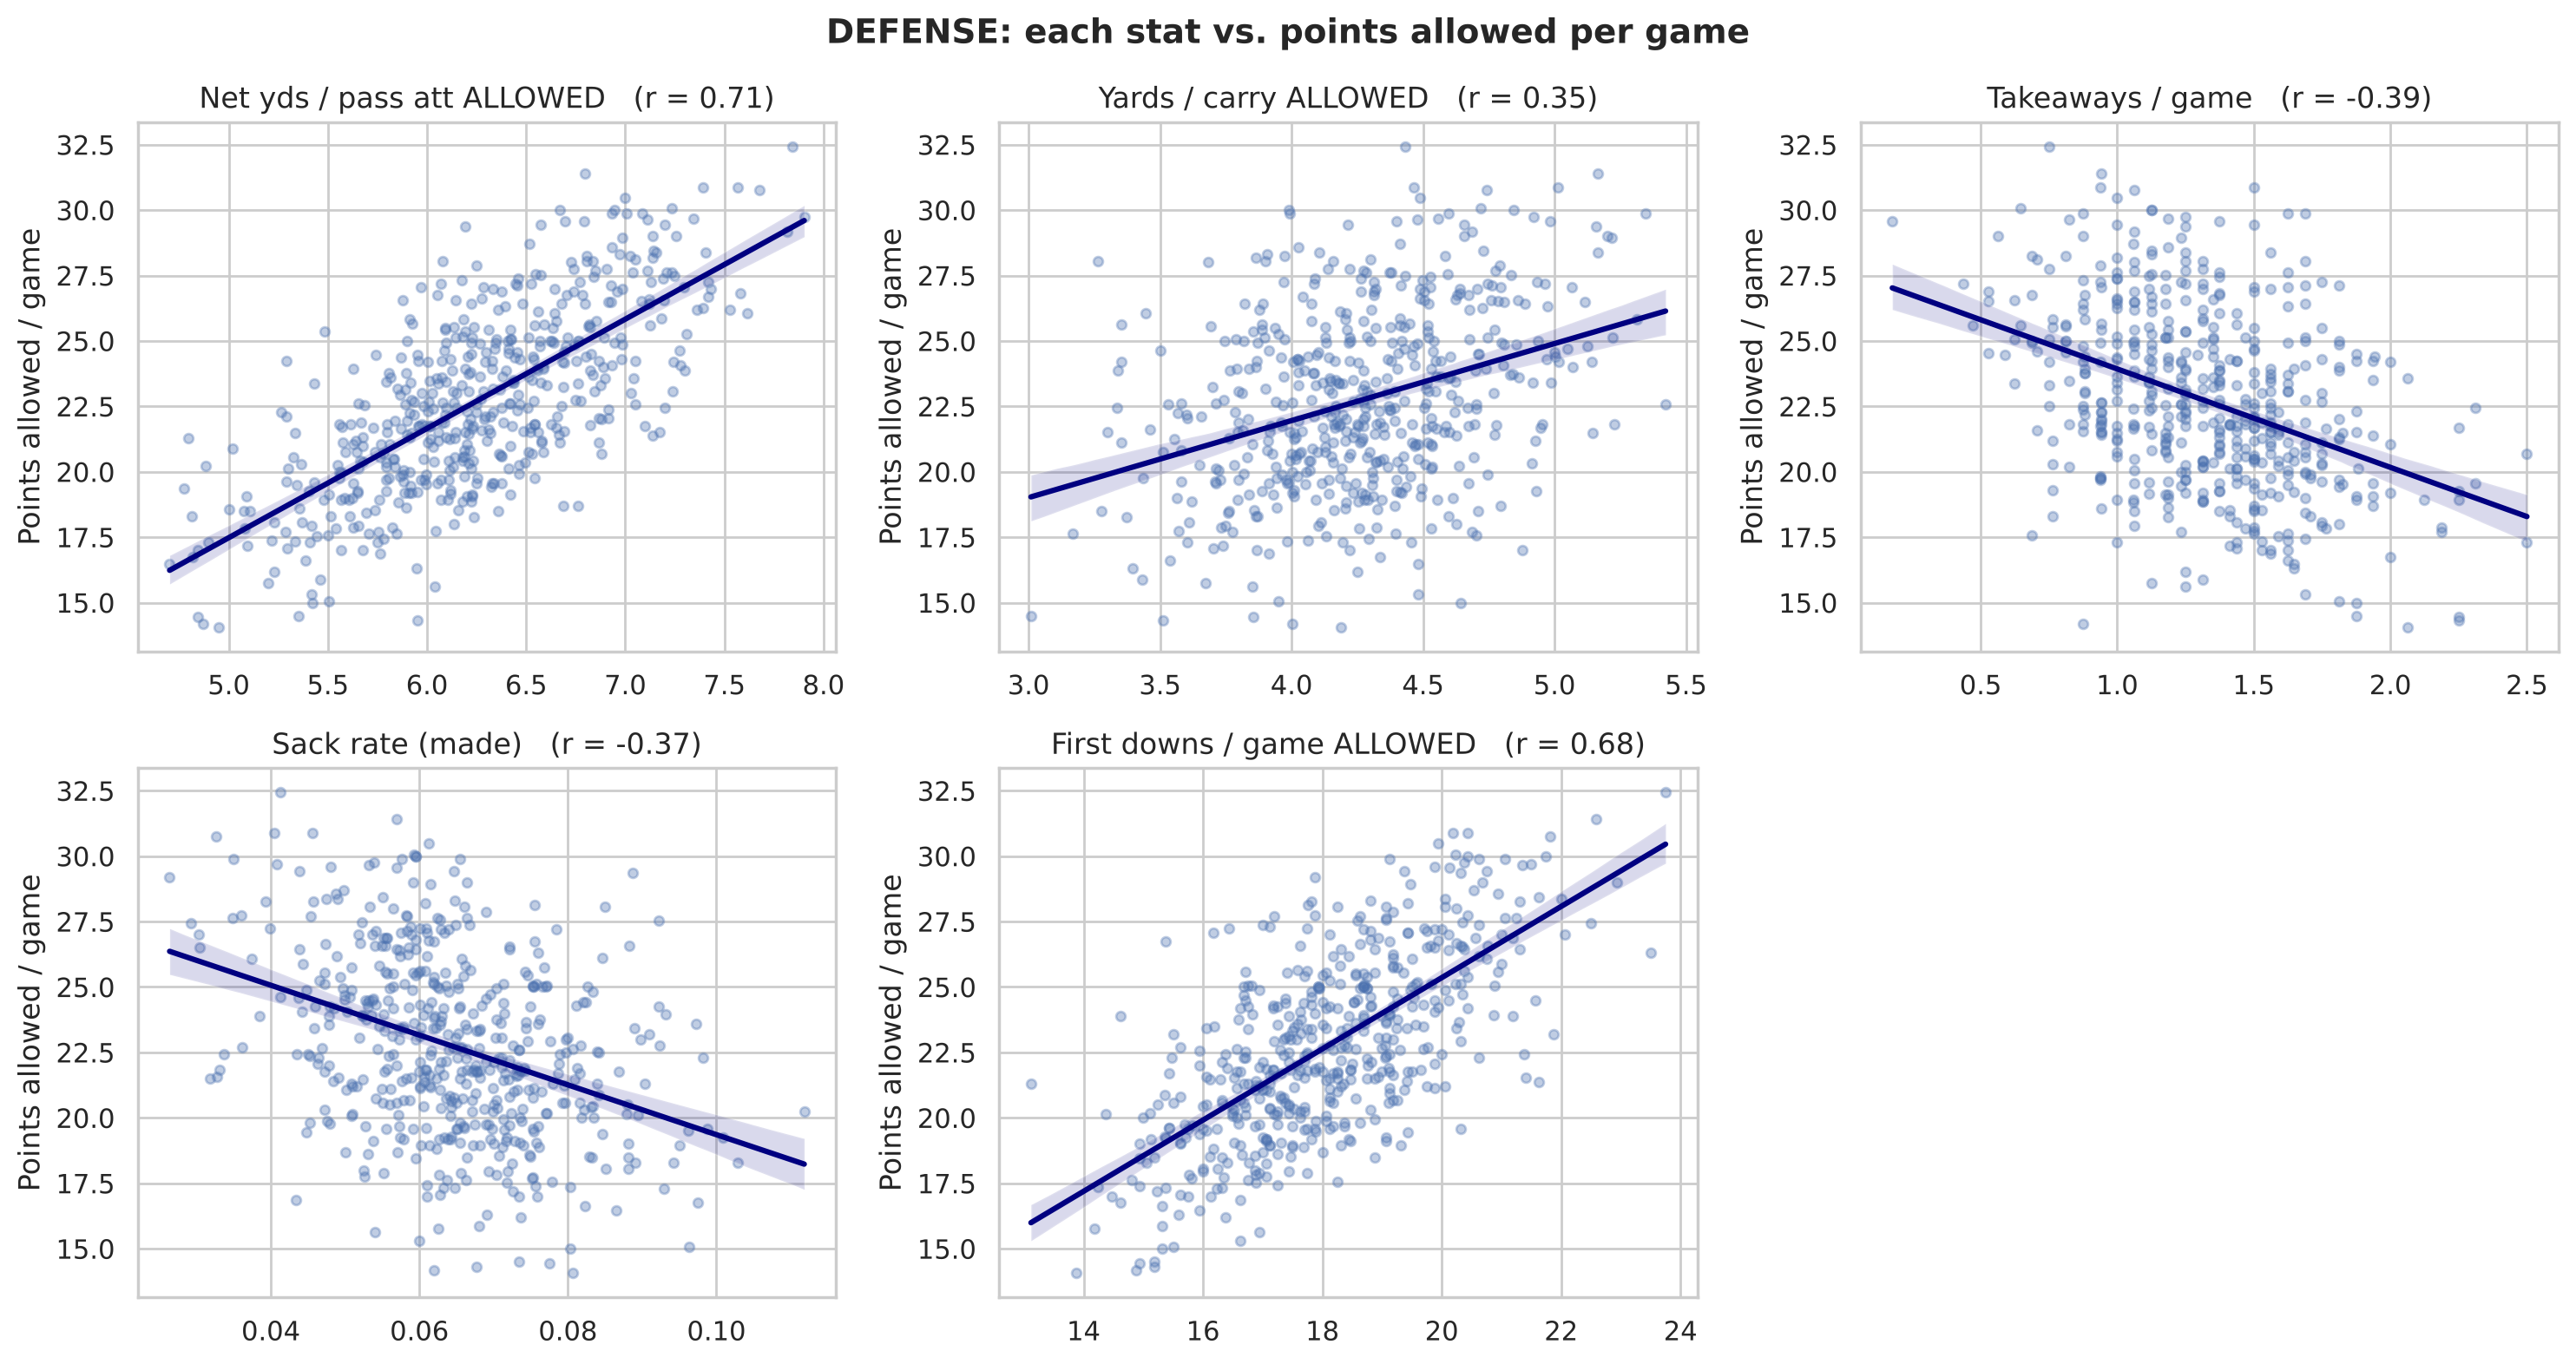

In [8]:
labels = {
    "off_ny_a": "Net yards / pass att", "off_ypc": "Yards / carry",
    "off_to_pg": "Giveaways / game", "off_sack_rate": "Sack rate (taken)",
    "off_fd_pg": "First downs / game", "off_pen_ypg": "Penalty yards / game",
    "def_ny_a": "Net yds / pass att ALLOWED", "def_ypc": "Yards / carry ALLOWED",
    "def_to_pg": "Takeaways / game", "def_sack_rate": "Sack rate (made)",
    "def_fd_pg": "First downs / game ALLOWED",
}

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, OFF):
    sns.regplot(data=full, x=col, y="ppg", ax=ax, scatter_kws={"alpha": .35, "s": 15}, line_kws={"color": "crimson"})
    r = full[[col, "ppg"]].corr().iloc[0, 1]
    ax.set(title=f"{labels[col]}   (r = {r:.2f})", xlabel="", ylabel="Points scored / game")
fig.suptitle("OFFENSE: each stat vs. points scored per game", fontsize=14, weight="bold")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, DEF):
    sns.regplot(data=full, x=col, y="papg", ax=ax, scatter_kws={"alpha": .35, "s": 15}, line_kws={"color": "navy"})
    r = full[[col, "papg"]].corr().iloc[0, 1]
    ax.set(title=f"{labels[col]}   (r = {r:.2f})", xlabel="", ylabel="Points allowed / game")
axes.flat[-1].axis("off")
fig.suptitle("DEFENSE: each stat vs. points allowed per game", fontsize=14, weight="bold")
plt.tight_layout(); plt.show()

> 🔍 **Check your understanding:** Which offensive stat has the strongest relationship with points scored? Which one slopes *downward*, and why does that make sense?

<details><summary><b>Click to reveal the answer</b></summary>

Net yards per pass attempt has the strongest relationship (r ≈ 0.80). Giveaways per game slopes downward: turnovers end drives, so more of them means fewer points.

</details>

### League map: passing offense vs. passing defense
The same idea for one season, with logos. Teams in the **top-right** pass well **and** stop the pass well.

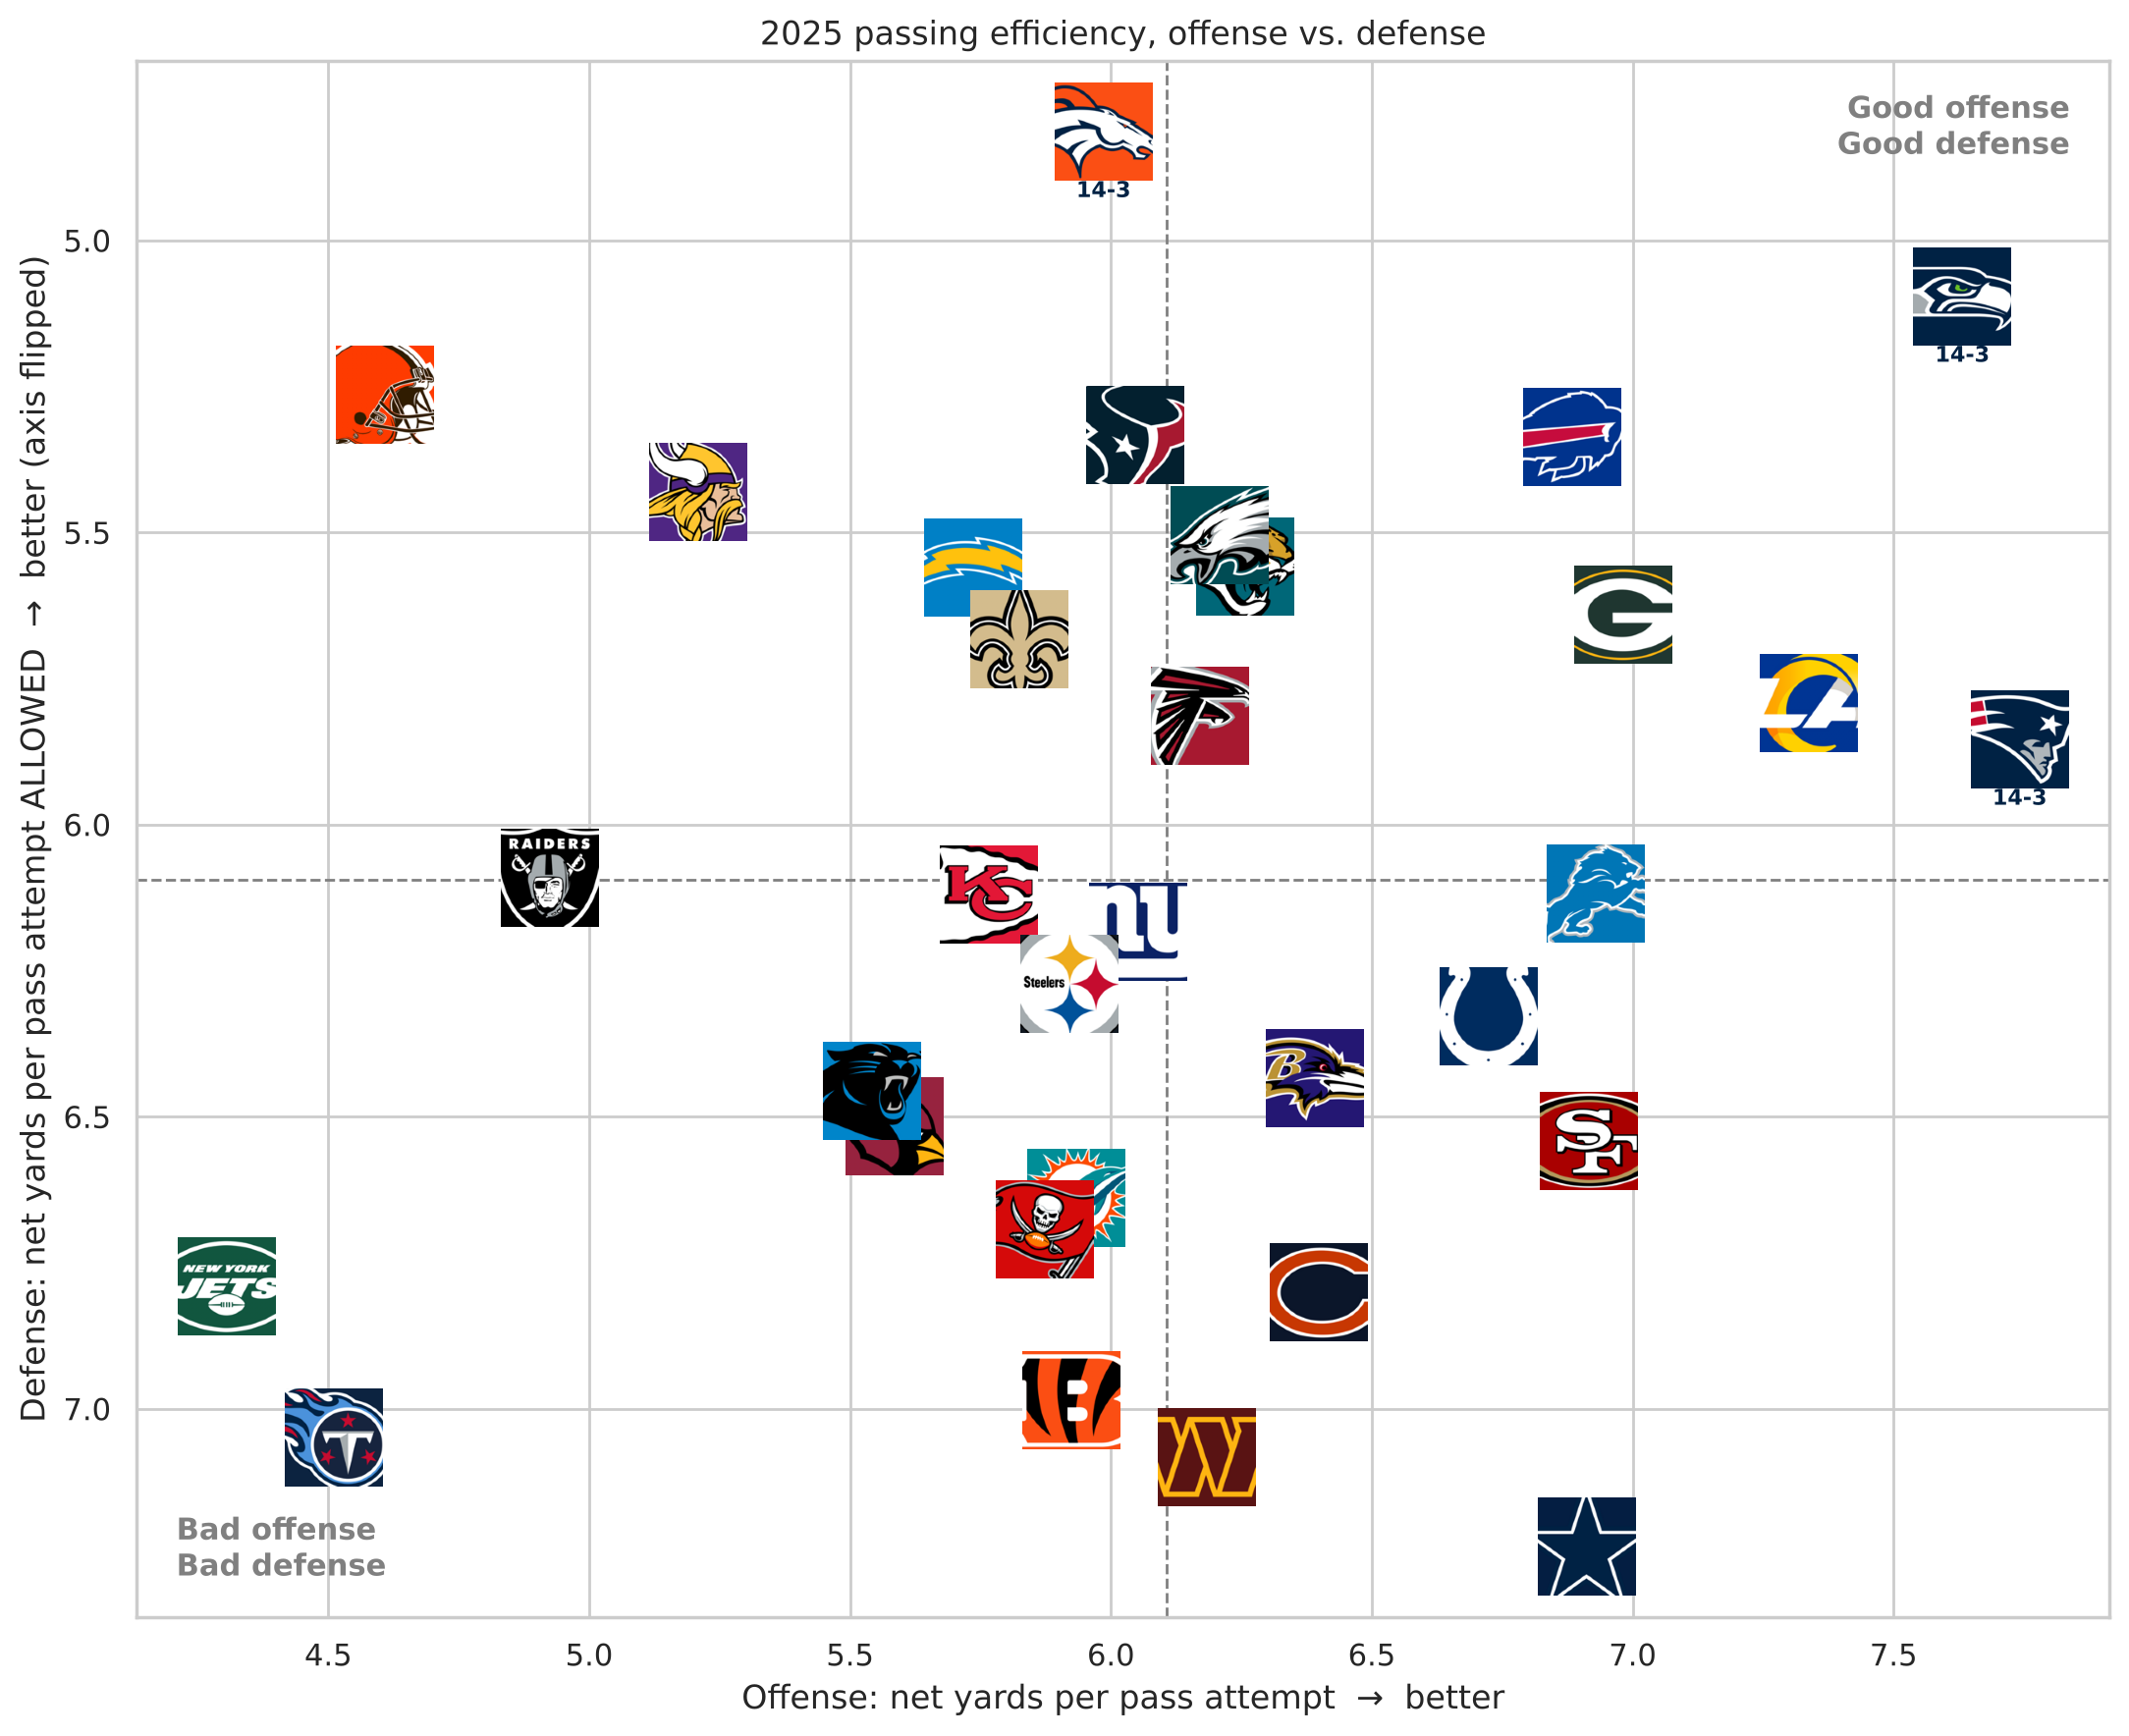

In [9]:
def record(season, team):
    """W-L (or W-L-T) record from game results."""
    w = games.loc[(games.season == season) & (games.team == team), "win"]
    W, L, T = (w == 1).sum(), (w == 0).sum(), (w == 0.5).sum()
    return f"{W}-{L}" + (f"-{T}" if T else "")

LAST_FULL = CURRENT_SEASON - 1
lm = full[full.season == LAST_FULL]

fig, ax = plt.subplots(figsize=(11, 9))
ax.scatter(lm.off_ny_a, lm.def_ny_a, alpha=0)            # sets the axis limits
for _, r in lm.iterrows():
    add_logo(ax, r.team, r.off_ny_a, r.def_ny_a, zoom=0.30)
ax.axvline(lm.off_ny_a.mean(), color="gray", ls="--", lw=1)
ax.axhline(lm.def_ny_a.mean(), color="gray", ls="--", lw=1)
ax.invert_yaxis()                                         # fewer yards allowed = higher on the chart
pad = dict(fontsize=11, color="gray", weight="bold")
ax.text(.98, .98, "Good offense\nGood defense", transform=ax.transAxes, ha="right", va="top", **pad)
ax.text(.02, .02, "Bad offense\nBad defense", transform=ax.transAxes, ha="left", va="bottom", **pad)
ax.set(xlabel="Offense: net yards per pass attempt  →  better",
       ylabel="Defense: net yards per pass attempt ALLOWED  →  better (axis flipped)",
       title=f"{LAST_FULL} passing efficiency, offense vs. defense")
for r in lm.nlargest(3, "win_pct").itertuples():
    ax.annotate(record(LAST_FULL, r.team), (r.off_ny_a, r.def_ny_a), xytext=(0, -24),
                textcoords="offset points", ha="center", fontsize=8, color=COLOR.get(r.team, "black"), weight="bold")
plt.tight_layout(); plt.show()

### Do the stats overlap?
If two stats measure nearly the same thing, a regression has trouble separating their effects (this is called **multicollinearity**). Look for big numbers *between* predictors, such as first downs and passing efficiency.

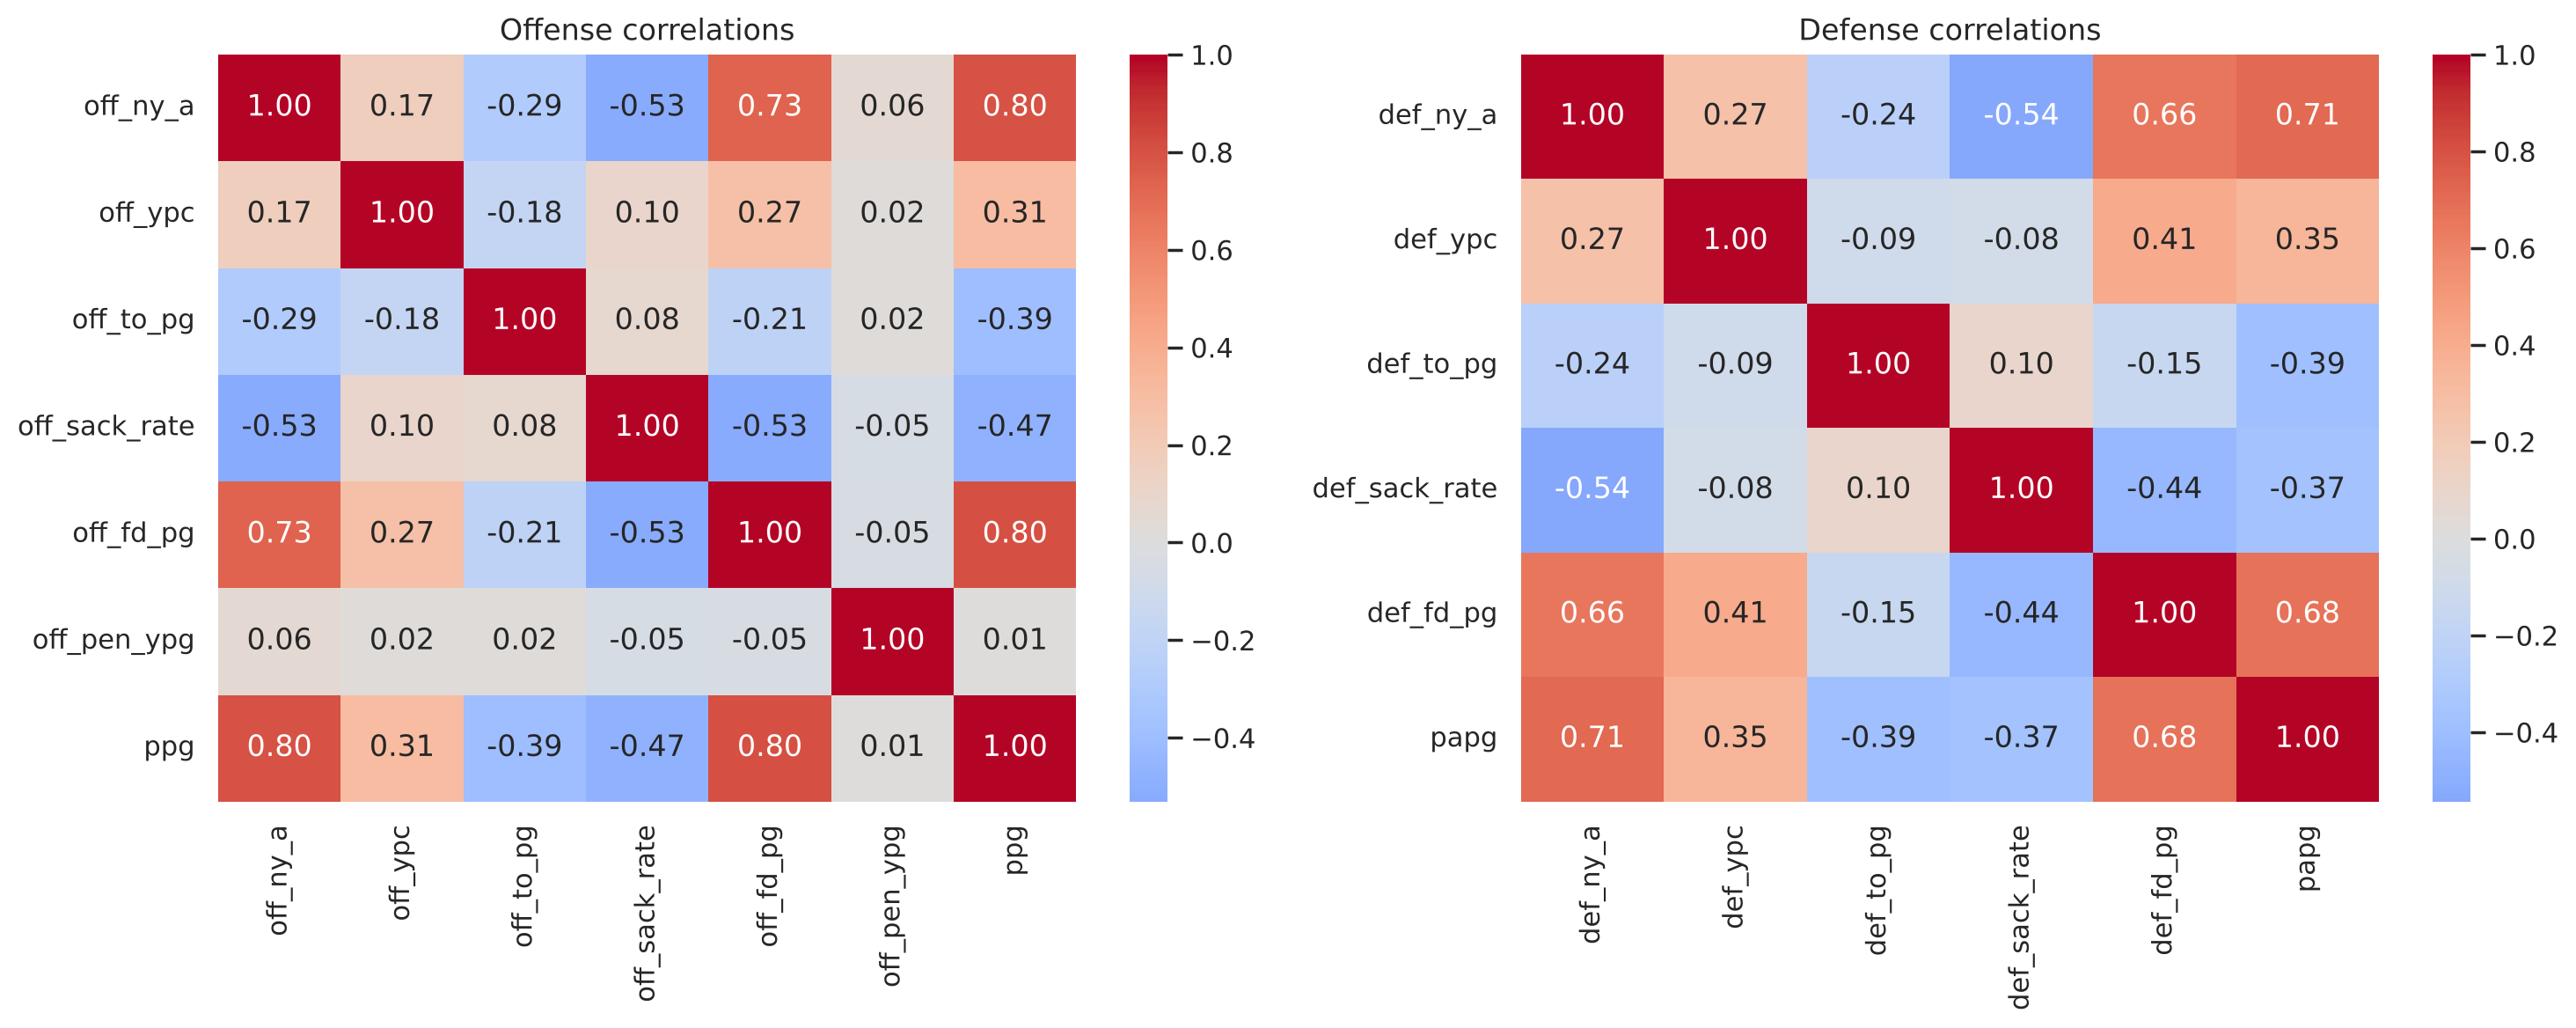

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.heatmap(full[OFF + ["ppg"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[0])
axes[0].set_title("Offense correlations")
sns.heatmap(full[DEF + ["papg"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[1])
axes[1].set_title("Defense correlations")
plt.tight_layout(); plt.show()

## Part 3 · Simple linear regression: one stat, one line

Let's start with the single best stat. **Simple linear regression** draws the straight line that best fits the dots:

$$\text{points per game} = b_0 + b_1 \times \text{net yards per pass attempt}$$

* $b_0$ is the **intercept**: where the line crosses zero (often not meaningful on its own)
* $b_1$ is the **slope**: how many more points per game come with **one more** net yard per attempt

"Best fit" means the line that makes the **squared vertical distances** from the dots to the line (the **residuals**) as small as possible. This is called **ordinary least squares (OLS)**.

Fitted line:  points per game = -6.39 + 4.66 × (net yards per pass attempt)
R² = 0.64  →  passing efficiency alone explains 64% of the differences in scoring


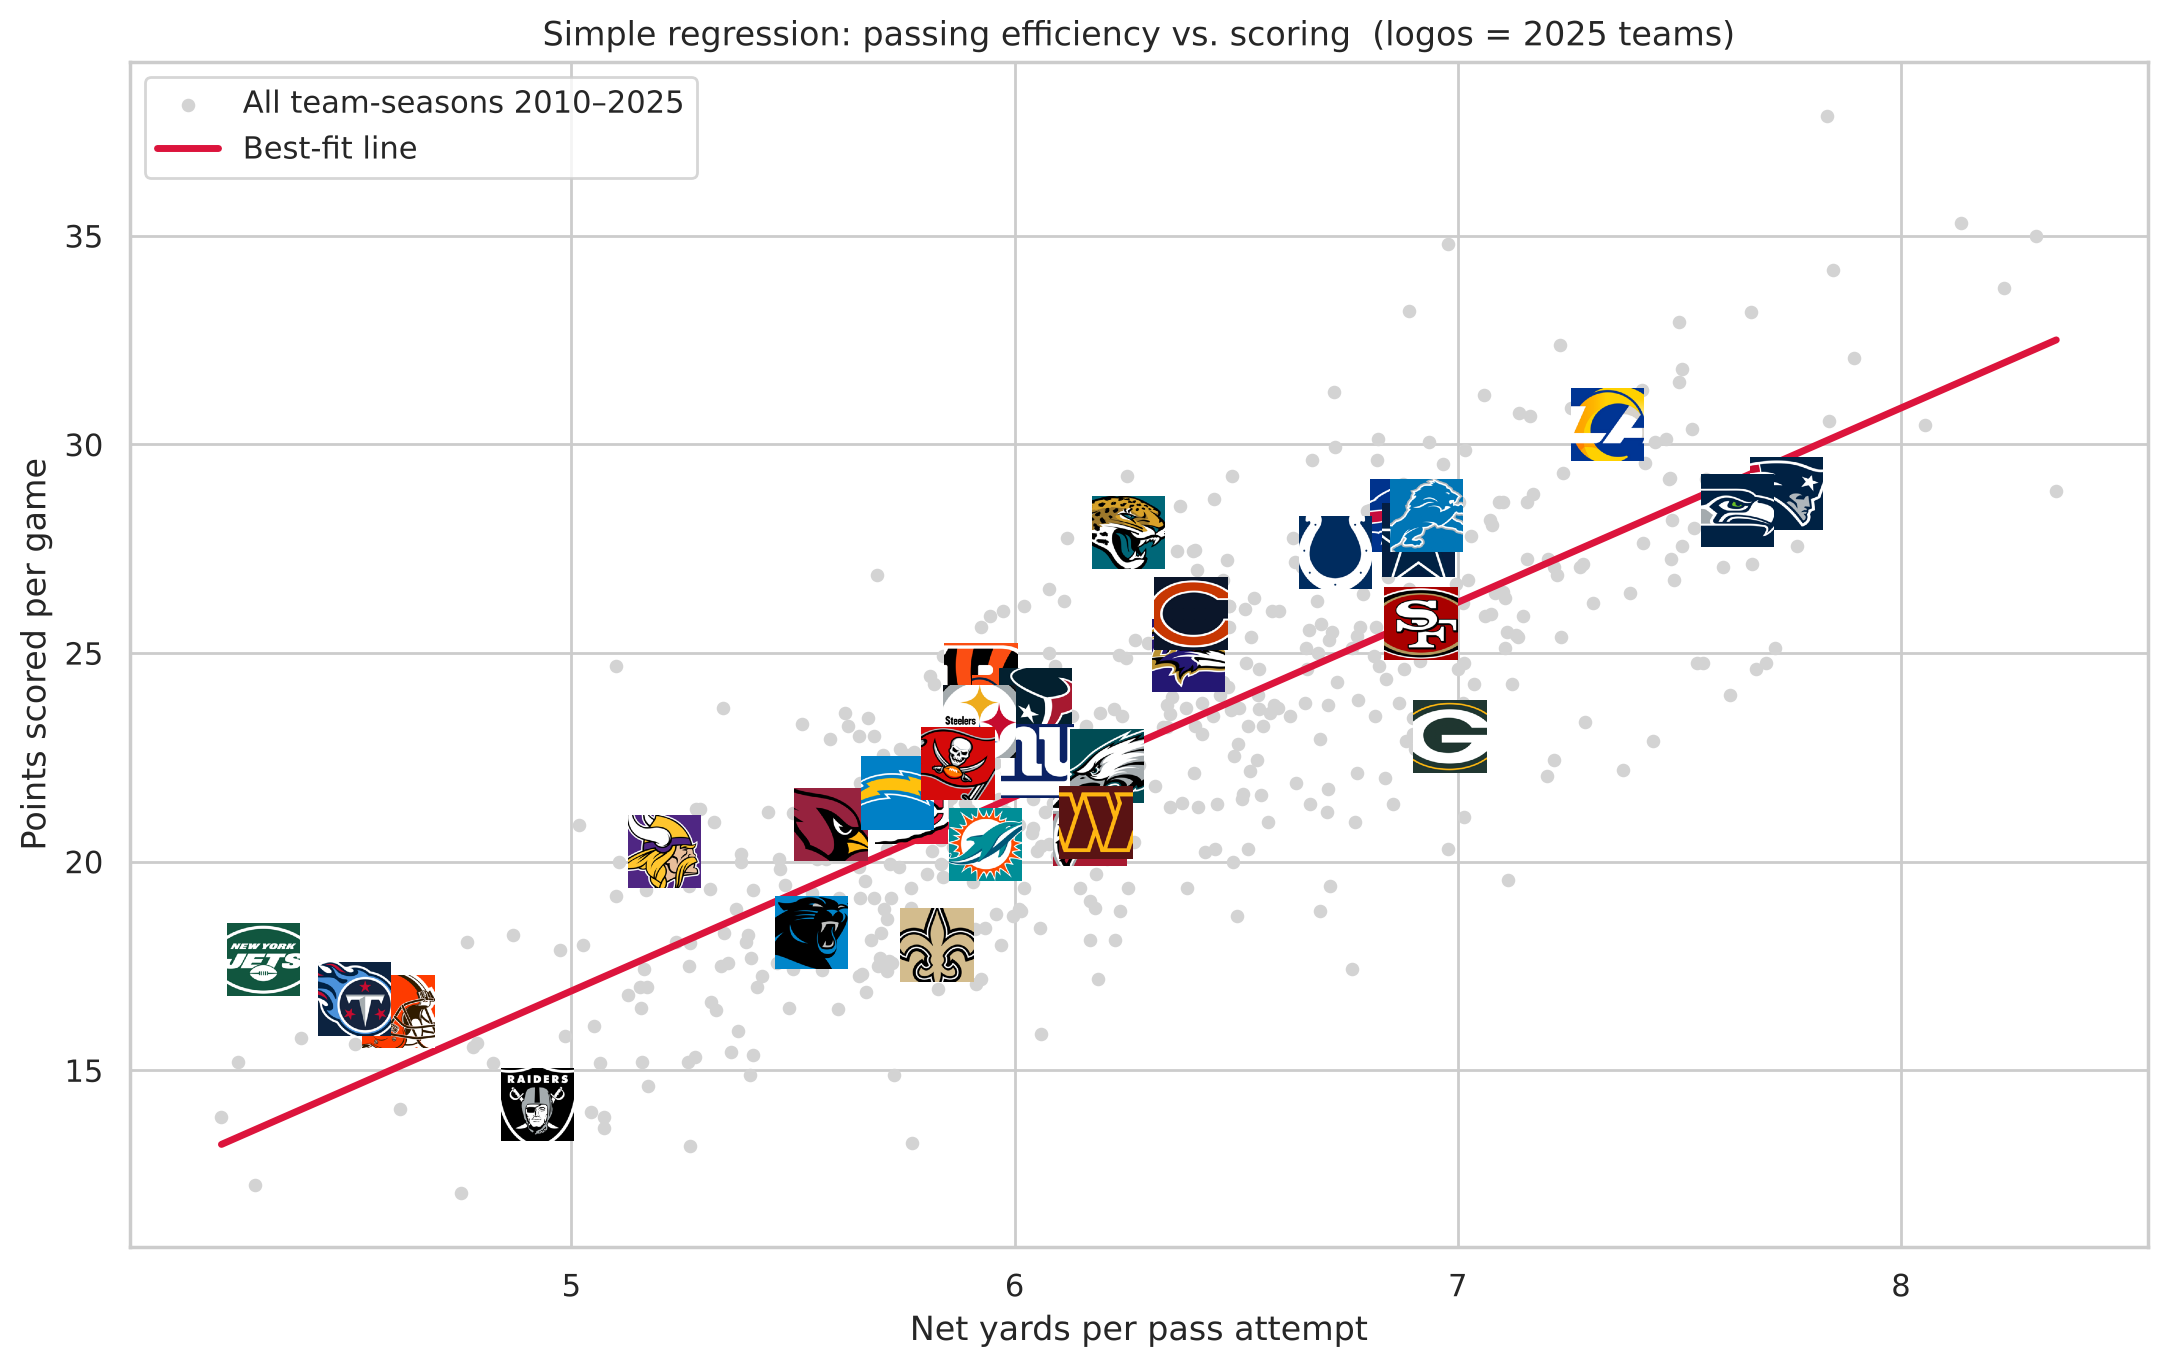

In [11]:
simple = smf.ols("ppg ~ off_ny_a", data=full).fit()
b0, b1 = simple.params["Intercept"], simple.params["off_ny_a"]
print(f"Fitted line:  points per game = {b0:.2f} + {b1:.2f} × (net yards per pass attempt)")
print(f"R² = {simple.rsquared:.2f}  →  passing efficiency alone explains {simple.rsquared:.0%} of the differences in scoring")

LAST_FULL = CURRENT_SEASON - 1
fig, ax = plt.subplots(figsize=(11, 7))
ax.scatter(full.off_ny_a, full.ppg, color="lightgray", s=15, label="All team-seasons 2010–2025")
xs = np.linspace(full.off_ny_a.min(), full.off_ny_a.max(), 50)
ax.plot(xs, b0 + b1 * xs, color="crimson", lw=2.5, label="Best-fit line")
for _, r in full[full.season == LAST_FULL].iterrows():
    add_logo(ax, r.team, r.off_ny_a, r.ppg, zoom=0.22)
ax.set(xlabel="Net yards per pass attempt", ylabel="Points scored per game",
       title=f"Simple regression: passing efficiency vs. scoring  (logos = {LAST_FULL} teams)")
ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

### ✏️ Try it: predict a team's scoring by hand
Pick a team, plug its stat into the line, and compare with what really happened. The difference between actual and predicted is the **residual**.

In [12]:
MY_TEAM = "DET"     # ✏️ change to any team code, e.g. "KC", "SF", "BUF"
SEASON  = LAST_FULL # ✏️ or any season from 2010 to 2025

row = full[(full.season == SEASON) & (full.team == MY_TEAM)].iloc[0]
pred = b0 + b1 * row.off_ny_a
print(f"{SEASON} {MY_TEAM}: {row.off_ny_a:.2f} net yards per pass attempt")
print(f"Prediction = {b0:.2f} + {b1:.2f} × {row.off_ny_a:.2f} = {pred:.1f} points per game")
print(f"Actual     = {row.ppg:.1f} points per game")
print(f"Residual   = actual − predicted = {row.ppg - pred:+.1f}")

2025 DET: 6.93 net yards per pass attempt
Prediction = -6.39 + 4.66 × 6.93 = 25.9 points per game
Actual     = 28.3 points per game
Residual   = actual − predicted = +2.4


> 🔍 **Check your understanding:** In words, what does the slope b₁ mean?

<details><summary><b>Click to reveal the answer</b></summary>

Teams that gain one more net yard per pass attempt score about b₁ (roughly 5) more points per game, on average. It describes an association across teams, not a guarantee for any single team.

</details>

## Part 4 · Multiple linear regression: many stats at once

Passing isn't everything. **Multiple regression** uses several stats together:

$$\text{ppg} = b_0 + b_1(\text{pass eff.}) + b_2(\text{rush eff.}) + b_3(\text{giveaways}) + b_4(\text{sack rate}) + b_5(\text{penalty yds})$$

💡 **Key idea:** each coefficient now means *the effect of that stat **holding the others constant***. That is different from the simple slope, which mixed in everything that comes along with good passing.

### Train and test
We **train** (fit) the models on 2010–2023 and keep 2024–2025 hidden as a **test set**. Later we check how well the model predicts seasons it has never seen. That is the honest way to judge a model.

We fit two offense models: **Model A** (efficiency stats) and **Model B** (adds first downs). The table below is `statsmodels`' full summary. Focus on the `coef` and `P>|z|` columns.

In [13]:
train = full[~full.season.isin(TEST_SEASONS)].reset_index(drop=True)
test  = full[ full.season.isin(TEST_SEASONS)].reset_index(drop=True)

# The same franchise shows up every season, so its rows aren't independent.
# Clustering standard errors by team gives more honest p-values / CIs (coefficients are unchanged).
def fit(formula, data=train):
    return smf.ols(formula, data=data).fit(cov_type="cluster", cov_kwds={"groups": data["team"]})

off_A = fit("ppg ~ off_ny_a + off_ypc + off_to_pg + off_sack_rate + off_pen_ypg")
off_B = fit("ppg ~ off_ny_a + off_ypc + off_to_pg + off_sack_rate + off_pen_ypg + off_fd_pg")

print(off_A.summary())

                            OLS Regression Results                            
Dep. Variable:                    ppg   R-squared:                       0.698
Model:                            OLS   Adj. R-squared:                  0.694
Method:                 Least Squares   F-statistic:                     219.0
Date:                Mon, 16 Nov 2026   Prob (F-statistic):           3.26e-23
Time:                        22:56:54   Log-Likelihood:                -1027.1
No. Observations:                 448   AIC:                             2066.
Df Residuals:                     442   BIC:                             2091.
Df Model:                           5                                         
Covariance Type:              cluster                                         
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept        -3.1752      1.921     -1.653

### Reading the coefficients
Here are Model A's coefficients in friendlier units, with 95% **confidence intervals** (the plausible range for each effect) and **p-values** (below 0.05 usually means we can't blame the effect on chance).

* `off_ny_a`: **+1 net yard per pass attempt** ≈ **+3.8 points per game**
* `off_to_pg`: **+1 giveaway per game** ≈ **−1.8 points per game**
* `off_sack_rate`: shown per **+1 percentage point** of sack rate

In [14]:
def coef_table(model, scale=None):
    """Coefficient table with 95% CIs. `scale` lets us express effects per a sensible unit."""
    t = pd.DataFrame({"coef": model.params, "ci_low": model.conf_int()[0],
                      "ci_high": model.conf_int()[1], "p_value": model.pvalues}).drop("Intercept")
    if scale:
        for var, (factor, unit) in scale.items():
            if var in t.index:
                t.loc[var, ["coef", "ci_low", "ci_high"]] *= factor
                t.loc[var, "unit"] = unit
    t["variable"] = t.index.map(labels)
    return t[["variable", "unit", "coef", "ci_low", "ci_high", "p_value"]]

OFF_UNITS = {"off_ny_a": (1, "+1 yd/att"), "off_ypc": (1, "+1 yd/carry"),
             "off_to_pg": (1, "+1 giveaway/gm"), "off_sack_rate": (0.01, "+1 pct-pt"),
             "off_pen_ypg": (10, "+10 pen yds/gm"), "off_fd_pg": (1, "+1 first down/gm")}

print("Model A — points per game change per unit:")
display(coef_table(off_A, OFF_UNITS))

print(f"\nModel A R²: {off_A.rsquared:.3f}    Model B R²: {off_B.rsquared:.3f}")
print(f"Passing coefficient — A: {off_A.params['off_ny_a']:.2f}   B: {off_B.params['off_ny_a']:.2f}")

Model A — points per game change per unit:


,variable,unit,coef,ci_low,ci_high,p_value
off_ny_a,Net yards / pass att,+1 yd/att,3.818,3.358,4.278,0.000
off_ypc,Yards / carry,+1 yd/carry,1.848,1.373,2.324,0.000
off_to_pg,Giveaways / game,+1 giveaway/gm,-1.844,-2.572,-1.117,0.000
off_sack_rate,Sack rate (taken),+1 pct-pt,-0.352,-0.519,-0.185,0.000
off_pen_ypg,Penalty yards / game,+10 pen yds/gm,-0.210,-0.440,0.019,0.072



Model A R²: 0.698    Model B R²: 0.770
Passing coefficient — A: 3.82   B: 2.38


> 🔍 **Check your understanding:** The passing coefficient is about 5 in the simple regression (Part 3) but about 3.8 here. Why did it shrink?

<details><summary><b>Click to reveal the answer</b></summary>

Good passing teams also tend to run well and turn the ball over less. The simple slope gave passing credit for all of that. With those stats in the model, the passing coefficient only measures passing itself.

</details>

### ✏️ Try it: a multiple-regression prediction by hand
A prediction is just **each coefficient × the team's value, all added up**.

In [15]:
MY_TEAM, SEASON = "DET", LAST_FULL   # ✏️ change these

row = full[(full.season == SEASON) & (full.team == MY_TEAM)].iloc[0]
parts = pd.DataFrame({"coefficient": off_A.params})
parts["team value"] = [1.0 if v == "Intercept" else row[v] for v in parts.index]
parts["coef × value"] = parts["coefficient"] * parts["team value"]
parts.index = ["Intercept"] + [labels[v] for v in parts.index[1:]]
display(parts.round(3))
print(f"Sum = predicted points per game = {parts['coef × value'].sum():.1f}")
print(f"Actual points per game          = {row.ppg:.1f}")

,coefficient,team value,coef × value
Intercept,-3.175,1.000,-3.175
Net yards / pass att,3.818,6.929,26.454
Yards / carry,1.848,4.618,8.535
Giveaways / game,-1.844,0.882,-1.627
Sack rate (taken),-35.181,0.063,-2.209
Penalty yards / game,-0.021,42.235,-0.889


Sum = predicted points per game = 27.1
Actual points per game          = 28.3


> **Why does the passing coefficient drop again in Model B?** Good passing *creates* first downs, which create points. Once first downs are in the model, passing only gets credit for what it does *beyond* first downs. If you want the **total** value of passing, don't control for something passing causes.

### The defense model
Same idea, but the outcome is **points allowed**, so **negative coefficients are good** for a defense.

In [16]:
def_A = fit("papg ~ def_ny_a + def_ypc + def_to_pg + def_sack_rate")
print(def_A.summary())

DEF_UNITS = {"def_ny_a": (1, "+1 yd/att allowed"), "def_ypc": (1, "+1 yd/carry allowed"),
             "def_to_pg": (1, "+1 takeaway/gm"), "def_sack_rate": (0.01, "+1 pct-pt"),
             "def_fd_pg": (1, "+1 first down/gm allowed")}
display(coef_table(def_A, DEF_UNITS))

                            OLS Regression Results                            
Dep. Variable:                   papg   R-squared:                       0.579
Model:                            OLS   Adj. R-squared:                  0.575
Method:                 Least Squares   F-statistic:                     203.7
Date:                Mon, 16 Nov 2026   Prob (F-statistic):           8.81e-22
Time:                        22:56:54   Log-Likelihood:                -999.63
No. Observations:                 448   AIC:                             2009.
Df Residuals:                     443   BIC:                             2030.
Df Model:                           4                                         
Covariance Type:              cluster                                         
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept        -2.6169      2.371     -1.104

,variable,unit,coef,ci_low,ci_high,p_value
def_ny_a,Net yds / pass att ALLOWED,+1 yd/att allowed,3.619,3.158,4.079,0.000
def_ypc,Yards / carry ALLOWED,+1 yd/carry allowed,1.291,0.578,2.004,0.000
def_to_pg,Takeaways / game,+1 takeaway/gm,-2.134,-2.768,-1.501,0.000
def_sack_rate,Sack rate (made),+1 pct-pt,0.001,-0.162,0.164,0.994


### Offense vs. defense, on the same scale
Raw coefficients can't be compared directly (a yard per attempt isn't the same as a percentage point of sacks). So we **standardize**: what is a **one-standard-deviation** improvement in each stat worth in points per game? Positive bars always mean "helps the team".

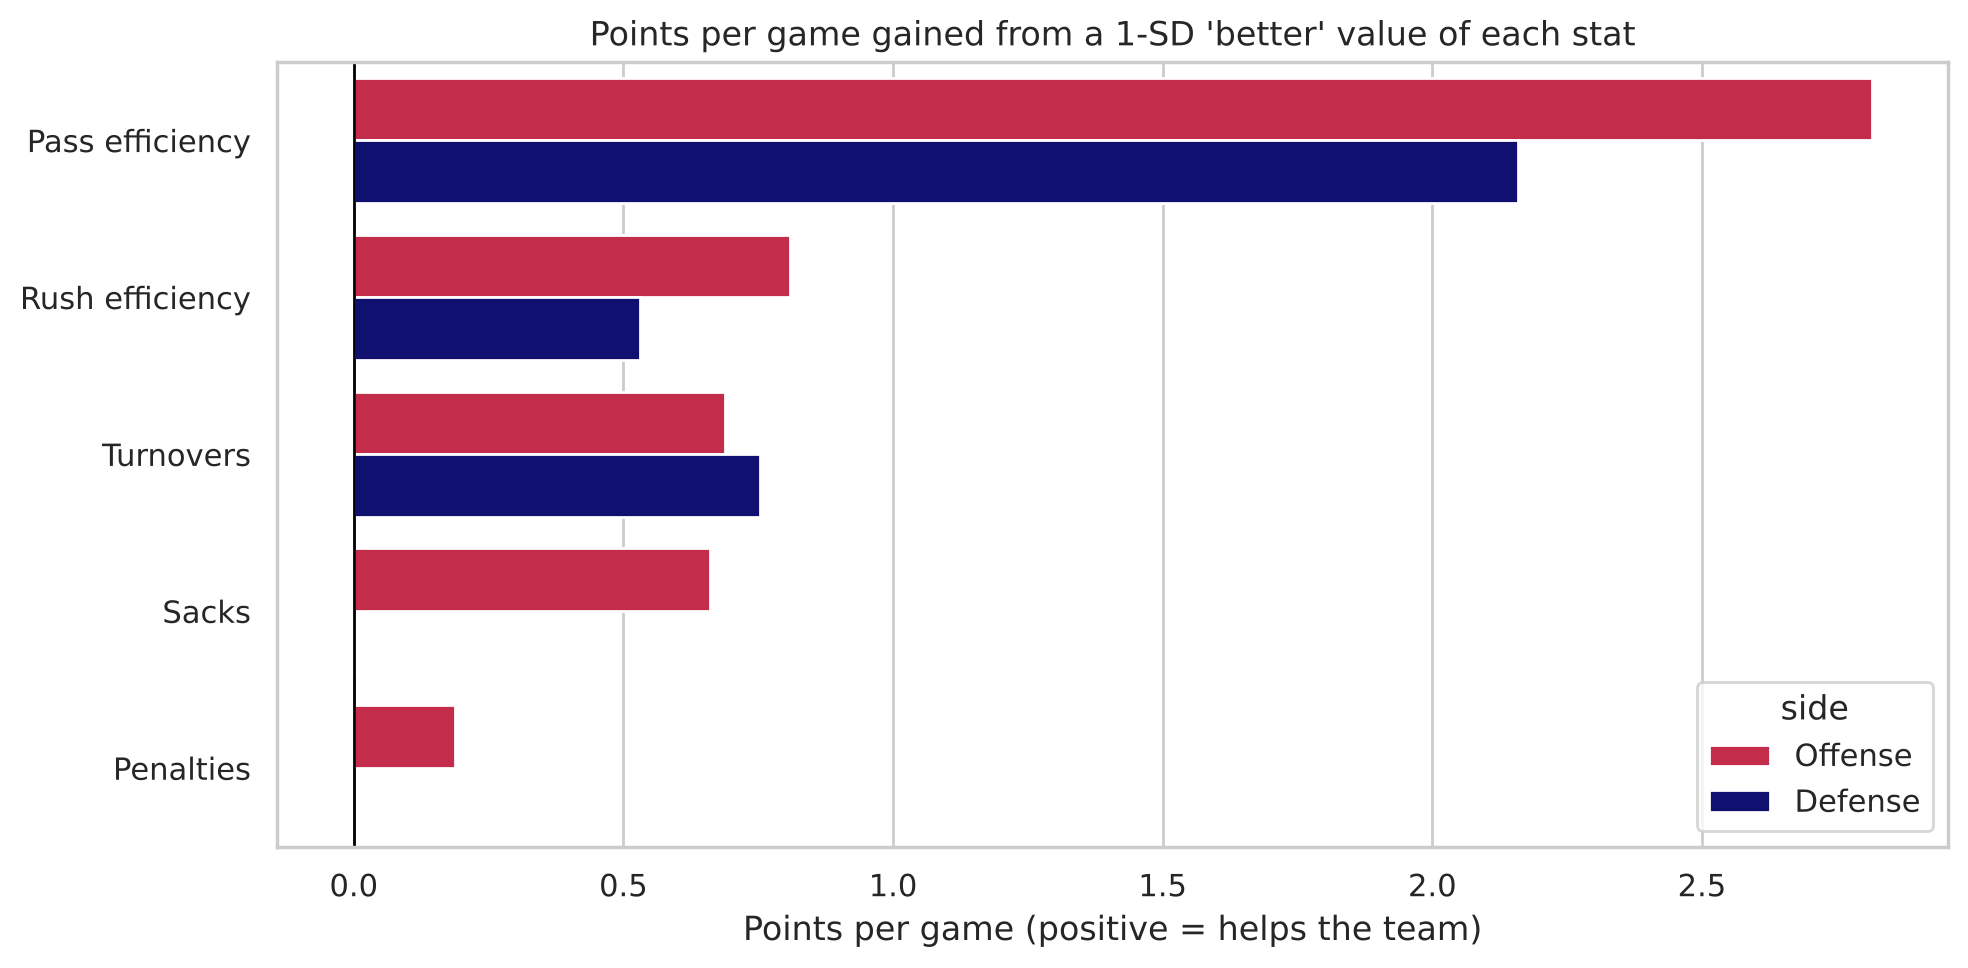

side,Defense,Offense
skill,,
Pass efficiency,2.159,2.815
Penalties,NaN,0.188
Rush efficiency,0.531,0.810
Sacks,-0.001,0.660
Turnovers,0.753,0.688


In [17]:
def standardized(formula, data):
    preds = [v.strip() for v in formula.split("~")[1].split("+")]
    z = data.copy()
    z[preds] = (z[preds] - z[preds].mean()) / z[preds].std()
    return smf.ols(formula, data=z).fit().params.drop("Intercept")

# +1 if a HIGHER value of the stat is better for the team, -1 if lower is better
better = {"off_ny_a": 1, "off_ypc": 1, "off_to_pg": -1, "off_sack_rate": -1, "off_pen_ypg": -1,
          "def_ny_a": -1, "def_ypc": -1, "def_to_pg": 1, "def_sack_rate": 1}

off_std = standardized("ppg ~ off_ny_a + off_ypc + off_to_pg + off_sack_rate + off_pen_ypg", train)
def_std = -standardized("papg ~ def_ny_a + def_ypc + def_to_pg + def_sack_rate", train)  # fewer allowed = good
off_std = off_std * off_std.index.map(better)
def_std = def_std * def_std.index.map(better)

skill = {"off_ny_a": "Pass efficiency", "def_ny_a": "Pass efficiency",
         "off_ypc": "Rush efficiency", "def_ypc": "Rush efficiency",
         "off_to_pg": "Turnovers", "def_to_pg": "Turnovers",
         "off_sack_rate": "Sacks", "def_sack_rate": "Sacks", "off_pen_ypg": "Penalties"}

comp = pd.concat([
    pd.DataFrame({"skill": off_std.index.map(skill), "side": "Offense", "pts_per_sd": off_std.values}),
    pd.DataFrame({"skill": def_std.index.map(skill), "side": "Defense", "pts_per_sd": def_std.values}),
])

plt.figure(figsize=(10, 5))
sns.barplot(data=comp, y="skill", x="pts_per_sd", hue="side", palette={"Offense": "crimson", "Defense": "navy"})
plt.axvline(0, color="black", lw=1)
plt.title("Points per game gained from a 1-SD 'better' value of each stat")
plt.xlabel("Points per game (positive = helps the team)"); plt.ylabel("")
plt.tight_layout(); plt.show()

comp.pivot(index="skill", columns="side", values="pts_per_sd")

> 🔍 **Check your understanding:** Which skill matters most on both sides of the ball? Is rushing more or less important than you expected?

<details><summary><b>Click to reveal the answer</b></summary>

Passing efficiency is the biggest by far on both offense and defense, followed by turnovers. Rushing efficiency matters much less than many fans expect.

</details>

### Does the model work on seasons it has never seen?
We now score the models on the hidden 2024–2025 seasons. The **baseline** is guessing the league average for every team; a useful model must beat it.

* **R²**: share of the differences between teams the model explains (1 = perfect)
* **MAE** (mean absolute error): how far off the predictions are, on average, in points per game

In [18]:
def evaluate(model, data, y):
    pred = model.predict(data)
    return {"R² (test)": r2_score(data[y], pred),
            "MAE (test)": mean_absolute_error(data[y], pred),
            "Baseline MAE": mean_absolute_error(data[y], np.full(len(data), train[y].mean())),
            "R² (train)": model.rsquared}

pd.DataFrame({
    "Offense A (efficiency)": evaluate(off_A, test, "ppg"),
    "Offense B (+first downs)": evaluate(off_B, test, "ppg"),
    "Defense A": evaluate(def_A, test, "papg"),
}).T

,R² (test),MAE (test),Baseline MAE,R² (train)
Offense A (efficiency),0.766,1.633,3.455,0.698
Offense B (+first downs),0.835,1.446,3.455,0.770
Defense A,0.638,1.587,2.685,0.579


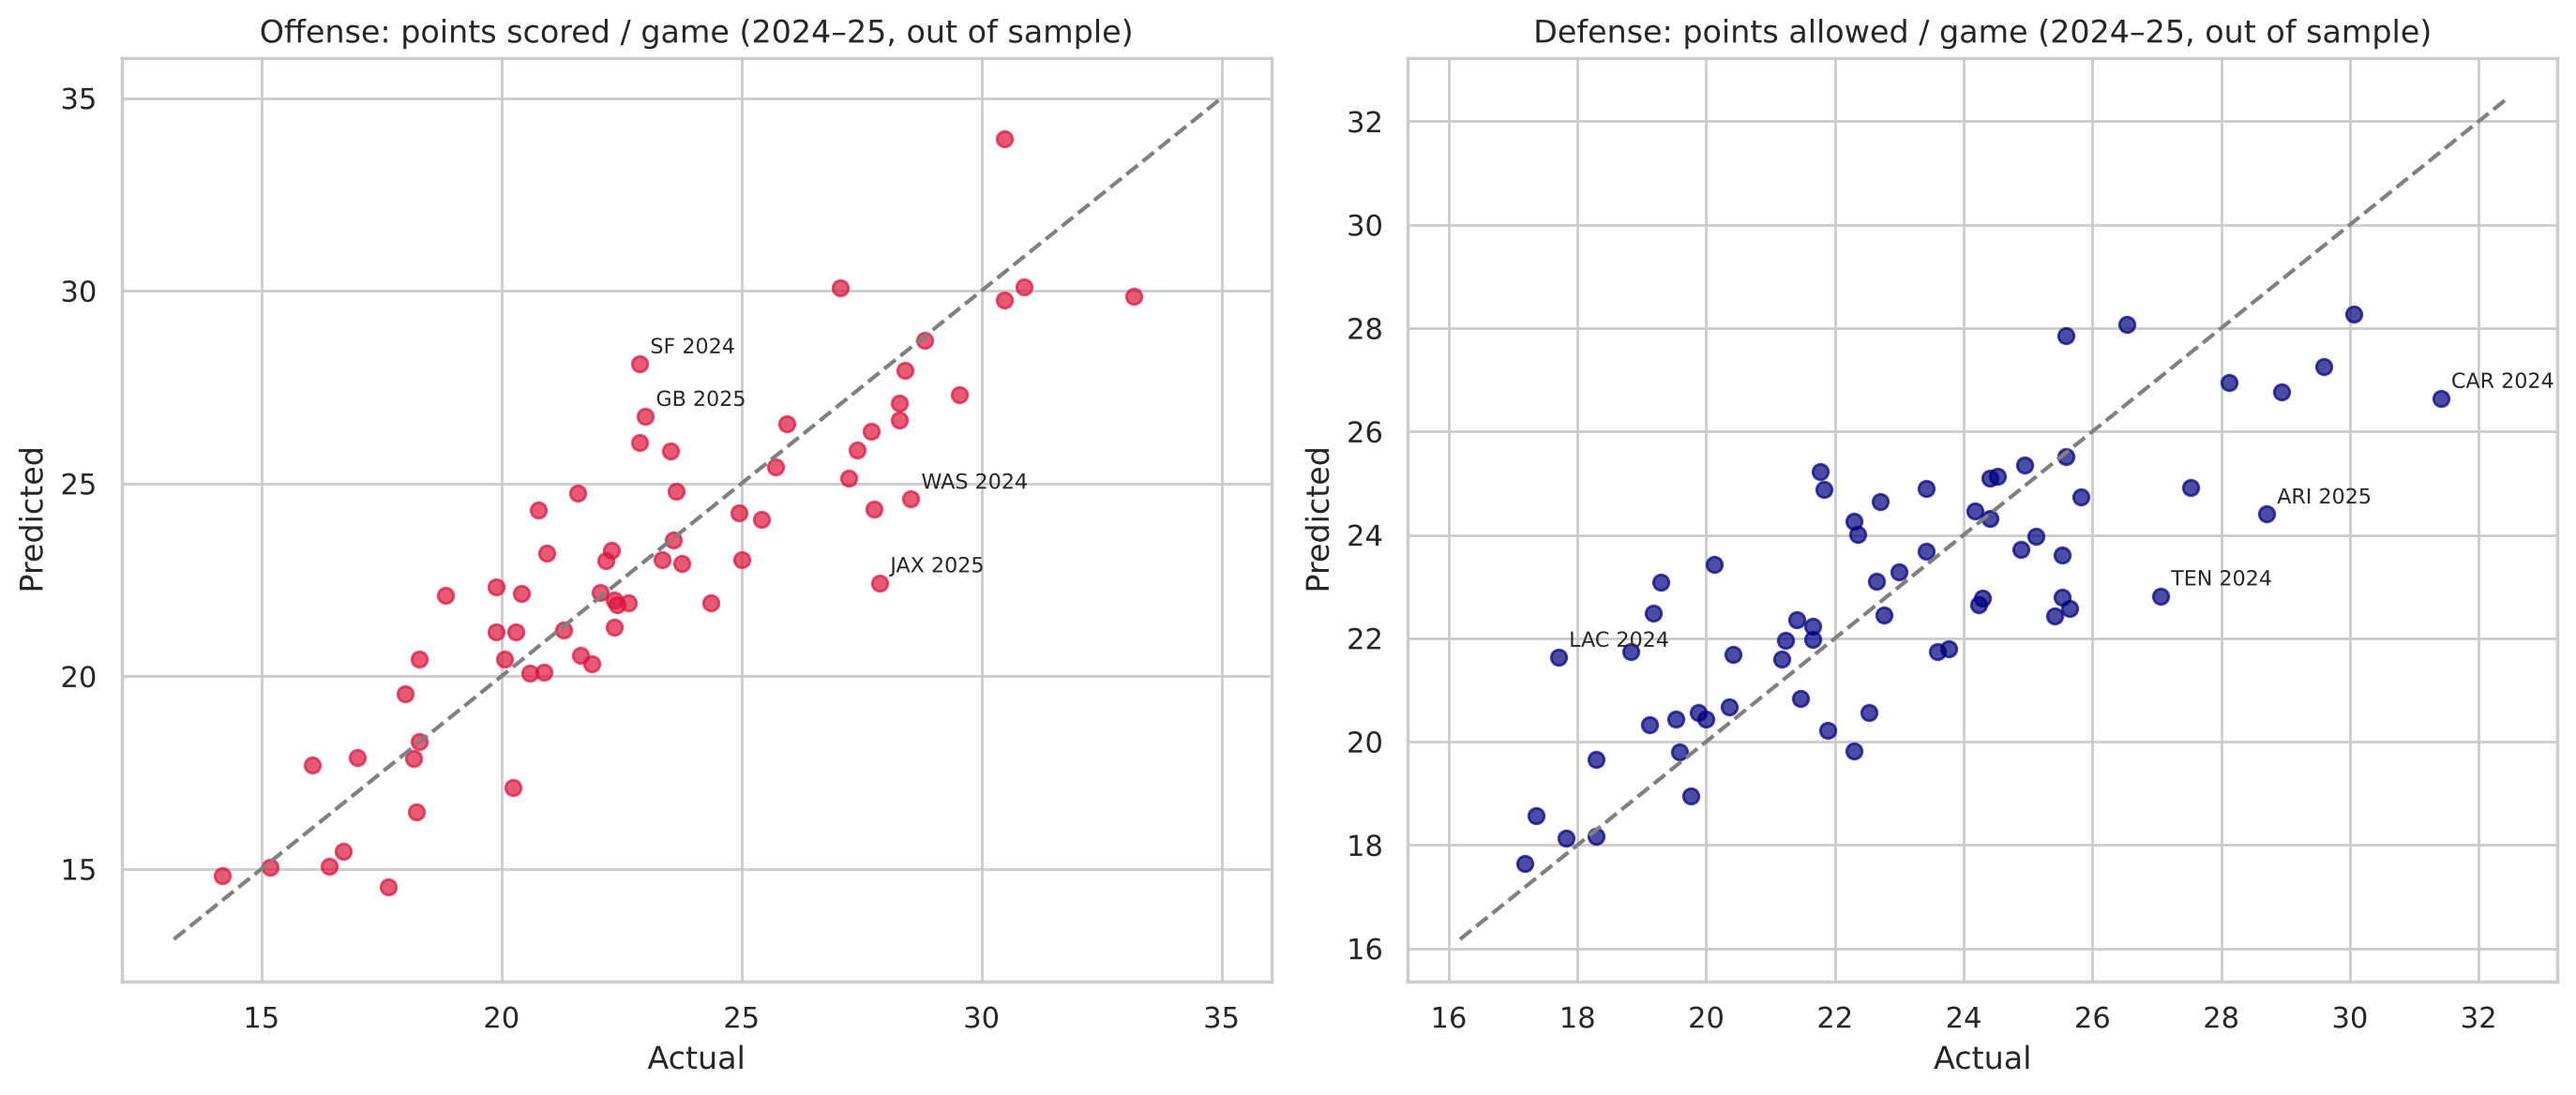

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, model, y, title, color in [
    (axes[0], off_A, "ppg",  "Offense: points scored / game", "crimson"),
    (axes[1], def_A, "papg", "Defense: points allowed / game", "navy")]:
    pred = model.predict(test)
    ax.scatter(test[y], pred, alpha=.7, color=color)
    lo, hi = min(test[y].min(), pred.min()) - 1, max(test[y].max(), pred.max()) + 1
    ax.plot([lo, hi], [lo, hi], "--", color="gray")
    for _, r in test.assign(pred=pred).assign(err=lambda d: (d[y] - d.pred).abs()).nlargest(4, "err").iterrows():
        ax.annotate(f"{r.team} {r.season}", (r[y], r.pred), fontsize=8, xytext=(4, 4), textcoords="offset points")
    ax.set(title=f"{title} (2024–25, out of sample)", xlabel="Actual", ylabel="Predicted")
plt.tight_layout(); plt.show()

> Teams far from the dashed line scored more (or less) than their stats suggest. Common reasons: red-zone efficiency, defensive or return touchdowns, field position, and luck in close games. None of those are in our model.

## Part 5 · From points to wins

### Offense + defense → point differential

In [20]:
combo = fit("diff_pg ~ off_ny_a + off_ypc + off_to_pg + off_sack_rate + off_pen_ypg"
            " + def_ny_a + def_ypc + def_to_pg + def_sack_rate")
display(coef_table(combo, {**OFF_UNITS, **DEF_UNITS}))
print(f"Train R²: {combo.rsquared:.3f}   Test R²: {r2_score(test.diff_pg, combo.predict(test)):.3f}")

,variable,unit,coef,ci_low,ci_high,p_value
off_ny_a,Net yards / pass att,+1 yd/att,3.933,3.457,4.410,0.000
off_ypc,Yards / carry,+1 yd/carry,1.635,0.994,2.275,0.000
off_to_pg,Giveaways / game,+1 giveaway/gm,-4.618,-5.385,-3.851,0.000
off_sack_rate,Sack rate (taken),+1 pct-pt,-0.303,-0.476,-0.130,0.001
off_pen_ypg,Penalty yards / game,+10 pen yds/gm,-0.586,-0.802,-0.371,0.000
def_ny_a,Net yds / pass att ALLOWED,+1 yd/att allowed,-3.459,-3.964,-2.954,0.000
def_ypc,Yards / carry ALLOWED,+1 yd/carry allowed,-1.768,-2.343,-1.192,0.000
def_to_pg,Takeaways / game,+1 takeaway/gm,4.650,3.889,5.411,0.000
def_sack_rate,Sack rate (made),+1 pct-pt,0.225,0.024,0.426,0.028


Train R²: 0.844   Test R²: 0.825


### Point differential → wins

Each +1 point/game of differential ≈ +0.028 win% ≈ +0.48 wins over a 17-game season.
So ~2.1 points/game of differential ≈ 1 extra win.  (R² = 0.824)


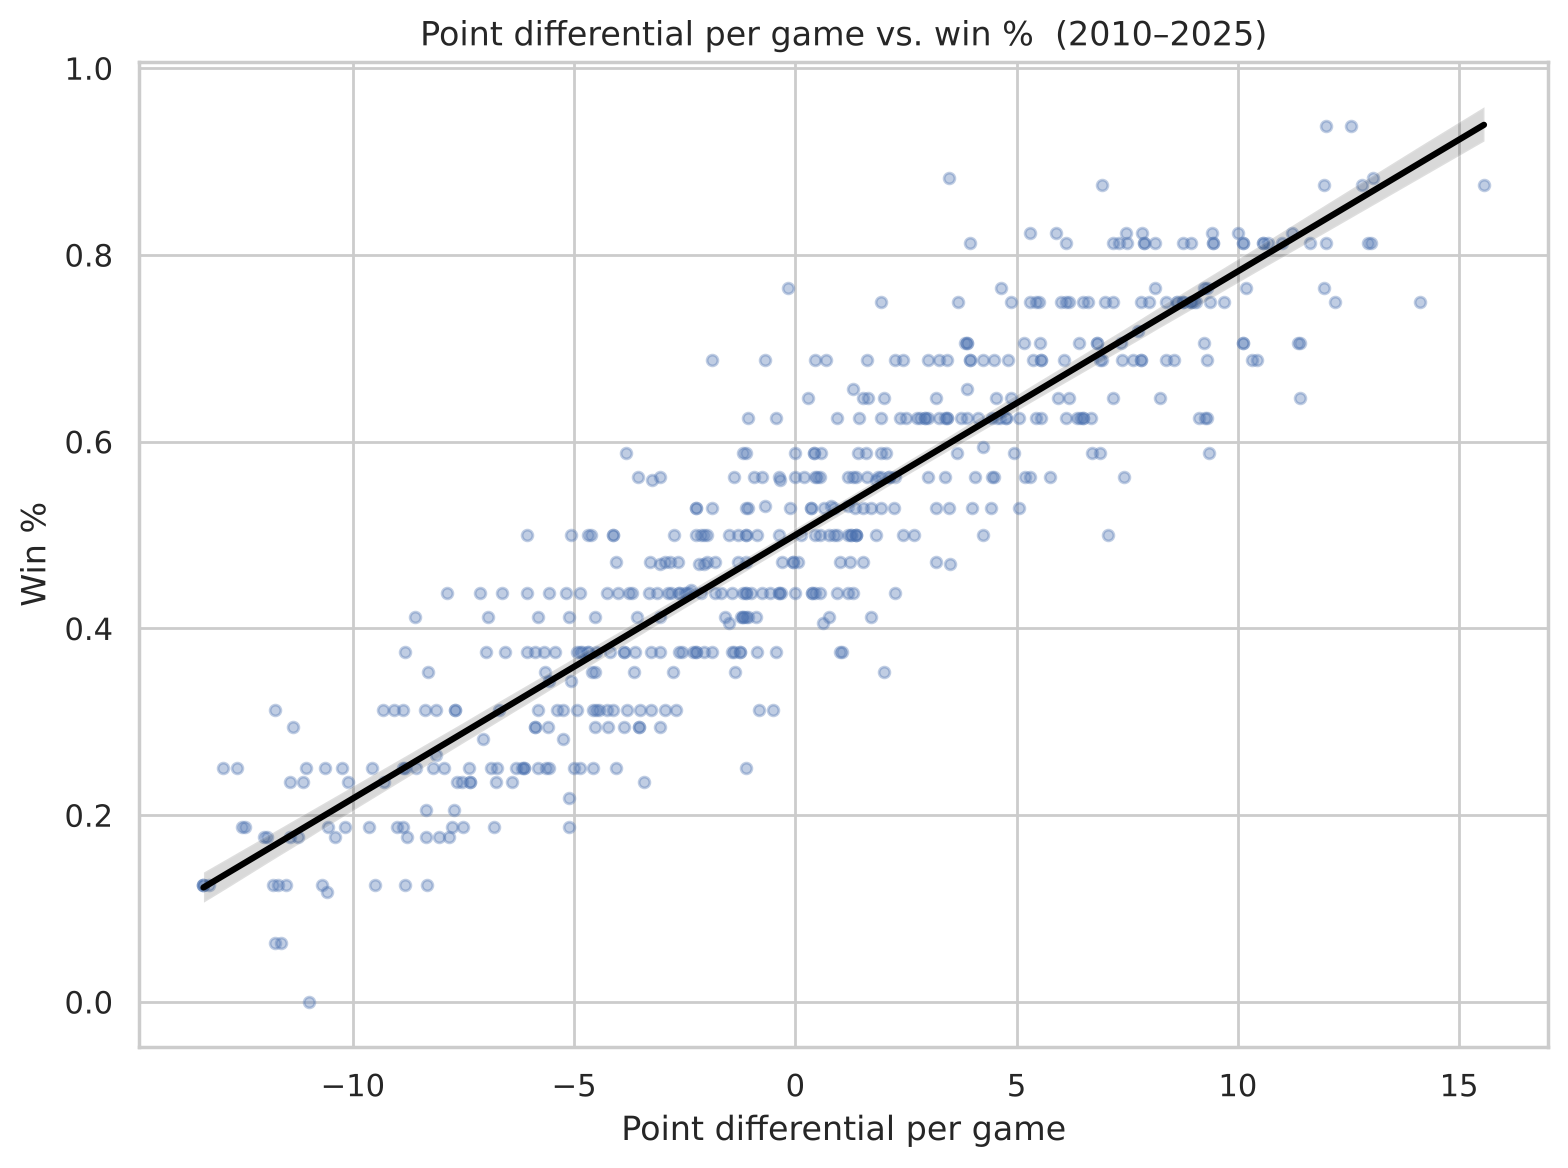

In [21]:
# How do points turn into wins?
wins = fit("win_pct ~ diff_pg")
b = wins.params["diff_pg"]
print(f"Each +1 point/game of differential ≈ +{b:.3f} win% "
      f"≈ +{b*17:.2f} wins over a 17-game season.")
print(f"So ~{1/(b*17):.1f} points/game of differential ≈ 1 extra win.  (R² = {wins.rsquared:.3f})")

plt.figure(figsize=(8, 6))
sns.regplot(data=full, x="diff_pg", y="win_pct", scatter_kws={"alpha": .35, "s": 15}, line_kws={"color": "black"})
plt.title("Point differential per game vs. win %  (2010–2025)")
plt.xlabel("Point differential per game"); plt.ylabel("Win %")
plt.tight_layout(); plt.show()

### What is a turnover worth in wins?

In [22]:
# Putting it together: what is one extra turnover per game worth in WINS?
# Turnover margin = takeaways − giveaways. A +1 margin can come from either side, so average the two effects.
per_margin = (combo.params["def_to_pg"] - combo.params["off_to_pg"]) / 2
print(f"+1 turnover margin per game ≈ {per_margin:.2f} points/game ≈ {per_margin*b*17:.1f} wins per season")
print(f"Even +0.25/game (about 4 extra over a season) ≈ {0.25*per_margin*b*17:.1f} wins")

+1 turnover margin per game ≈ 4.63 points/game ≈ 2.2 wins per season
Even +0.25/game (about 4 extra over a season) ≈ 0.6 wins


### What contributes most to winning?
Now we skip points entirely and regress **win %** directly on every offense and defense stat. Each bar is the number of **extra wins per season** from a one-standard-deviation better value.

Win % model   train R²: 0.725   test R² (2024–25): 0.716
Offense stats alone explain 49% of win % · defense stats alone explain 35%


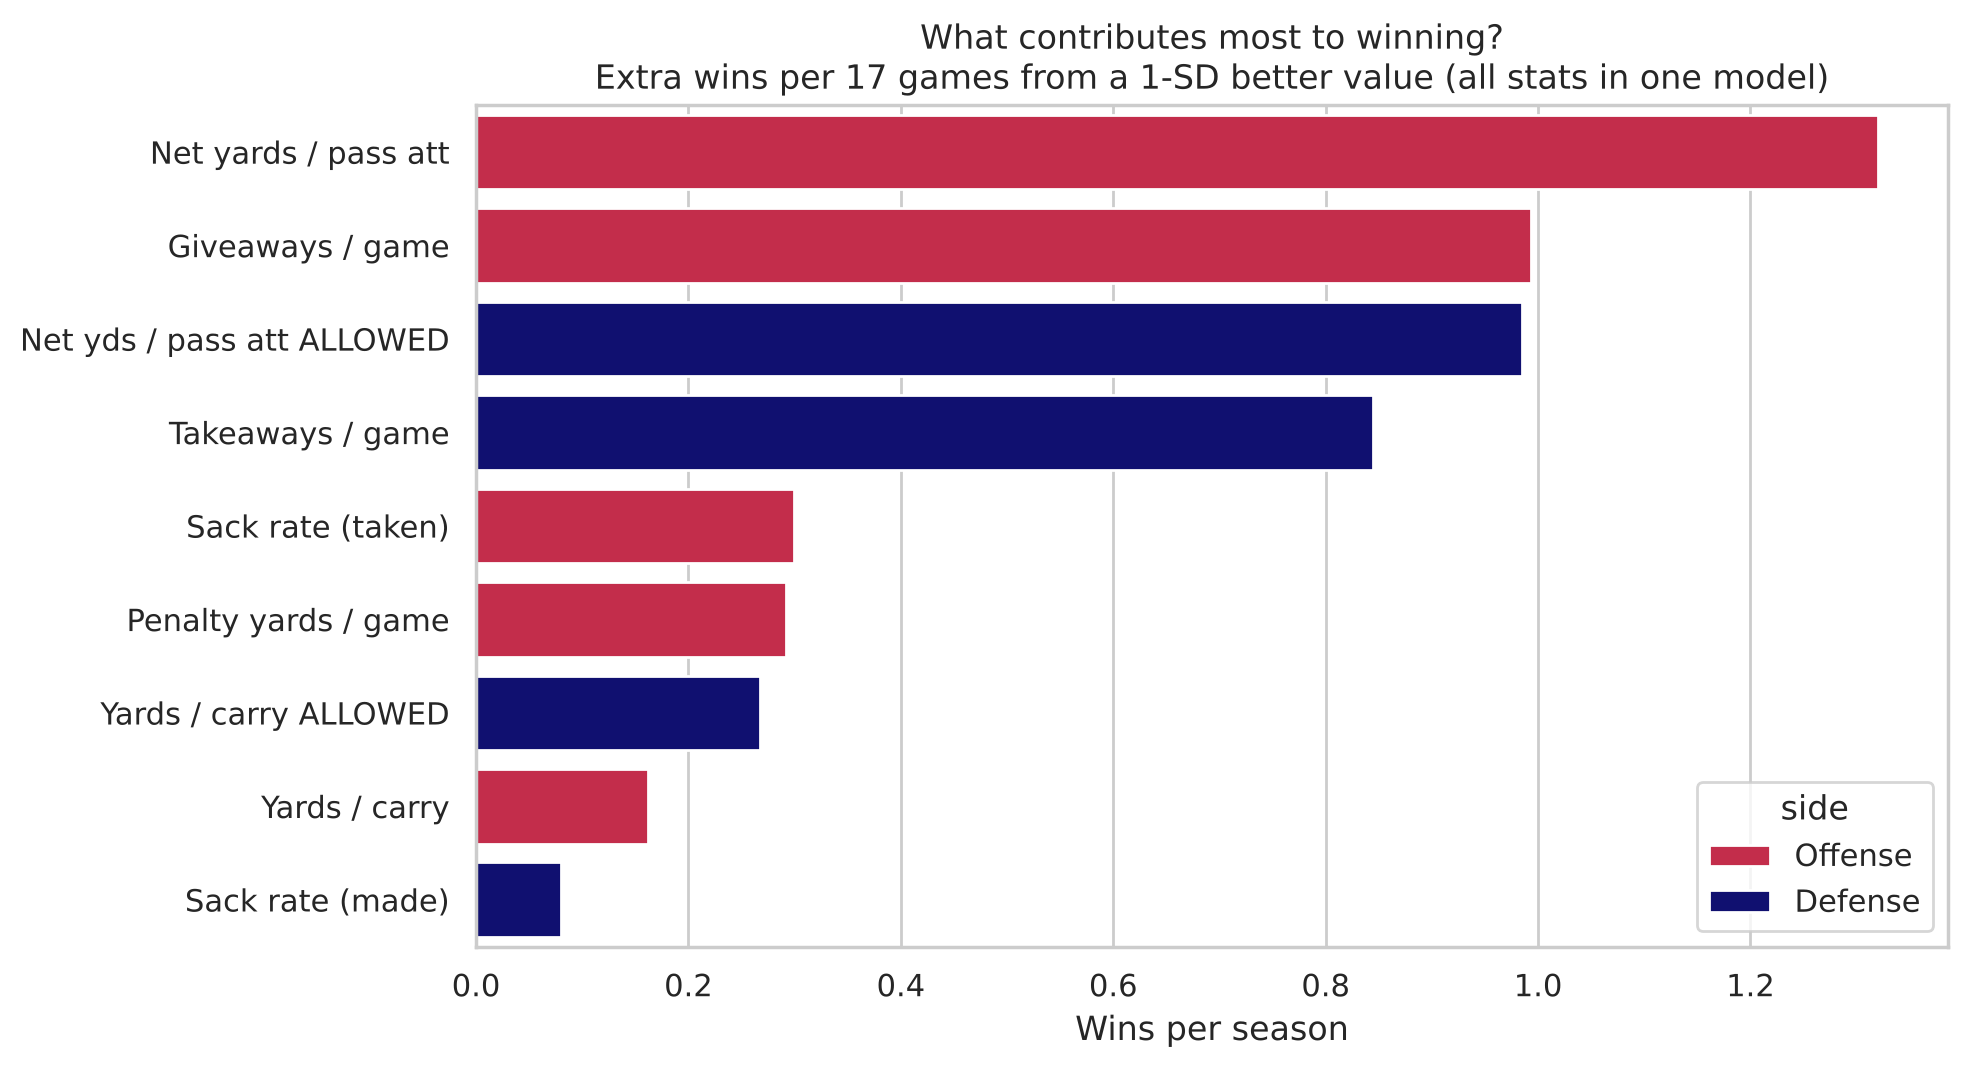

,stat,side,wins_per_sd,p_value
0,Net yards / pass att,Offense,1.320,0.000
1,Giveaways / game,Offense,0.993,0.000
2,Net yds / pass att ALLOWED,Defense,0.985,0.000
3,Takeaways / game,Defense,0.844,0.000
4,Sack rate (taken),Offense,0.299,0.000
5,Penalty yards / game,Offense,0.292,0.000
6,Yards / carry ALLOWED,Defense,0.267,0.008
7,Yards / carry,Offense,0.162,0.082
8,Sack rate (made),Defense,0.080,0.395


In [23]:
WIN_PREDS = ["off_ny_a", "off_ypc", "off_to_pg", "off_sack_rate", "off_pen_ypg",
             "def_ny_a", "def_ypc", "def_to_pg", "def_sack_rate"]

win_model = fit("win_pct ~ " + " + ".join(WIN_PREDS))
print(f"Win % model   train R²: {win_model.rsquared:.3f}   "
      f"test R² (2024–25): {r2_score(test.win_pct, win_model.predict(test)):.3f}")

# Offense alone vs. defense alone
off_only = fit("win_pct ~ " + " + ".join(p for p in WIN_PREDS if p.startswith("off")))
def_only = fit("win_pct ~ " + " + ".join(p for p in WIN_PREDS if p.startswith("def")))
print(f"Offense stats alone explain {off_only.rsquared:.0%} of win % · defense stats alone explain {def_only.rsquared:.0%}")

# coefficient × SD = effect of a 1-SD change; × better = sign so positive means "helps win"; × 17 = wins per season
sd = train[WIN_PREDS].std()
win_rank = pd.DataFrame({
    "stat":        [labels[v] for v in WIN_PREDS],
    "side":        ["Offense" if v.startswith("off") else "Defense" for v in WIN_PREDS],
    "wins_per_sd": [win_model.params[v] * sd[v] * better[v] * 17 for v in WIN_PREDS],
    "p_value":     [win_model.pvalues[v] for v in WIN_PREDS],
}).sort_values("wins_per_sd", ascending=False).reset_index(drop=True)

plt.figure(figsize=(10, 5.5))
sns.barplot(data=win_rank, y="stat", x="wins_per_sd", hue="side", dodge=False,
            palette={"Offense": "crimson", "Defense": "navy"})
plt.axvline(0, color="black", lw=1)
plt.title("What contributes most to winning?\nExtra wins per 17 games from a 1-SD better value (all stats in one model)")
plt.xlabel("Wins per season"); plt.ylabel("")
plt.tight_layout(); plt.show()

win_rank.round(3)

> 🔍 **Check your understanding:** Win % is a number between 0 and 1. What could go wrong if we used linear regression to predict the win % of an extremely good team?

<details><summary><b>Click to reveal the answer</b></summary>

A straight line has no ceiling, so it could predict more than 100% wins (or less than 0%). For season win % this rarely happens, but for a single game's yes/no outcome it's a real problem. Part 6 fixes it with logistic regression.

</details>

## Part 6 · Logistic regression: what are a team's chances of winning *right now*?

Broadcasts often show a **win probability**, for example *"Chiefs 73%"*. Where does that number come from? We are going to **build that model ourselves**.

The question: given the situation before a play (score, time left, field position, down and distance, timeouts), what is the chance the team with the ball **wins the game**?

* Each row is now **one play**, from 2016 to 2025 (about 380,000 plays)
* The outcome is **yes/no**: did the team with the ball go on to win? (`won` = 1 or 0)

### Step 1: Load play-by-play data

In [24]:
pbp_cols = ["game_id", "season", "season_type", "week", "play_id", "home_team", "away_team", "posteam", "defteam",
            "qtr", "time", "down", "ydstogo", "yardline_100", "score_differential", "game_seconds_remaining",
            "posteam_timeouts_remaining", "defteam_timeouts_remaining", "result", "wp", "wpa", "desc"]

plays = (nfl.load_pbp(seasons=list(range(2016, 2026)))
            .select(pbp_cols).to_pandas())
plays = plays[(plays.season_type == "REG")].copy()
ot_games = set(plays.loc[plays.qtr == 5, "game_id"])

# Keep regulation plays that have a down (real snaps), from games that didn't end in a tie
plays = plays[plays.posteam.notna() & plays.down.notna() & (plays.qtr <= 4) & (plays.result != 0)].copy()

# Outcome: did the team with the ball win?  (result = home score − away score at the end)
plays["won"] = np.where(plays.posteam == plays.home_team, plays.result > 0, plays.result < 0).astype(int)
plays["down"] = plays.down.astype(int)
plays["min_left"] = plays.game_seconds_remaining / 60

wp_train = plays[plays.season <= 2024]
wp_test  = plays[plays.season == 2025]
print(f"Training plays (2016–2024): {len(wp_train):,}   Test plays (2025): {len(wp_test):,}")
plays[["season", "posteam", "defteam", "qtr", "time", "down", "ydstogo", "yardline_100", "score_differential", "won"]].head()

Training plays (2016–2024): 346,689   Test plays (2025): 38,480


,season,posteam,defteam,qtr,time,down,ydstogo,yardline_100,score_differential,won
2,2016,BAL,BUF,1.000,14:57,1,10.000,86.000,0.000,1
3,2016,BAL,BUF,1.000,14:32,2,4.000,80.000,0.000,1
4,2016,BAL,BUF,1.000,14:01,1,10.000,75.000,0.000,1
5,2016,BAL,BUF,1.000,13:35,2,10.000,75.000,0.000,1
6,2016,BAL,BUF,1.000,12:54,3,1.000,66.000,0.000,1


### Step 2: Why not just use linear regression?
Let's try it. We'll predict `won` (0 or 1) from the score margin with an ordinary straight line.

Linear model: P(win) = 0.542 + 0.0263 × lead
  lead of -35 points → predicted chance of winning = -37.7%
  lead of -21 points → predicted chance of winning =  -1.0%
  lead of  +0 points → predicted chance of winning =  54.2%
  lead of +21 points → predicted chance of winning = 109.3%
  lead of +35 points → predicted chance of winning = 146.1%


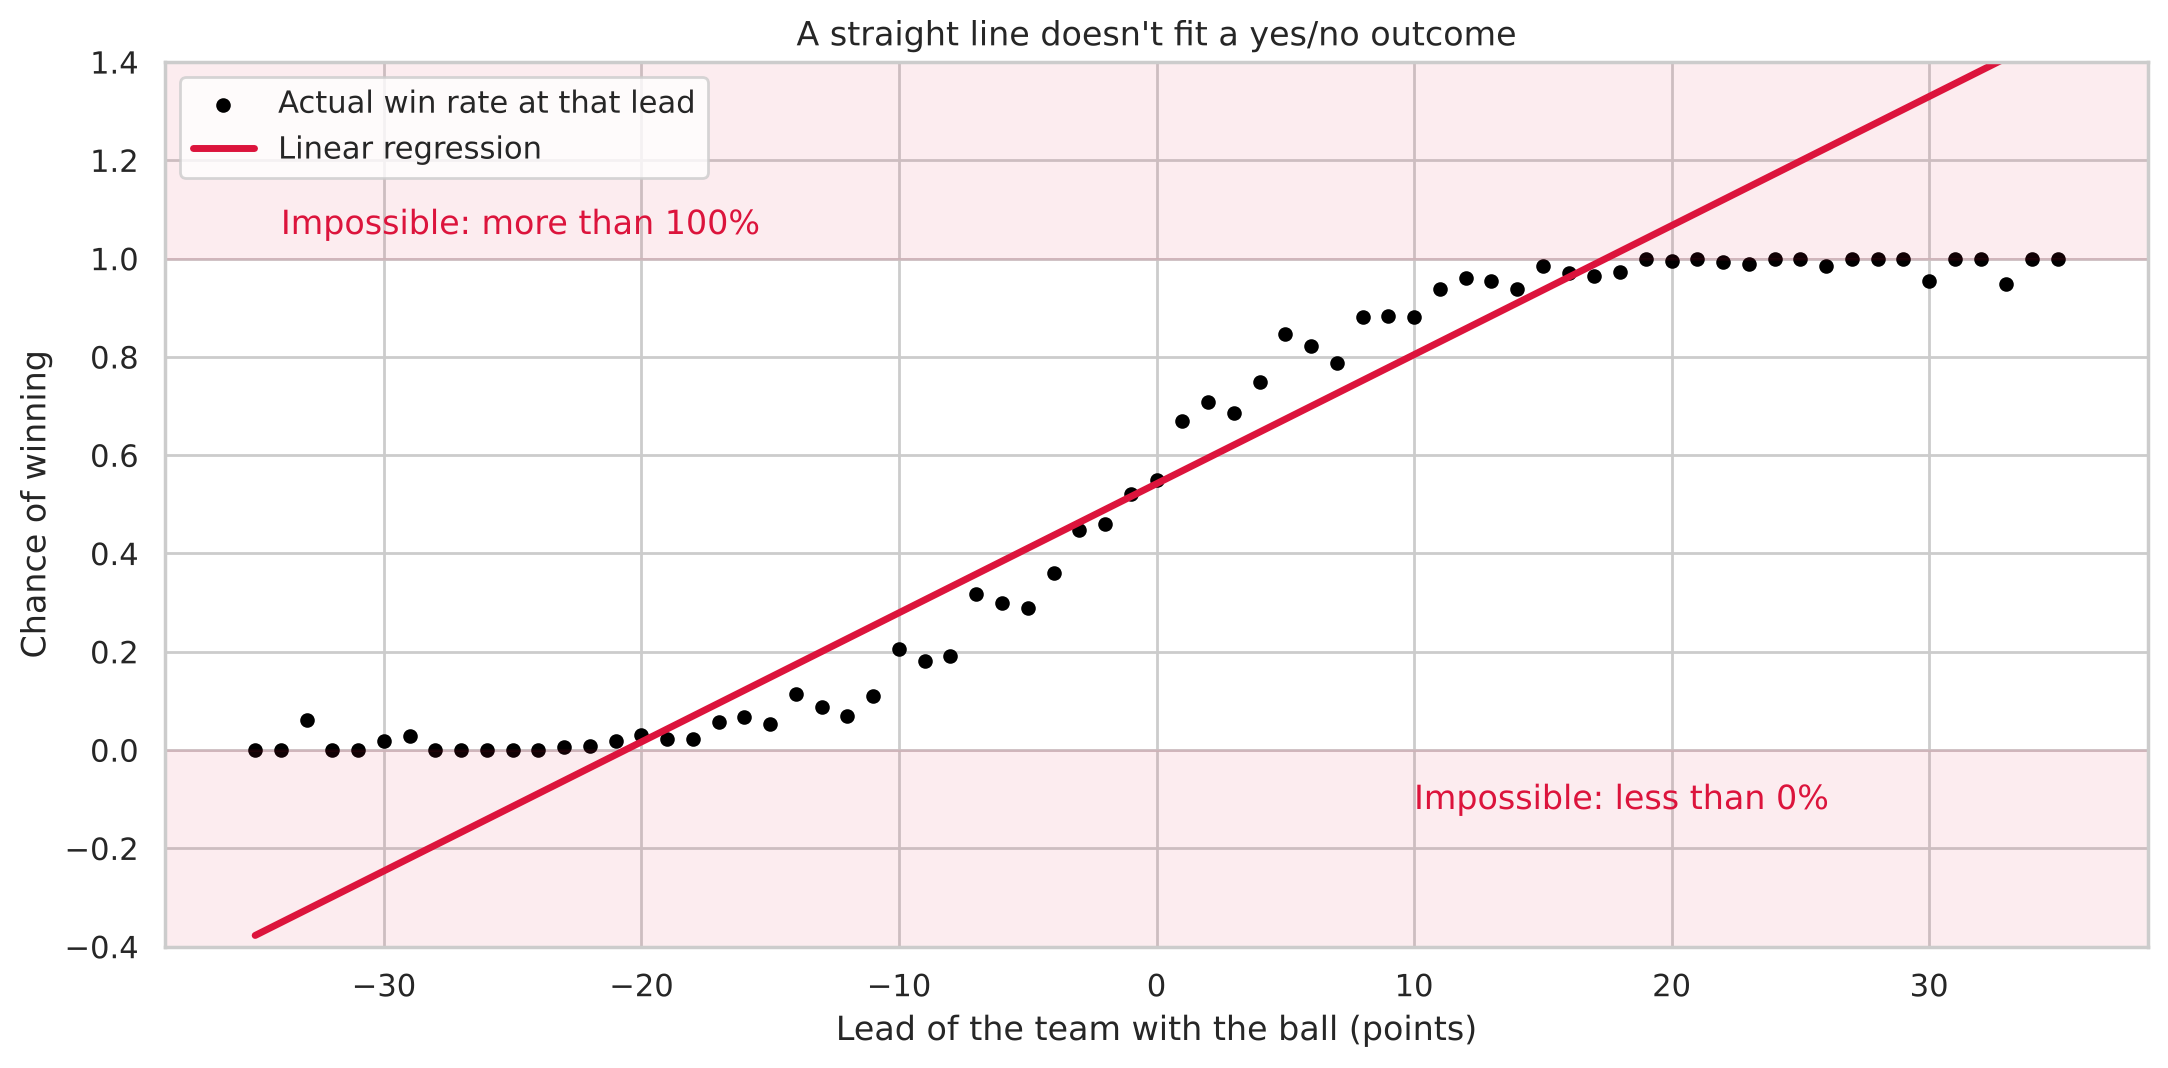

In [25]:
lpm = smf.ols("won ~ score_differential", data=wp_train).fit()
print(f"Linear model: P(win) = {lpm.params['Intercept']:.3f} + {lpm.params['score_differential']:.4f} × lead")
for lead in [-35, -21, 0, 21, 35]:
    print(f"  lead of {lead:+3d} points → predicted chance of winning = {lpm.params['Intercept'] + lpm.params['score_differential'] * lead:6.1%}")

# Actual win rate at each lead, for comparison
by_lead = wp_train[wp_train.score_differential.between(-35, 35)].groupby("score_differential").won.mean()
fig, ax = plt.subplots(figsize=(11, 5.5))
ax.scatter(by_lead.index, by_lead.values, color="black", s=18, label="Actual win rate at that lead")
xs = np.arange(-35, 36)
ax.plot(xs, lpm.params["Intercept"] + lpm.params["score_differential"] * xs, color="crimson", lw=2.5, label="Linear regression")
ax.axhspan(1, 1.6, color="crimson", alpha=.08); ax.axhspan(-0.6, 0, color="crimson", alpha=.08)
ax.text(-34, 1.05, "Impossible: more than 100%", color="crimson"); ax.text(10, -0.12, "Impossible: less than 0%", color="crimson")
ax.set(xlabel="Lead of the team with the ball (points)", ylabel="Chance of winning", ylim=(-0.4, 1.4),
       title="A straight line doesn't fit a yes/no outcome")
ax.legend(loc="upper left"); plt.tight_layout(); plt.show()

💡 **Key idea:** a probability must stay between 0 and 1, and real win chances **flatten out**: going from up 21 to up 28 barely changes anything, because you were already almost certain to win. A straight line can't bend, so it breaks.

### Step 3: The logistic (S-shaped) curve
**Logistic regression** still computes a straight-line score $z$ from the inputs, exactly like linear regression:

$$z = b_0 + b_1 x_1 + b_2 x_2 + \dots$$

Then it squeezes $z$ through the **logistic function** so the answer is always a probability between 0 and 1:

$$P(\text{win}) = \frac{1}{1 + e^{-z}}$$

| $z$ | −4 | −2 | 0 | 2 | 4 |
|---|---|---|---|---|---|
| $P$ | 2% | 12% | 50% | 88% | 98% |

The coefficients are found by **maximum likelihood**: the values that make the outcomes we actually saw as likely as possible. (It plays the role "least squares" plays in linear regression.)

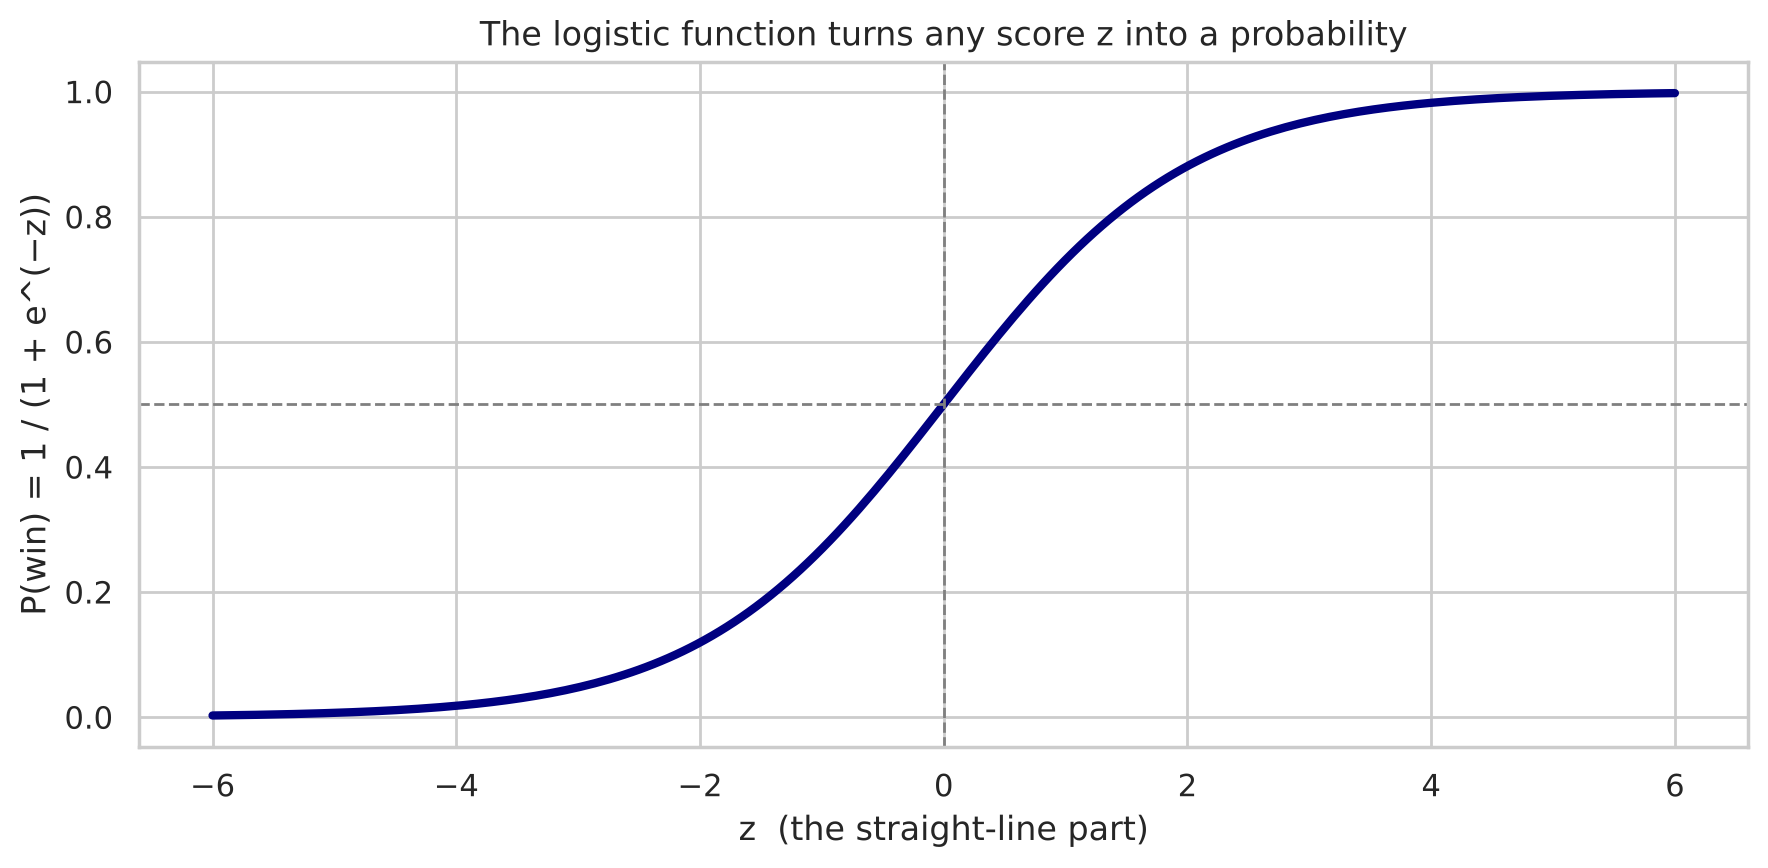

In [26]:
z = np.linspace(-6, 6, 200)
plt.figure(figsize=(9, 4.5))
plt.plot(z, 1 / (1 + np.exp(-z)), color="navy", lw=3)
plt.axhline(0.5, color="gray", ls="--", lw=1); plt.axvline(0, color="gray", ls="--", lw=1)
plt.title("The logistic function turns any score z into a probability")
plt.xlabel("z  (the straight-line part)"); plt.ylabel("P(win) = 1 / (1 + e^(−z))")
plt.tight_layout(); plt.show()

### Step 4: Logistic regression with just the lead
Logistic coefficients are on the **log-odds** scale, which is hard to picture. The easy way to read them is $e^{b}$, the **odds ratio**: how much the **odds** of winning get multiplied by for each one-unit increase.

(Odds = chance of winning ÷ chance of losing. A 75% chance is odds of 3 to 1.)

z = 0.277 + 0.183 × lead      P(win) = 1 / (1 + e^(−z))
Odds ratio per point of lead: e^0.183 = 1.20  →  each point multiplies the odds of winning by 1.20


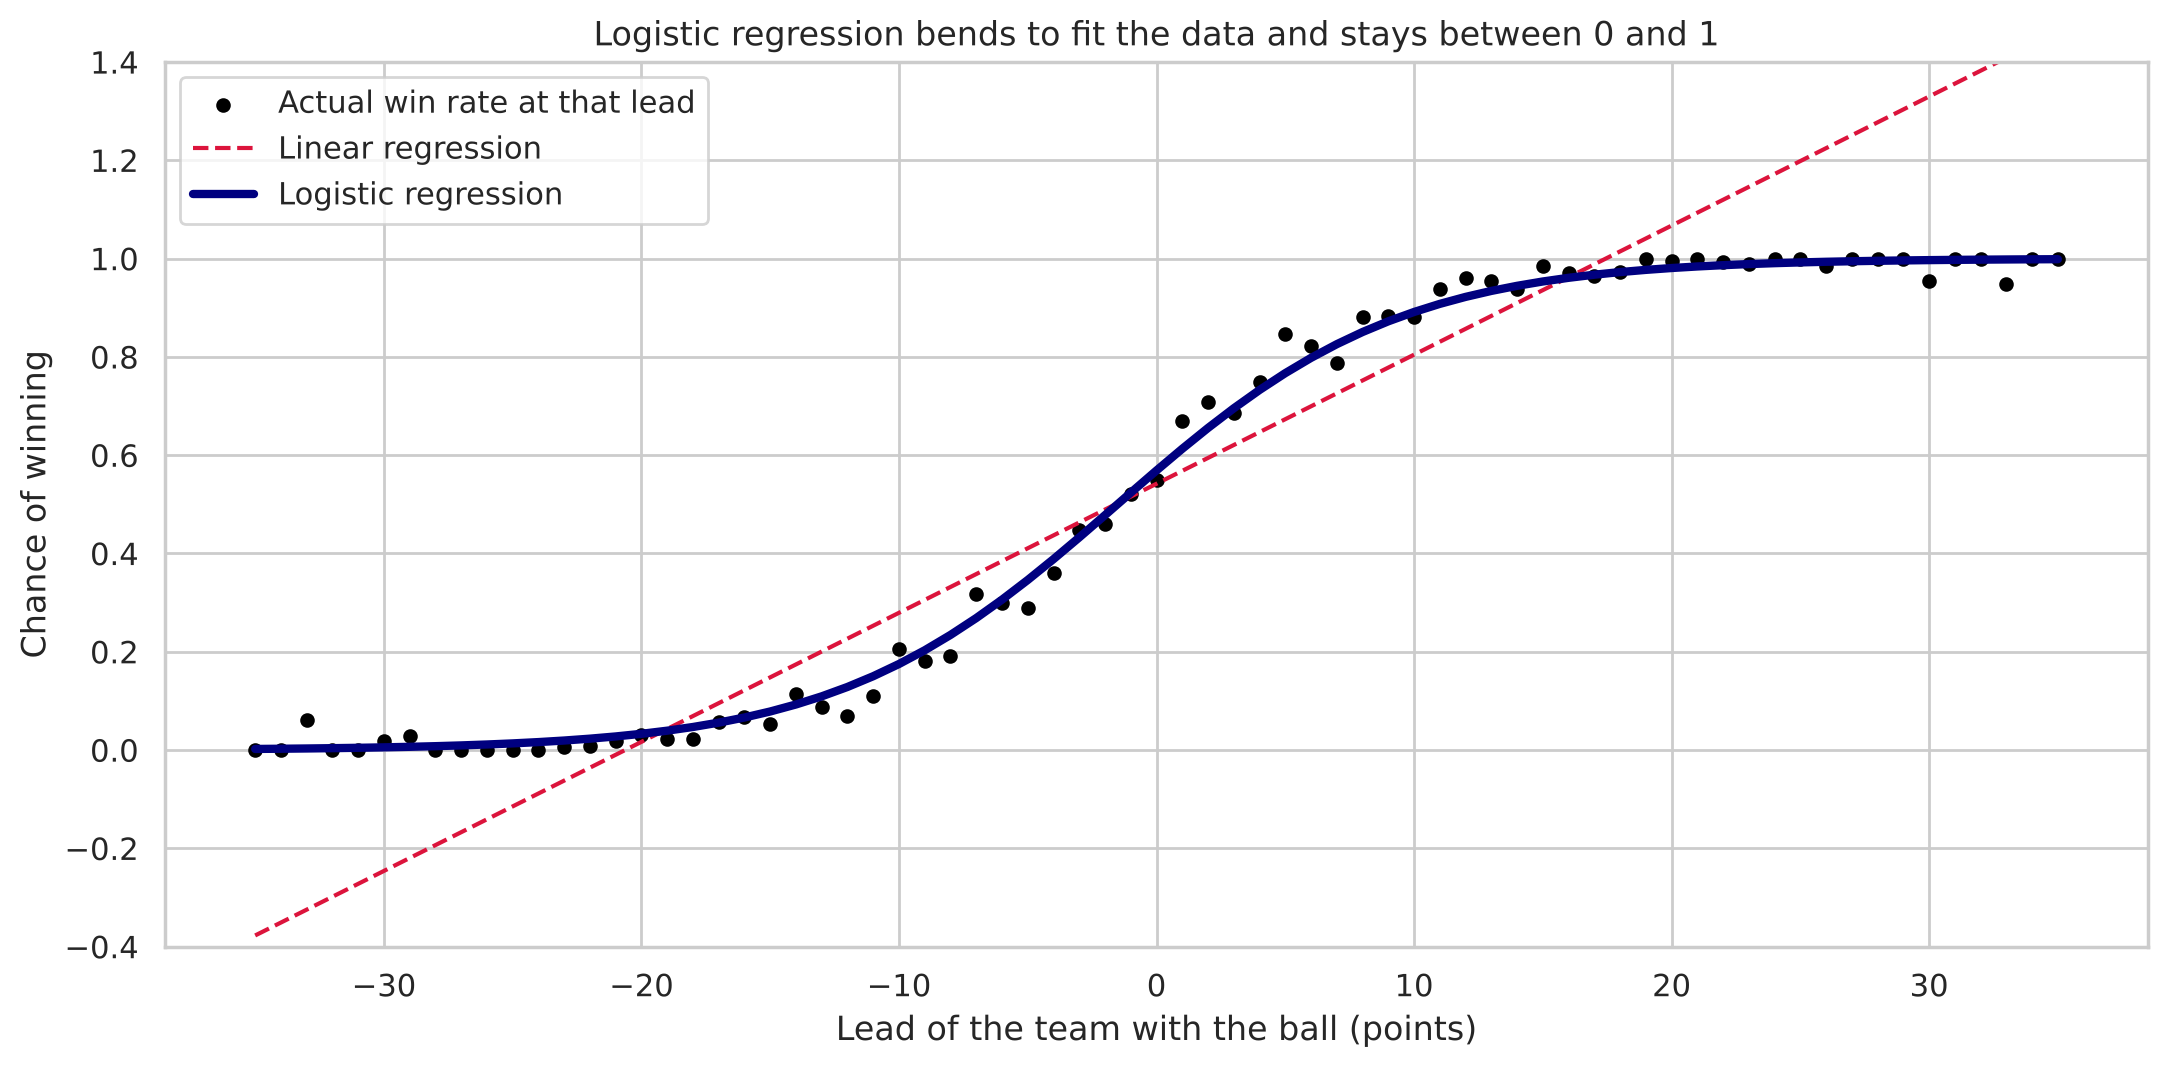

In [27]:
logit_lead = smf.logit("won ~ score_differential", data=wp_train).fit(disp=0)
b0, b1 = logit_lead.params["Intercept"], logit_lead.params["score_differential"]
print(f"z = {b0:.3f} + {b1:.3f} × lead      P(win) = 1 / (1 + e^(−z))")
print(f"Odds ratio per point of lead: e^{b1:.3f} = {np.exp(b1):.2f}  →  each point multiplies the odds of winning by {np.exp(b1):.2f}")

fig, ax = plt.subplots(figsize=(11, 5.5))
ax.scatter(by_lead.index, by_lead.values, color="black", s=18, label="Actual win rate at that lead")
ax.plot(xs, lpm.params["Intercept"] + lpm.params["score_differential"] * xs, color="crimson", lw=1.5, ls="--", label="Linear regression")
ax.plot(xs, logit_lead.predict(pd.DataFrame({"score_differential": xs})), color="navy", lw=3, label="Logistic regression")
ax.set(xlabel="Lead of the team with the ball (points)", ylabel="Chance of winning", ylim=(-0.4, 1.4),
       title="Logistic regression bends to fit the data and stays between 0 and 1")
ax.legend(loc="upper left"); plt.tight_layout(); plt.show()

> 🔍 **Check your understanding:** With the lead-only model, roughly what is the chance of winning for a team up by 7? (Use z = b₀ + b₁ × 7 and P = 1/(1+e^(−z)).)

<details><summary><b>Click to reveal the answer</b></summary>

z ≈ 0.28 + 0.18 × 7 ≈ 1.56, so P ≈ 1 / (1 + e^(−1.56)) ≈ 83%. Run `logit_lead.predict(pd.DataFrame({'score_differential': [7]}))` to check.

</details>

### Step 5: Add the game situation
A 7-point lead means very different things with 55 minutes left versus 1 minute left. So we add more inputs, plus one **engineered feature**:

$$\text{lead\_per\_time} = \frac{\text{lead}}{\sqrt{\text{minutes left} + 1}}$$

| Situation | lead ÷ √(minutes left + 1) |
|---|---|
| Up 7, 60 minutes left | 7 ÷ 7.8 = **0.9** |
| Up 7, 15 minutes left | 7 ÷ 4.0 = **1.8** |
| Up 7, 1 minute left | 7 ÷ 1.4 = **4.9** |

The same lead becomes a much bigger number as time runs out. That's exactly what we want the model to feel.

| Input | Meaning |
|---|---|
| `score_differential` | lead of the team with the ball |
| `lead_per_time` | lead ÷ √(minutes left + 1) |
| `yardline_100` | yards from the opponent's end zone (lower = closer to scoring) |
| `C(down)` | which down (C(...) treats it as a category, compared with 1st down) |
| `ydstogo` | yards needed for a first down |
| `posteam_timeouts_remaining`, `defteam_timeouts_remaining` | timeouts left |
| `min_left` | minutes left in the game |

In [28]:
def add_features(df):
    df = df.copy()
    df["lead_per_time"] = df.score_differential / np.sqrt(df.min_left + 1)
    return df

wp_train, wp_test = add_features(wp_train), add_features(wp_test)

WP_FORMULA = ("won ~ score_differential + lead_per_time + yardline_100 + C(down) + ydstogo"
              " + posteam_timeouts_remaining + defteam_timeouts_remaining + min_left")
wp_model = smf.logit(WP_FORMULA, data=wp_train).fit(disp=0)

wp_coefs = pd.DataFrame({"coefficient (log-odds)": wp_model.params,
                         "odds ratio  e^coef": np.exp(wp_model.params),
                         "p-value": wp_model.pvalues})
wp_coefs.round(4)

,coefficient (log-odds),odds ratio e^coef,p-value
Intercept,1.290,3.632,0.000
C(down)[T.2],-0.092,0.912,0.000
C(down)[T.3],-0.213,0.808,0.000
C(down)[T.4],-0.417,0.659,0.000
score_differential,0.052,1.054,0.000
lead_per_time,0.598,1.819,0.000
yardline_100,-0.009,0.991,0.000
ydstogo,-0.011,0.989,0.000
posteam_timeouts_remaining,0.035,1.036,0.000
defteam_timeouts_remaining,-0.083,0.920,0.000


> 🔍 **Check your understanding:** The coefficient on `yardline_100` is negative. What does that mean in football terms?

<details><summary><b>Click to reveal the answer</b></summary>

`yardline_100` is the distance from the opponent's end zone. A bigger number means you're farther from scoring, so your chance of winning is lower. Each extra yard away multiplies the odds of winning by slightly less than 1.

</details>

### Step 6: ✏️ Calculate a win probability by hand
This is exactly what the computer does: multiply each coefficient by the situation's value, add them up to get $z$, then apply the logistic function. Change the situation and rerun.

In [29]:
# ✏️ Describe a situation (from the point of view of the team with the ball)
situation = dict(
    score_differential = -4,    # down by 4
    min_left           = 2.0,   # 2:00 left in the game
    yardline_100       = 35,    # ball at the opponent's 35
    down               = 1,
    ydstogo            = 10,
    posteam_timeouts_remaining = 2,
    defteam_timeouts_remaining = 3,
)

s = add_features(pd.DataFrame([situation])).iloc[0]
def term_value(name):
    if name == "Intercept":       return 1.0
    if name.startswith("C(down)"): return float(int(name[-2]) == s.down)   # 1 if that's the down, else 0
    return float(s[name])

work = pd.DataFrame({"coefficient": wp_model.params})
work["value"] = [term_value(n) for n in work.index]
work["coef × value"] = work.coefficient * work.value
display(work.round(4))

z = work["coef × value"].sum()
print(f"z = sum of the last column = {z:.3f}")
print(f"P(win) = 1 / (1 + e^(−z)) = 1 / (1 + e^({-z:.3f})) = {1 / (1 + np.exp(-z)):.1%}")
print(f"Check with the model:          {wp_model.predict(add_features(pd.DataFrame([situation])))[0]:.1%}")

,coefficient,value,coef × value
Intercept,1.290,1.000,1.290
C(down)[T.2],-0.092,0.000,-0.000
C(down)[T.3],-0.213,0.000,-0.000
C(down)[T.4],-0.417,0.000,-0.000
score_differential,0.052,-4.000,-0.209
lead_per_time,0.598,-2.309,-1.382
yardline_100,-0.009,35.000,-0.327
ydstogo,-0.011,10.000,-0.110
posteam_timeouts_remaining,0.035,2.000,0.071
defteam_timeouts_remaining,-0.083,3.000,-0.250


z = sum of the last column = -0.928
P(win) = 1 / (1 + e^(−z)) = 1 / (1 + e^(0.928)) = 28.3%
Check with the model:          28.3%


To make experimenting easier, here's a function version. ✏️ Try a few situations of your own.

In [30]:
def win_prob(lead, minutes_left, yardline_100=75, down=1, ydstogo=10, timeouts_off=3, timeouts_def=3):
    """Chance the team with the ball wins, from our logistic regression model."""
    s = pd.DataFrame([dict(score_differential=lead, min_left=minutes_left, yardline_100=yardline_100, down=down,
                           ydstogo=ydstogo, posteam_timeouts_remaining=timeouts_off,
                           defteam_timeouts_remaining=timeouts_def)])
    return float(wp_model.predict(add_features(s))[0])

print(f"Tied, opening kickoff, 1st & 10 at own 25:  {win_prob(0, 60):.0%}")
print(f"Up 7, 1st & 10 at own 25, 10 minutes left:  {win_prob(7, 10):.0%}")
print(f"Up 7, same spot, 2 minutes left:            {win_prob(7, 2):.0%}")
print(f"Down 3, 4th & 2 at opp 30, 1 minute left:   {win_prob(-3, 1, yardline_100=30, down=4, ydstogo=2):.0%}")

Tied, opening kickoff, 1st & 10 at own 25:  50%
Up 7, 1st & 10 at own 25, 10 minutes left:  87%
Up 7, same spot, 2 minutes left:            96%
Down 3, 4th & 2 at opp 30, 1 minute left:   27%


### Step 7: The whole picture
Win probability for every combination of lead and time left (1st & 10 at your own 25, all timeouts). Watch how the colors get more extreme as the clock runs down.

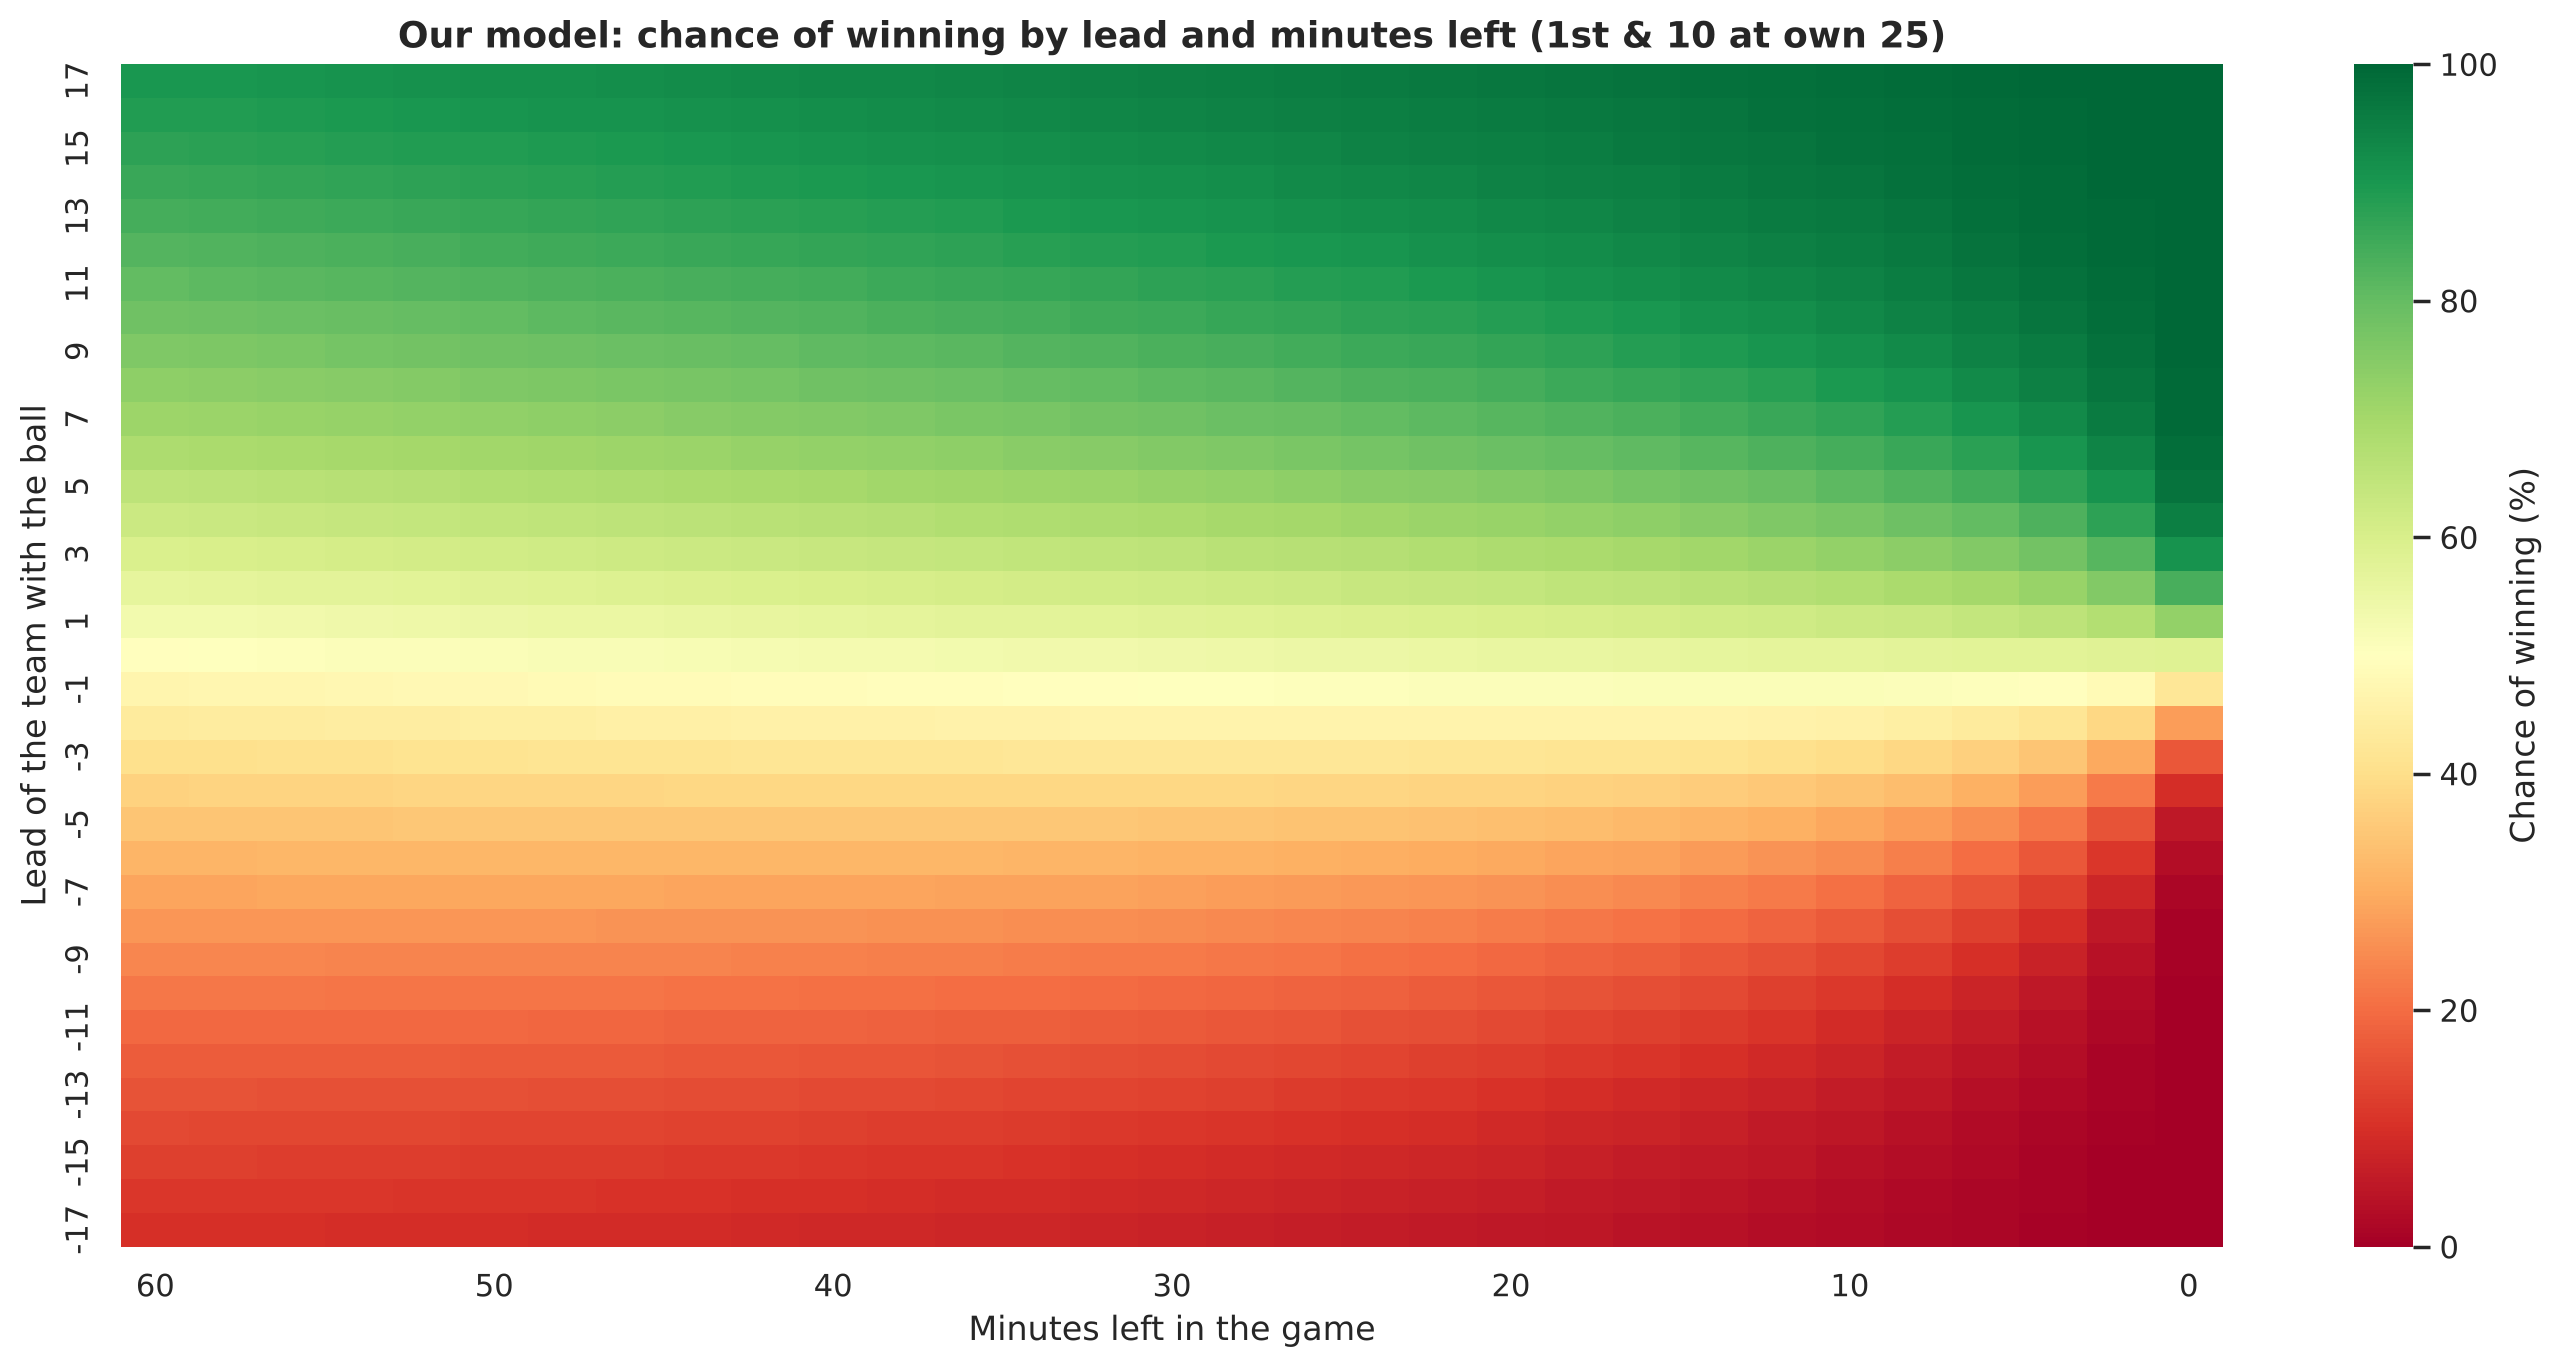

In [31]:
leads = np.arange(-17, 18)
mins = np.arange(60, -1, -2)
grid = pd.DataFrame([(l, m) for l in leads for m in mins], columns=["score_differential", "min_left"])
grid = grid.assign(yardline_100=75, down=1, ydstogo=10, posteam_timeouts_remaining=3, defteam_timeouts_remaining=3)
grid["wp"] = wp_model.predict(add_features(grid))
heat = grid.pivot(index="score_differential", columns="min_left", values="wp").sort_index(ascending=False)[mins]

plt.figure(figsize=(14, 7))
sns.heatmap(heat * 100, cmap="RdYlGn", vmin=0, vmax=100, cbar_kws={"label": "Chance of winning (%)"},
            xticklabels=5, yticklabels=2)
plt.title("Our model: chance of winning by lead and minutes left (1st & 10 at own 25)", fontsize=13, weight="bold")
plt.xlabel("Minutes left in the game"); plt.ylabel("Lead of the team with the ball")
plt.tight_layout(); plt.show()

### Step 8: Is the model any good?
We test on the 2025 season, which the model never saw, with two checks:

* **Brier score**: the average of (predicted probability − actual outcome)². Lower is better; always guessing 50% scores 0.25.
* **Calibration**: when the model says 70%, does the team really win about 70% of the time? If so, the dots sit on the diagonal.

We also compare with nflverse's own win-probability model, which professionals use. It's a machine-learning model with more inputs.

,Brier score (2025)
Linear regression (lead only),0.180
Logistic regression (lead only),0.174
Logistic regression (full),0.171
nflverse's professional model,0.169


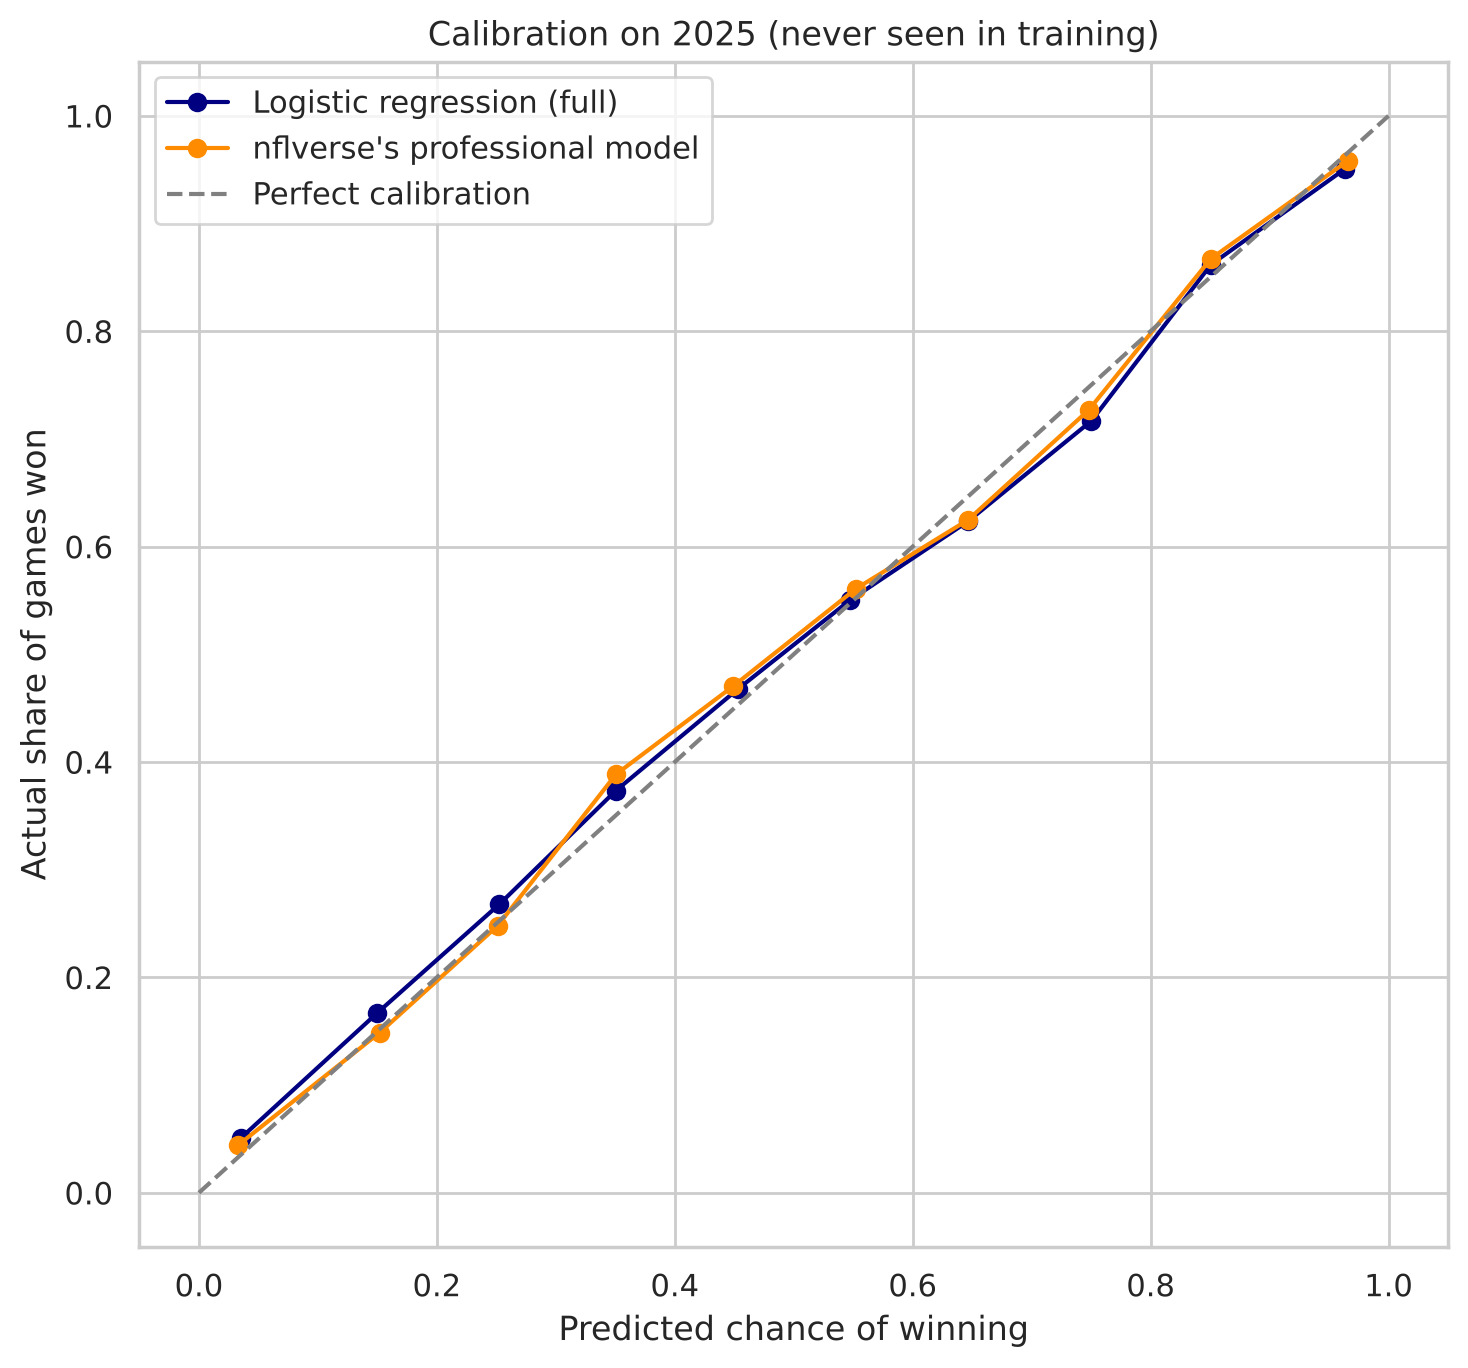

In [32]:
test_preds = {
    "Linear regression (lead only)":   lpm.predict(wp_test),
    "Logistic regression (lead only)": logit_lead.predict(wp_test),
    "Logistic regression (full)":      wp_model.predict(wp_test),
    "nflverse's professional model":   wp_test.wp,
}
brier = pd.Series({name: np.mean((p - wp_test.won) ** 2) for name, p in test_preds.items()}, name="Brier score (2025)")
display(brier.round(4).to_frame())

fig, ax = plt.subplots(figsize=(7.5, 7))
for name, color in [("Logistic regression (full)", "navy"), ("nflverse's professional model", "darkorange")]:
    bins = pd.cut(test_preds[name], np.linspace(0, 1, 11))
    cal = wp_test.groupby(bins, observed=True).won.mean()
    ax.plot(test_preds[name].groupby(bins, observed=True).mean(), cal, "o-", color=color, label=name)
ax.plot([0, 1], [0, 1], "--", color="gray", label="Perfect calibration")
ax.set(xlabel="Predicted chance of winning", ylabel="Actual share of games won",
       title="Calibration on 2025 (never seen in training)")
ax.legend(); plt.tight_layout(); plt.show()

> 🔍 **Check your understanding:** Our model has only 8 inputs and one formula. How close does it get to the professional model, and what does that tell you?

<details><summary><b>Click to reveal the answer</b></summary>

Its Brier score is within about 0.0015 of the professional model's, and both are well calibrated. A simple, explainable model captures most of the information; the fancy model adds a little extra accuracy.

</details>

### Step 9: From win probability to win probability **added** (WPA)
💡 **Key idea:** once we can compute a win probability before every play, measuring a play is just subtraction:

$$\text{WPA} = \text{WP after the play} - \text{WP before the play}$$

"WP after the play" is the win probability at the **next snap**. If the ball changed hands, we flip it: the next team's 30% chance means this team now has 70%. After the last snap of a game it's simply 1 (won) or 0 (lost). If the game went to overtime, it's 0.5, because the score was tied when regulation ended.

In [33]:
g25 = wp_test.sort_values(["game_id", "play_id"]).copy()
g25["wp_before"] = wp_model.predict(g25)
nxt = g25.groupby("game_id")
g25["next_wp"], g25["next_team"] = nxt.wp_before.shift(-1), nxt.posteam.shift(-1)
g25["wp_after"] = np.where(g25.next_team == g25.posteam, g25.next_wp, 1 - g25.next_wp)   # flip on change of possession
last = g25.next_wp.isna()                                                                # last snap of regulation
g25.loc[last, "wp_after"] = np.where(g25.loc[last, "game_id"].isin(ot_games), 0.5, g25.loc[last, "won"])
g25["wpa_ours"] = g25.wp_after - g25.wp_before

# A worked example: a big 2025 swing (over 25 points) where our model and nflverse agree closely
big_swings = g25[~last & (g25.wpa.abs() > 0.25)]
ex = big_swings.loc[(big_swings.wpa_ours - big_swings.wpa).abs().idxmin()]
lead = "tied" if ex.score_differential == 0 else (f"up {ex.score_differential:.0f}" if ex.score_differential > 0 else f"down {-ex.score_differential:.0f}")
print(f"Week {ex.week}, {ex.posteam} vs {ex.defteam}, Q{ex.qtr:.0f} {ex.time}: {ex.posteam} {lead}, "
      f"{ex.down}-and-{ex.ydstogo:.0f} at {ex.yardline_100:.0f} yards from the end zone")
print(f"Play: {ex.desc[:140]}")
print(f"\nWP before = {ex.wp_before:.1%}")
print(f"WP after  = {ex.wp_after:.1%}   ({ex.posteam}'s view at the next snap)")
print(f"WPA       = {ex.wp_after:.1%} − {ex.wp_before:.1%} = {ex.wpa_ours:+.1%}")
print(f"(nflverse's model says {ex.wpa:+.1%})")

Week 13, CHI vs PHI, Q3 06:44: CHI up 1, 2-and-1 at 45 yards from the end zone
Play: (6:44) 18-C.Williams pass short left intended for 25-K.Monangai INTERCEPTED by 58-J.Hunt at CHI 47. 58-J.Hunt to CHI 36 for 11 yards (18-C.W

WP before = 66.4%
WP after  = 40.1%   (CHI's view at the next snap)
WPA       = 40.1% − 66.4% = -26.2%
(nflverse's model says -25.8%)


### How does our WPA compare with the professional model?

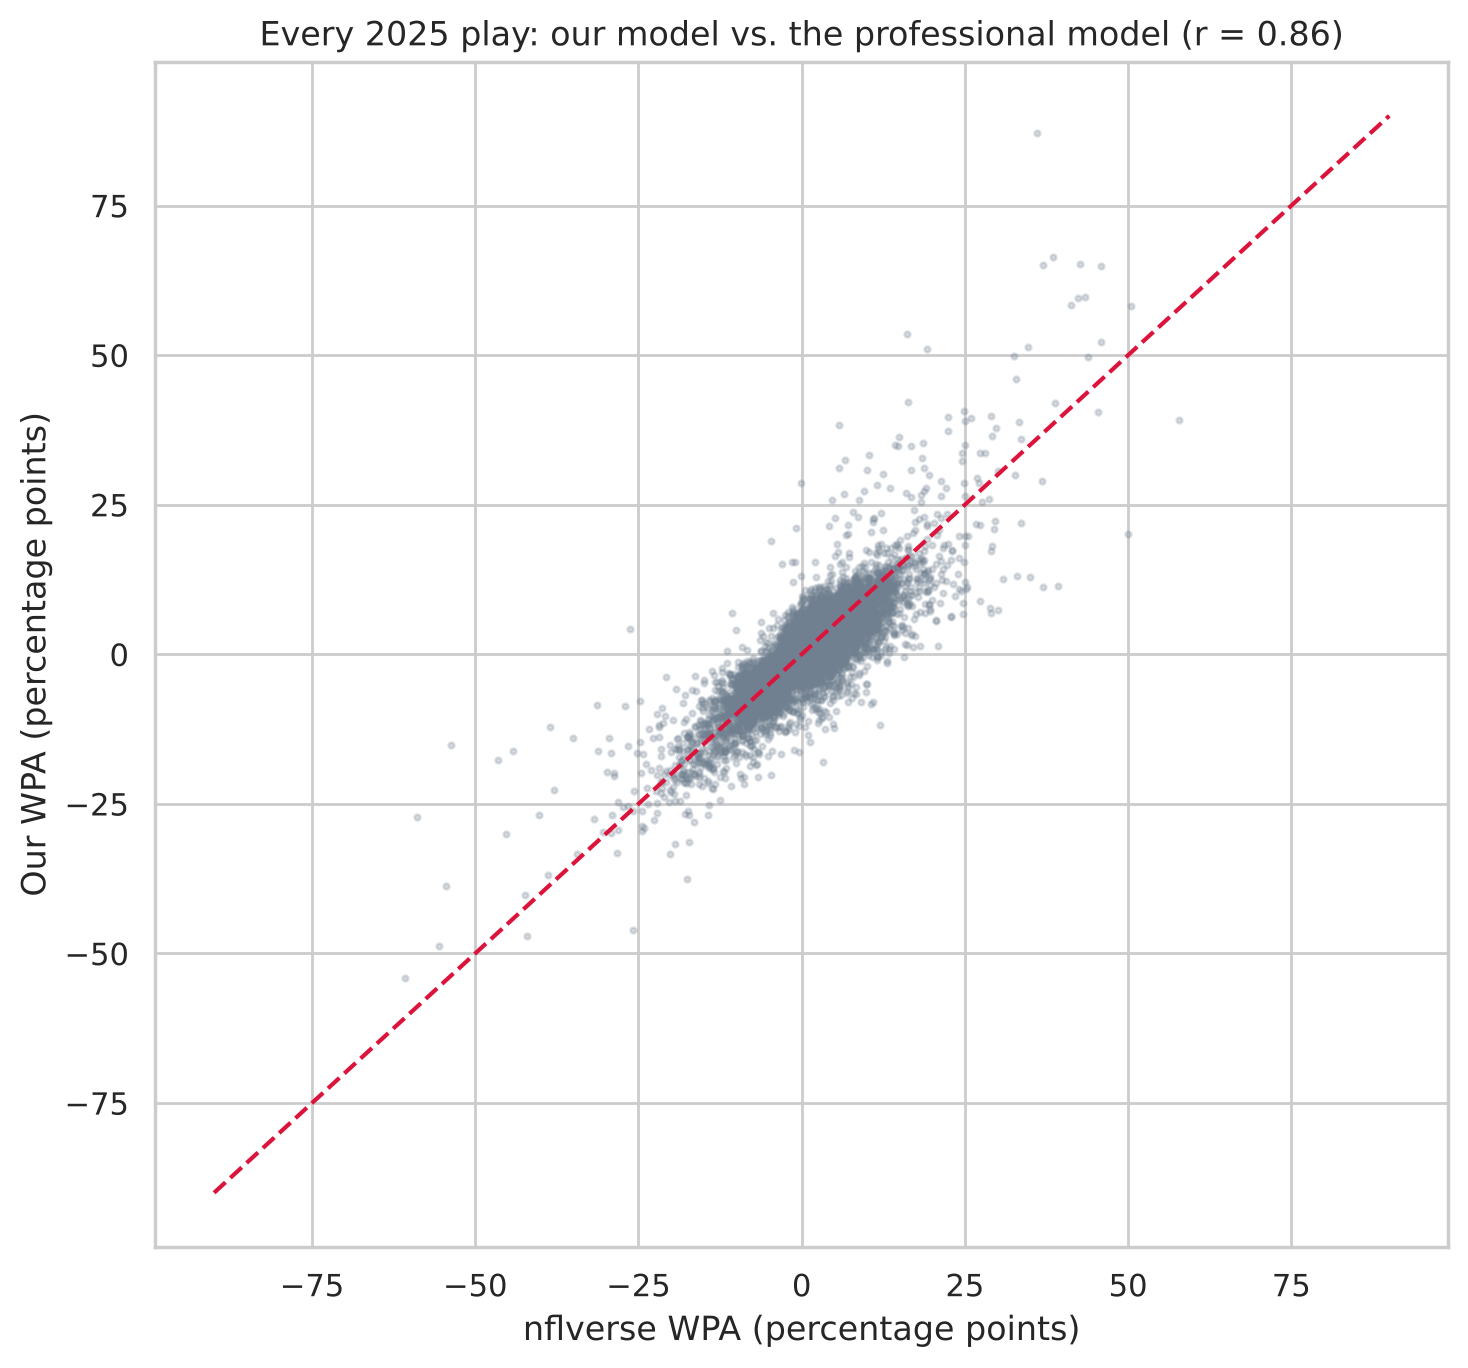

Offense,When,Our WPA,nflverse WPA,Play
,Q4 00:09,+87%,+36%,"(:09) 1-R.White right guard for 2 yards, TOUCHDOWN."
,Q4 00:42,-15%,-54%,"(:42) (No Huddle, Shotgun) 14-S.Darnold sacked at SF 16 for -7 yards (97-N.Bosa). FUMBLES (97-N.Bosa), touched"
,Q4 00:30,+53%,+16%,"(:30) 16-T.Lawrence scrambles left end for 1 yard, TOUCHDOWN. Penalty on KC-27-C.Conner, Defensive Holding, de"
,Q4 01:48,+38%,+6%,"(1:48) (Shotgun) 25-T.Allgeier left tackle for 1 yard, TOUCHDOWN."
,Q4 01:15,+51%,+19%,"(1:15) (Shotgun) 9-B.Young pass short left to 4-T.McMillan for 12 yards, TOUCHDOWN."
,Q4 01:07,-27%,-59%,"(1:07) 23-K.Williams up the middle to SF 2 for 1 yard (95-A.Collins). FUMBLES (95-A.Collins), RECOVERED by SF-"
,Q4 07:39,+4%,-26%,"(7:39) 17-B.Baringer punts 65 yards to MIA 26, Center-47-J.Ashby. 6-M.Washington for 74 yards, TOUCHDOWN."
,Q4 00:13,+20%,+50%,"(:13) 8-D.Carlson 60 yard field goal is GOOD, Center-50-J.Bobenmoyer, Holder-6-A.Cole."


In [34]:
r = g25[["wpa_ours", "wpa"]].corr().iloc[0, 1]
fig, ax = plt.subplots(figsize=(7.5, 7))
ax.scatter(g25.wpa * 100, g25.wpa_ours * 100, s=4, alpha=.25, color="slategray")
ax.plot([-90, 90], [-90, 90], "--", color="crimson")
ax.set(xlabel="nflverse WPA (percentage points)", ylabel="Our WPA (percentage points)",
       title=f"Every 2025 play: our model vs. the professional model (r = {r:.2f})")
plt.tight_layout(); plt.show()

# Where do they disagree most?
diff = g25.assign(gap=(g25.wpa_ours - g25.wpa).abs()).nlargest(8, "gap")
rows = "".join(
    f"<tr><td>{logo_html(d.posteam, 24)}</td><td>Q{d.qtr:.0f} {d.time}</td><td>{d.wpa_ours * 100:+.0f}%</td>"
    f"<td>{d.wpa * 100:+.0f}%</td><td style='text-align:left;font-size:11px'>{d.desc[:110]}</td></tr>"
    for _, d in diff.iterrows())
display(HTML(f"""<h4 style="font-family:sans-serif">Biggest disagreements</h4>
<table style="font-family:sans-serif;font-size:13px;text-align:center;border-collapse:collapse">
<tr style="background:#1f2937;color:white"><th>Offense</th><th>When</th><th>Our WPA</th><th>nflverse WPA</th><th>Play</th></tr>
{rows}</table>"""))

> 🔍 **Check your understanding:** Most of the biggest disagreements are plays right near the goal line in the last two minutes (short touchdowns, fumbles at the 2-yard line). Why would our model get those wrong?

<details><summary><b>Click to reveal the answer</b></summary>

In our model each yard of field position has the **same** small effect at any point in the game. But being at the opponent's 2 with 9 seconds left is far more valuable than being at the 2 in the first quarter, because a touchdown is very likely and there's no time for the other team to answer. Our model can't see that combination, so it underrates teams at the goal line late and gives the touchdown too much credit. The professional model uses a more flexible method that captures combinations like this. Every model has blind spots, so always check where it fails. (Exercise 6 asks you to try fixing this one.)

</details>

> 💡 **Takeaway:** WPA isn't magic. It's a regression prediction before and after each play. From here on we use **nflverse's** WP and WPA because they also handle overtime, kickoffs and extra points, but it's the same idea you just built.

## Part 7 · The most important plays of 2025

Now we use win probability added to find the plays that mattered most, the kinds of plays that matter most, and the quarterbacks who added the most win probability.

### Load the full 2025 play-by-play and label every play
The first line prints an accuracy check: a team's WPA added up over a whole season should match its wins (correlation ≈ 1).

In [35]:
PBP_SEASON = 2025   # set to CURRENT_SEASON to look at 2026 so far

pbp_all = nfl.load_pbp(seasons=[PBP_SEASON]).to_pandas()
pbp_all = pbp_all[(pbp_all.season_type == "REG") & pbp_all.wpa.notna()].copy()

# Accuracy check: every play's WPA is "WP after − WP before", so a team's WPA summed over
# all its plays (offense + defense + special teams) must equal wins minus its starting WP.
pbp_all["home_wpa"] = np.where(pbp_all.posteam == pbp_all.home_team, pbp_all.wpa, -pbp_all.wpa)
team_wpa = pd.concat([
    pbp_all.groupby("home_team").home_wpa.sum(),
    -pbp_all.groupby("away_team").home_wpa.sum()]).groupby(level=0).sum()
team_wins = full.loc[full.season == PBP_SEASON].set_index("team").win
print(f"Correlation of season WPA with actual wins: {team_wpa.corr(team_wins):.3f}  (should be ≈ 1)")

# Keep real scrimmage plays and kicks (drop kneels, spikes, penalties, kickoffs, PATs)
pbp = pbp_all[pbp_all.play_type.isin(["pass", "run", "field_goal", "punt"])
              & (pbp_all.qb_kneel == 0) & (pbp_all.qb_spike == 0)].copy()

# Label each play. Order matters: an intercepted 3rd-down pass counts as an interception.
rules = [
    ("2-pt conversion good",         pbp.two_point_conv_result == "success"),
    ("2-pt conversion failed",       pbp.two_point_attempt == 1),
    ("Interception thrown",          pbp.interception == 1),
    ("Fumble lost",                  pbp.fumble_lost == 1),
    ("Sack taken",                   pbp.sack == 1),
    ("Passing TD",                   pbp.pass_touchdown == 1),
    ("Rushing TD",                   pbp.rush_touchdown == 1),
    ("4th-down conversion",          pbp.fourth_down_converted == 1),
    ("4th-down failed",              pbp.fourth_down_failed == 1),
    ("Field goal made",              pbp.field_goal_result == "made"),
    ("Field goal missed/blocked",    pbp.play_type == "field_goal"),
    ("Punt",                         pbp.play_type == "punt"),
    ("Deep completion (20+ air yds)", (pbp.complete_pass == 1) & (pbp.air_yards >= 20)),
    ("3rd-down conversion",          pbp.third_down_converted == 1),
    ("3rd-down failed",              pbp.third_down_failed == 1),
    ("Other completion",             pbp.complete_pass == 1),
    ("Incompletion",                 pbp.incomplete_pass == 1),
    ("Run / scramble",               (pbp.rush_attempt == 1) | (pbp.qb_scramble == 1)),
]
pbp["category"] = np.select([c for _, c in rules], [n for n, _ in rules], default="Other")
print(f"\n{len(pbp):,} plays from {PBP_SEASON}")
pbp.category.value_counts()

Correlation of season WPA with actual wins: 0.999  (should be ≈ 1)

35,962 plays from 2025


category
Run / scramble                   11582
Other completion                  7295
Incompletion                      3875
3rd-down failed                   3426
3rd-down conversion               2252
Punt                              1920
Sack taken                        1212
Field goal made                    931
Passing TD                         811
Deep completion (20+ air yds)      543
Rushing TD                         510
4th-down conversion                397
Interception thrown                380
4th-down failed                    314
Fumble lost                        230
Field goal missed/blocked          156
2-pt conversion failed              69
2-pt conversion good                59
Name: count, dtype: int64

### The 15 biggest plays of the season

In [36]:
pbp["clock"] = pbp.time.fillna("")
pbp["qtr"] = pbp.qtr.astype(int)
pbp["score_differential"] = pbp.score_differential.astype(int)

top = pbp.assign(abs_wpa=pbp.wpa.abs()).nlargest(15, "abs_wpa")

rows = ""
for _, r in top.iterrows():
    helped = r.posteam if r.wpa > 0 else r.defteam            # team whose win chances went UP
    col = COLOR.get(helped, "#555")
    qlabel = "OT" if r.qtr == 5 else f"Q{r.qtr}"
    lead = f"up {r.score_differential}" if r.score_differential > 0 else ("tied" if r.score_differential == 0 else f"down {-r.score_differential}")
    rows += f"""
    <tr>
      <td>{int(r.week)}</td>
      <td style="white-space:nowrap">{logo_html(r.posteam, 26)} <span style="color:#888">vs</span> {logo_html(r.defteam, 26)}</td>
      <td>{qlabel} {r.clock}<br><span style="color:#888;font-size:11px">{r.posteam} {lead}</span></td>
      <td><b>{r.category}</b></td>
      <td style="min-width:150px">
        <div style="display:flex;align-items:center;gap:6px">{logo_html(helped, 22)}
          <div style="background:{col};height:14px;width:{abs(r.wpa) * 120:.0f}px;border-radius:3px"></div>
          <b>{abs(r.wpa) * 100:.0f}%</b></div></td>
      <td style="font-size:11px;text-align:left;max-width:420px">{r.desc[:160]}</td>
    </tr>"""

display(HTML(f"""
<h3 style="font-family:sans-serif">The 15 biggest plays of {PBP_SEASON}</h3>
<table style="border-collapse:collapse;font-family:sans-serif;font-size:13px;text-align:center">
  <tr style="background:#1f2937;color:white">
    <th>Wk</th><th>Offense vs Defense</th><th>Situation</th><th>Play</th><th>Win-prob swing (team helped)</th><th>Description</th>
  </tr>
  {rows}
</table>"""))

Wk,Offense vs Defense,Situation,Play,Win-prob swing (team helped),Description
14,vs,OT 02:35PHI down 3,Interception thrown,83%,"(2:35) (No Huddle, Shotgun) 1-J.Hurts pass deep right intended for 2-J.Dotson INTERCEPTED by 23-T.Jefferson (20-C.Hart) at LAC 1. 23-T.Jefferson to LAC 4 for 3"
5,vs,OT 03:41LA down 3,4th-down failed,80%,(3:41) 23-K.Williams right tackle to SF 11 for no gain (36-M.Sigle; 2-D.Lenoir).
12,vs,OT 04:26NYG down 7,Sack taken,74%,(4:26) (Shotgun) 19-J.Winston sacked at DET 31 for -4 yards (97-A.Hutchinson).
3,vs,Q4 00:03LA down 1,Field goal missed/blocked,61%,"(:03) 16-J.Karty 44 yard field goal is BLOCKED (90-J.Davis), Center-47-A.Ward, Holder-42-E.Evans, RECOVERED by PHI-90-J.Davis at PHI 39. 90-J.Davis for 61 yards"
5,vs,Q4 01:07LA down 3,Fumble lost,59%,"(1:07) 23-K.Williams up the middle to SF 2 for 1 yard (95-A.Collins). FUMBLES (95-A.Collins), RECOVERED by SF-95-A.Collins at SF 1."
9,vs,Q4 00:25CHI down 1,Passing TD,58%,"(:25) (Shotgun) 18-C.Williams pass deep middle to 84-C.Loveland for 58 yards, TOUCHDOWN."
14,vs,Q4 05:35CIN up 3,Interception thrown,56%,"(5:35) 9-J.Burrow pass short right intended for 1-J.Chase INTERCEPTED by 47-C.Benford at BUF 37. 47-C.Benford for 63 yards, TOUCHDOWN."
18,vs,Q4 00:02BAL down 2,Field goal missed/blocked,54%,"(:02) 33-T.Loop 44 yard field goal is No Good, Wide Right, Center-46-N.Moore, Holder-11-J.Stout."
1,vs,Q4 00:42SEA down 4,Fumble lost,54%,"(:42) (No Huddle, Shotgun) 14-S.Darnold sacked at SF 16 for -7 yards (97-N.Bosa). FUMBLES (97-N.Bosa), touched at SF 13, RECOVERED by SF-97-N.Bosa at SF 16. PEN"
16,vs,OT 03:13SEA down 1,2-pt conversion good,53%,TWO-POINT CONVERSION ATTEMPT. 14-S.Darnold pass to 81-E.Saubert is complete. ATTEMPT SUCCEEDS.


WPA is measured from the **offense's** point of view, so a big negative number (an interception, a strip-sack) is a huge play for the **defense**.

### Which kinds of plays matter most?

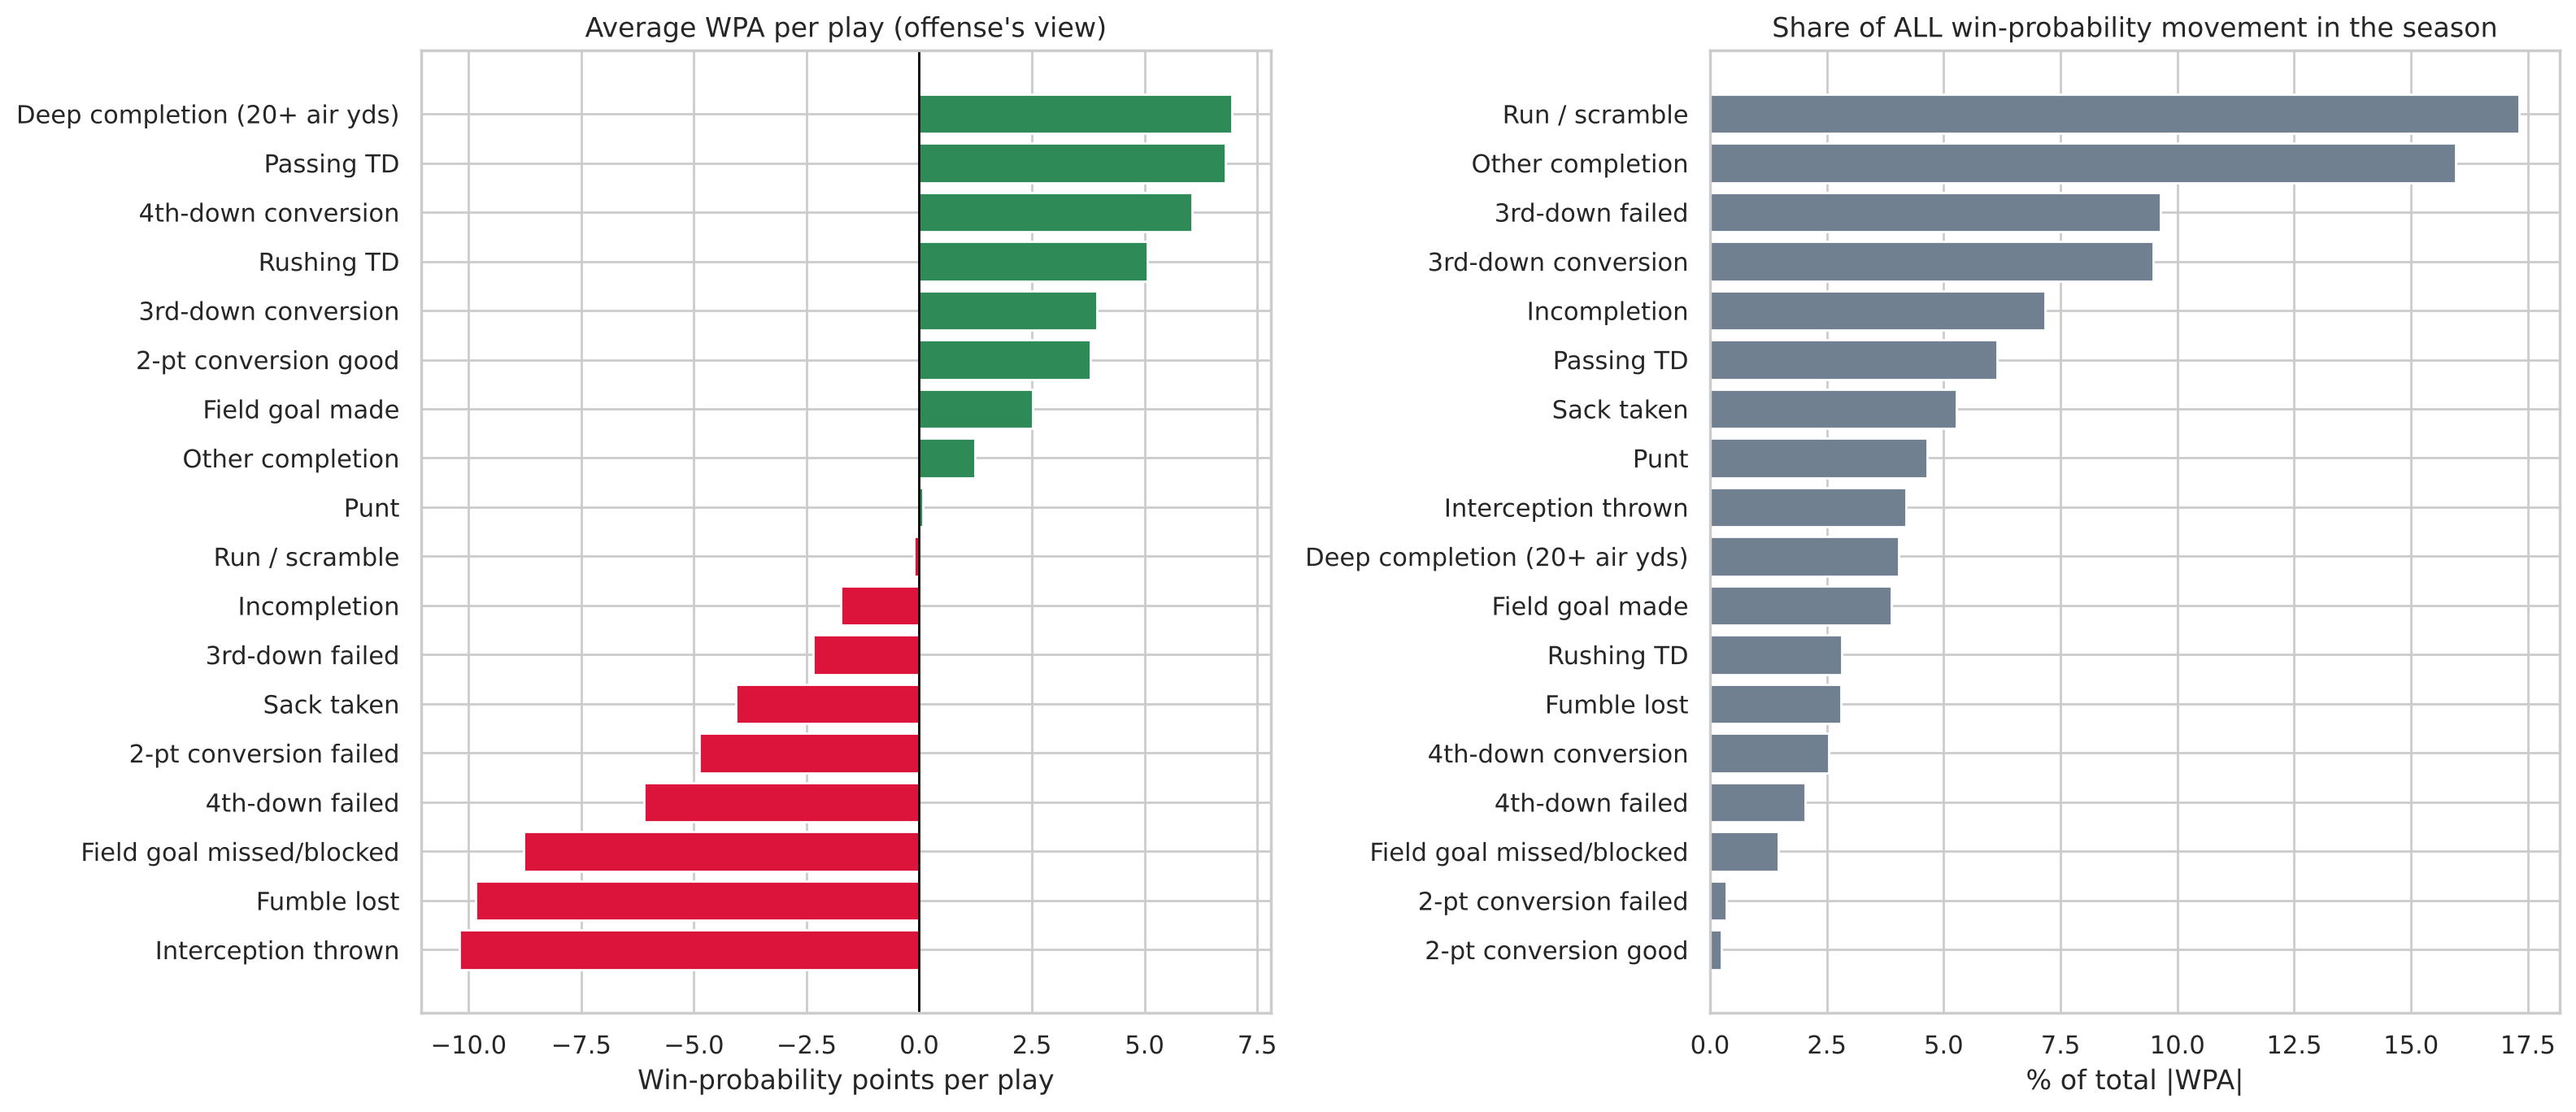

,plays,avg_wpa,total_abs_wpa,share_of_swing
category,,,,
Interception thrown,380,-0.102,39.611,0.042
Fumble lost,230,-0.098,26.506,0.028
Field goal missed/blocked,156,-0.088,13.808,0.015
Deep completion (20+ air yds),543,0.069,38.230,0.040
Passing TD,811,0.068,58.035,0.061
4th-down failed,314,-0.061,19.300,0.020
4th-down conversion,397,0.060,24.045,0.025
Rushing TD,510,0.051,26.683,0.028
2-pt conversion failed,69,-0.049,3.371,0.004


In [37]:
by_cat = (pbp.groupby("category")
             .agg(plays=("wpa", "size"),
                  avg_wpa=("wpa", "mean"),
                  total_abs_wpa=("wpa", lambda x: x.abs().sum()))
             .assign(share_of_swing=lambda d: d.total_abs_wpa / d.total_abs_wpa.sum()))
by_cat = by_cat[by_cat.index != "Other"].sort_values("avg_wpa")

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
colors = ["crimson" if v < 0 else "seagreen" for v in by_cat.avg_wpa]
axes[0].barh(by_cat.index, by_cat.avg_wpa * 100, color=colors)
axes[0].axvline(0, color="black", lw=1)
axes[0].set(title="Average WPA per play (offense's view)", xlabel="Win-probability points per play")

share = by_cat.sort_values("share_of_swing")
axes[1].barh(share.index, share.share_of_swing * 100, color="slategray")
axes[1].set(title="Share of ALL win-probability movement in the season", xlabel="% of total |WPA|")
plt.tight_layout(); plt.show()

by_cat.sort_values("avg_wpa", key=abs, ascending=False).round(4)

> **Two ways to say "most important":**
> * **Left (per play):** turnovers, touchdowns and missed kicks swing games the most **each time** they happen.
> * **Right (in total):** ordinary runs and completions happen so often that together they move win probability the most.

### When do plays matter most? Late and close

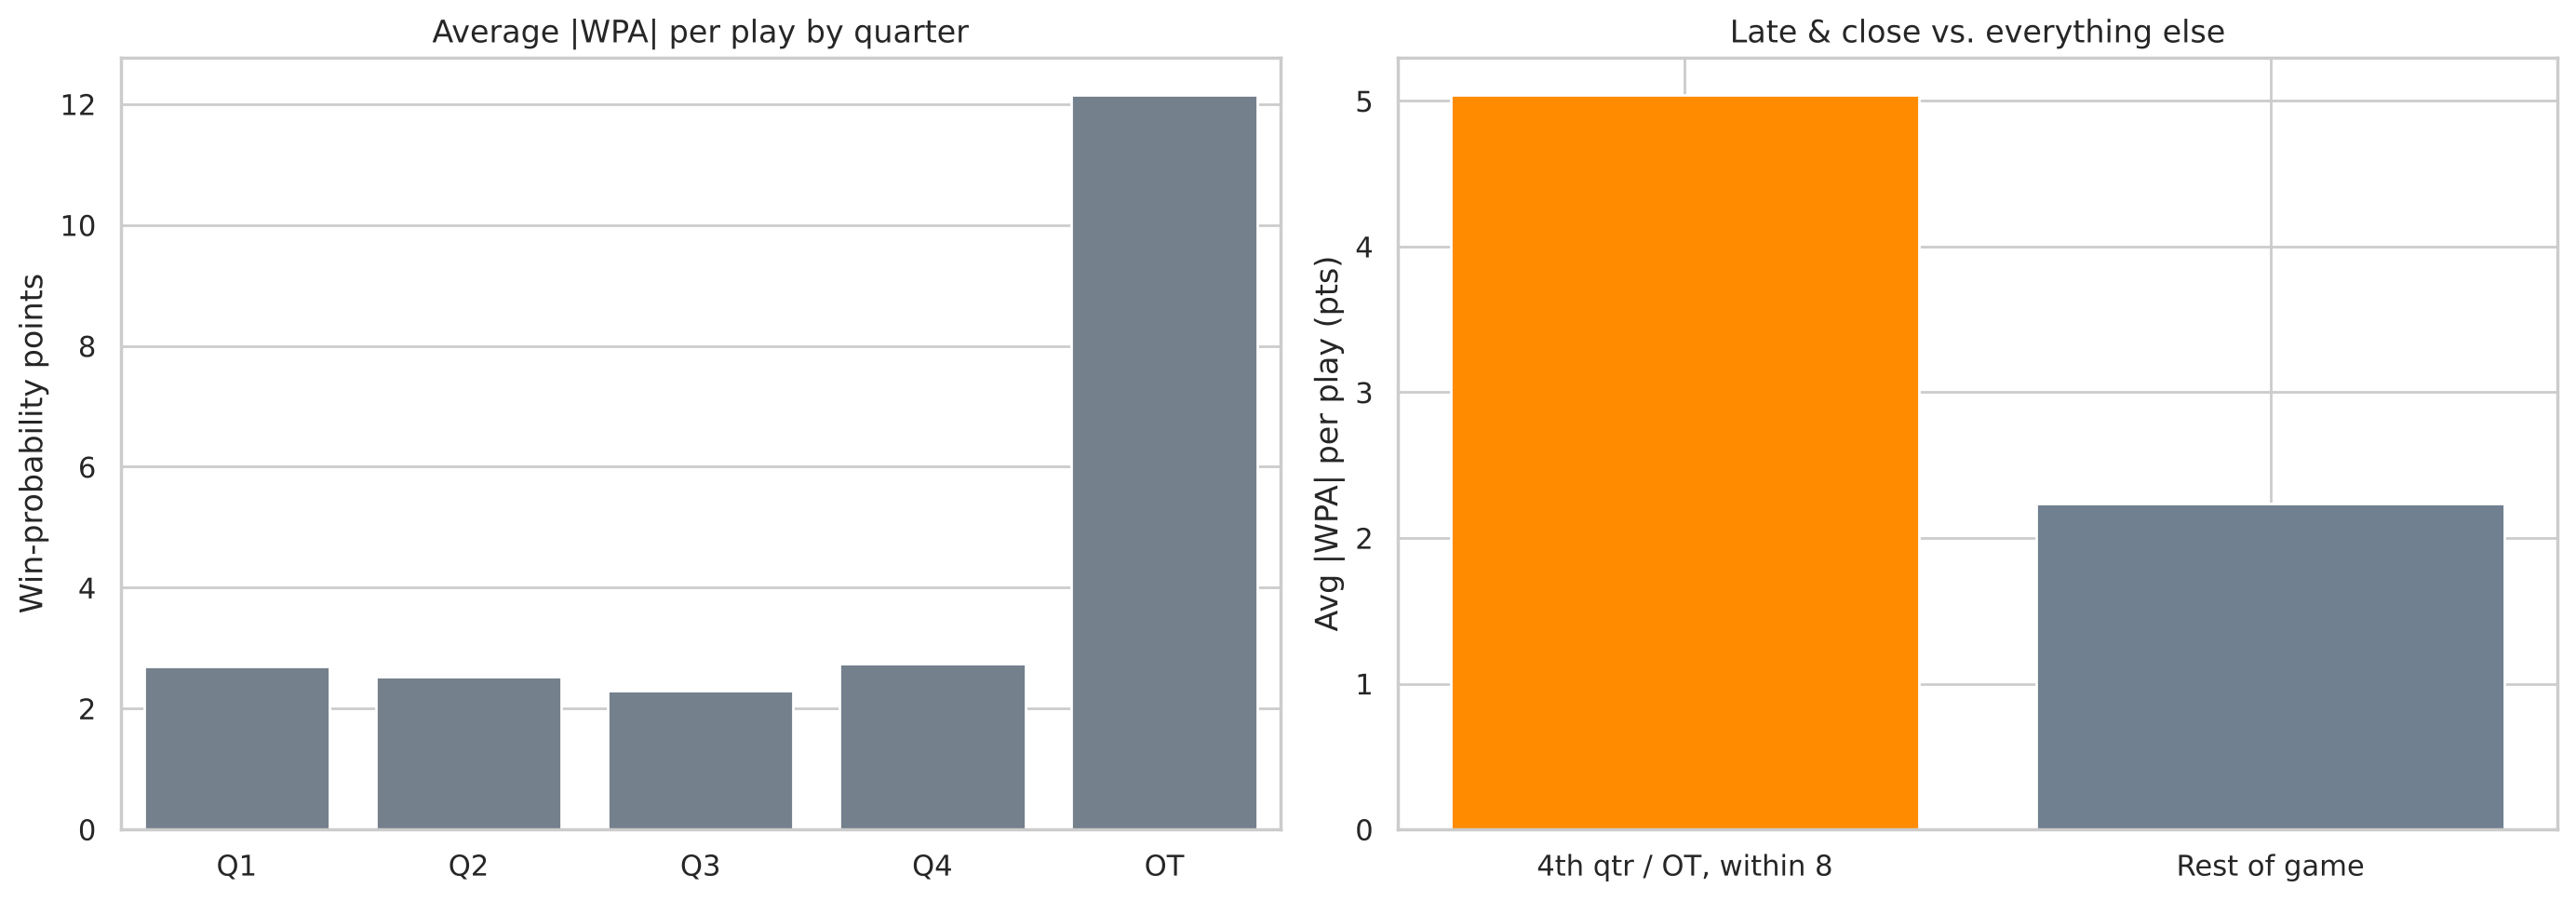

A late, close-game play moves win probability 2.3× as much as a typical play.


,plays,avg_abs_wpa
situation,,
"4th qtr / OT, within 8",5047,5.040
Rest of game,30915,2.230


In [38]:
pbp["situation"] = np.where((pbp.qtr >= 4) & (pbp.score_differential.abs() <= 8),
                            "4th qtr / OT, within 8", "Rest of game")
pbp["quarter"] = pbp.qtr.map({1: "Q1", 2: "Q2", 3: "Q3", 4: "Q4", 5: "OT"})

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=pbp, x="quarter", y=pbp.wpa.abs() * 100, order=["Q1", "Q2", "Q3", "Q4", "OT"],
            errorbar=None, color="slategray", ax=axes[0])
axes[0].set(title="Average |WPA| per play by quarter", xlabel="", ylabel="Win-probability points")

lev = pbp.groupby("situation").agg(plays=("wpa", "size"), avg_abs_wpa=("wpa", lambda x: x.abs().mean() * 100))
axes[1].bar(lev.index, lev.avg_abs_wpa, color=["darkorange", "slategray"])
axes[1].set(title="Late & close vs. everything else", ylabel="Avg |WPA| per play (pts)")
plt.tight_layout(); plt.show()

ratio = lev.loc["4th qtr / OT, within 8", "avg_abs_wpa"] / lev.loc["Rest of game", "avg_abs_wpa"]
print(f"A late, close-game play moves win probability {ratio:.1f}× as much as a typical play.")
lev.round(2)

### Win-probability chart for the game with the biggest play of the season

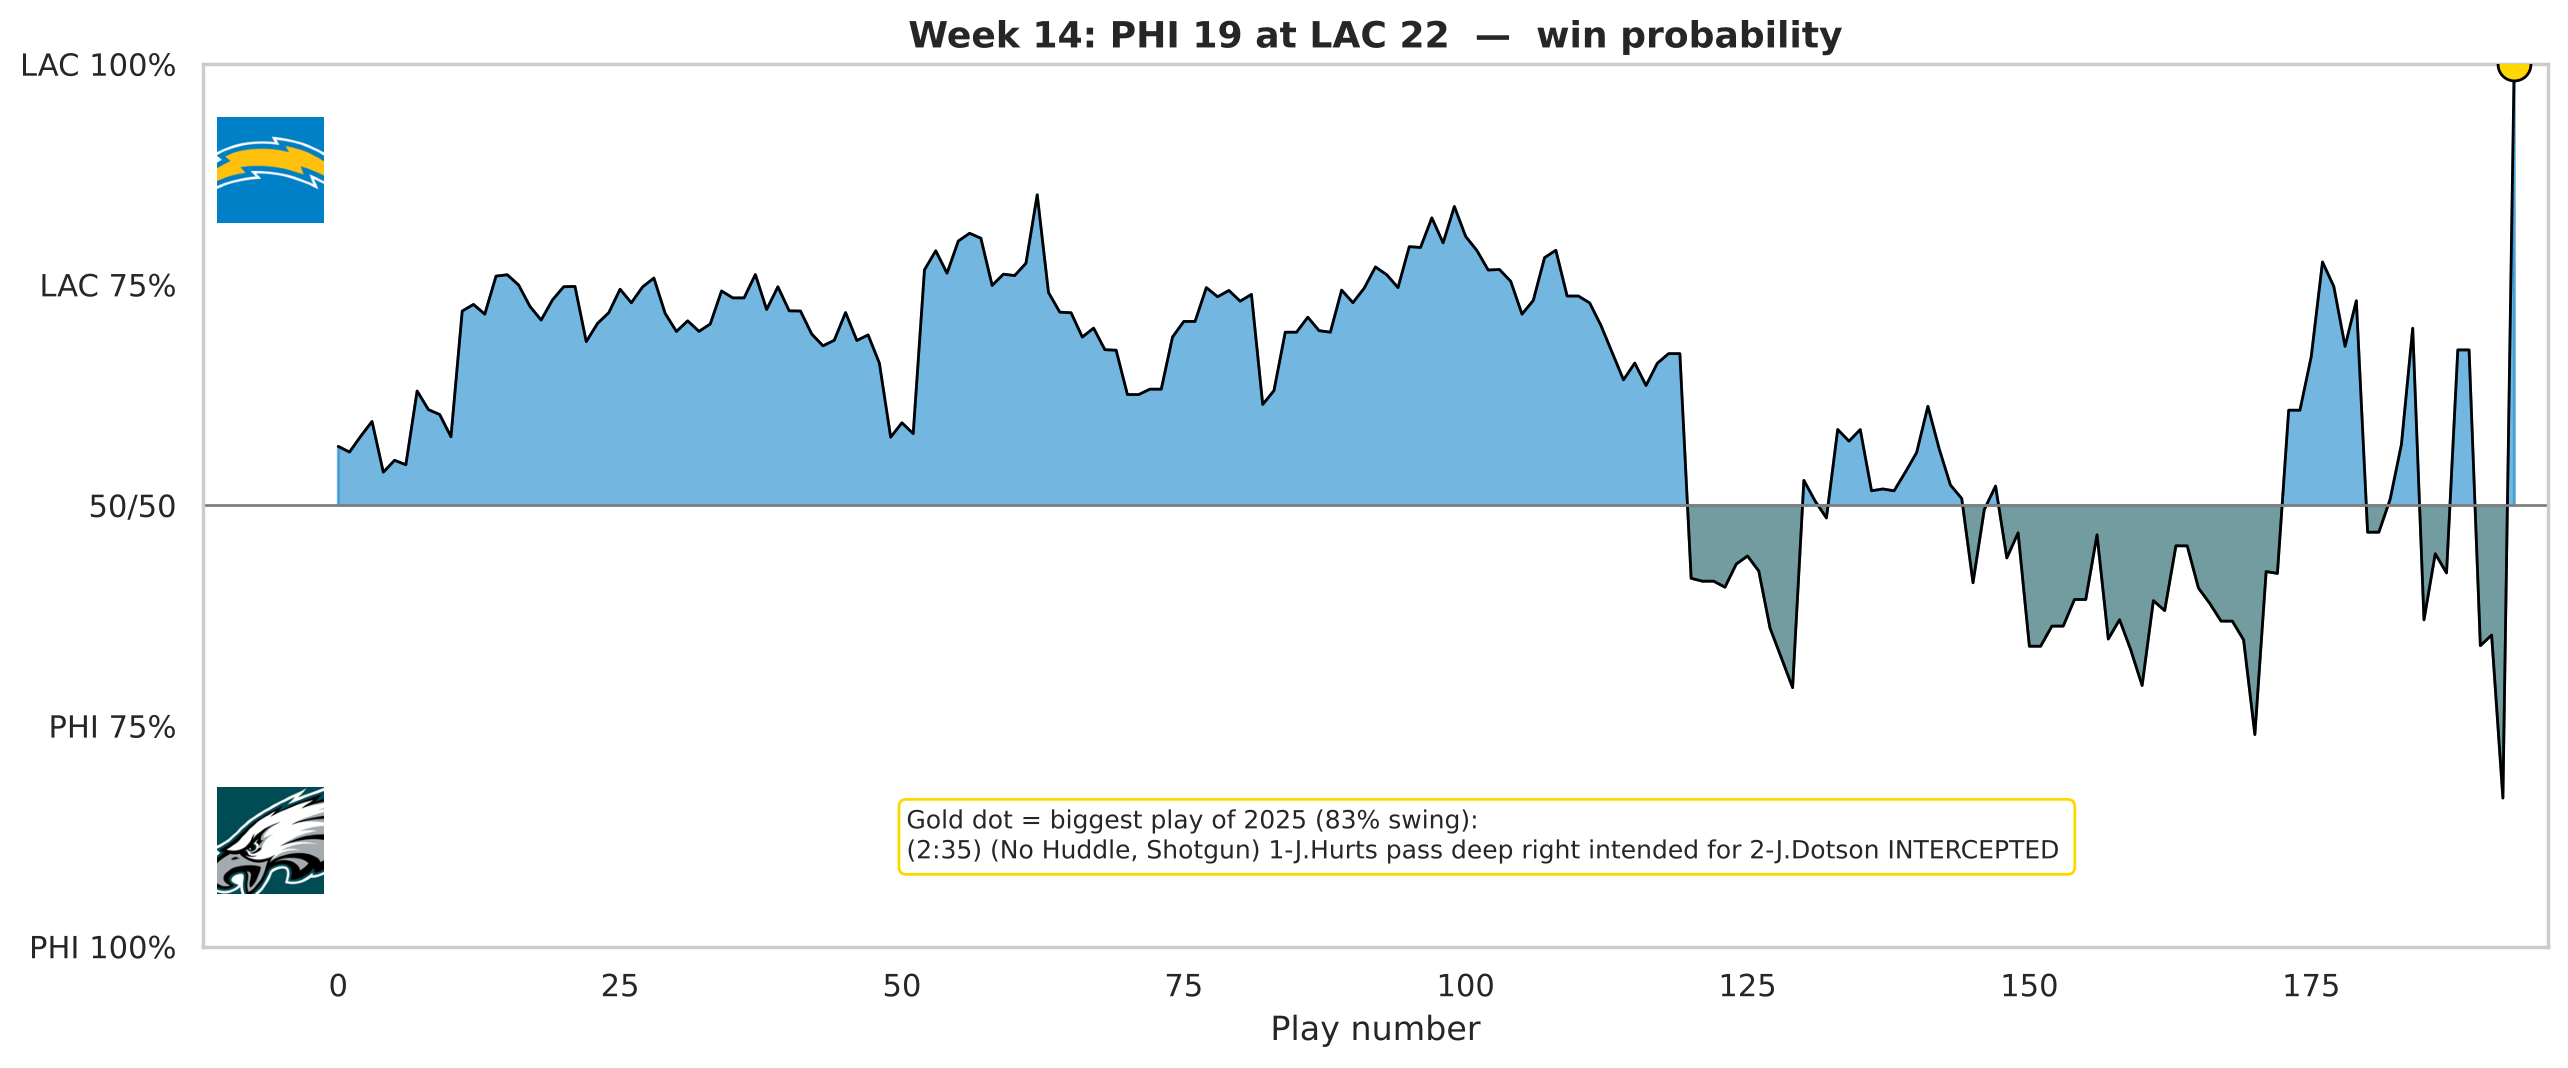

In [39]:
big = pbp.loc[pbp.wpa.abs().idxmax()]
game = pbp_all[pbp_all.game_id == big.game_id].reset_index(drop=True)
home, away = game.home_team.iloc[0], game.away_team.iloc[0]
game["home_wp_after"] = (game.home_wp + game.home_wpa).clip(0, 1) * 100   # WP after each play

fig, ax = plt.subplots(figsize=(13, 5.5))
x, y = game.index, game.home_wp_after
ax.fill_between(x, 50, y, where=y >= 50, interpolate=True, color=COLOR[home], alpha=.55)
ax.fill_between(x, 50, y, where=y < 50,  interpolate=True, color=COLOR[away], alpha=.55)
ax.plot(x, y, color="black", lw=1)
ax.axhline(50, color="gray", lw=1)

i = game.index[game.play_id == big.play_id][0]
ax.scatter(i, y[i], s=140, color="gold", edgecolor="black", zorder=5)
ax.text(0.30, 0.10, f"Gold dot = biggest play of {PBP_SEASON} ({abs(big.wpa) * 100:.0f}% swing):\n{big.desc[:90]}",
        transform=ax.transAxes, fontsize=9, bbox={"boxstyle": "round", "fc": "white", "ec": "gold"})

ax.set_xlim(-12, len(game) + 2); ax.set_ylim(0, 100)
add_logo(ax, home, -6, 88, zoom=0.32)       # home team owns the top half
add_logo(ax, away, -6, 12, zoom=0.32)       # away team owns the bottom half
ax.set_yticks([0, 25, 50, 75, 100]); ax.set_yticklabels([f"{away} 100%", f"{away} 75%", "50/50", f"{home} 75%", f"{home} 100%"])
ax.set_title(f"Week {int(big.week)}: {away} {int(game.away_score.iloc[0])} at {home} {int(game.home_score.iloc[0])}  —  win probability",
             fontsize=13, weight="bold")
ax.set_xlabel("Play number"); ax.grid(False)
plt.tight_layout(); plt.show()

### Clutch quarterbacks: who added the most win probability?
Each quarterback gets the WPA of every dropback (completions, incompletions, sacks, interceptions). Receivers and blockers share the credit, so think of this as "the passing game, with the QB's name on it".

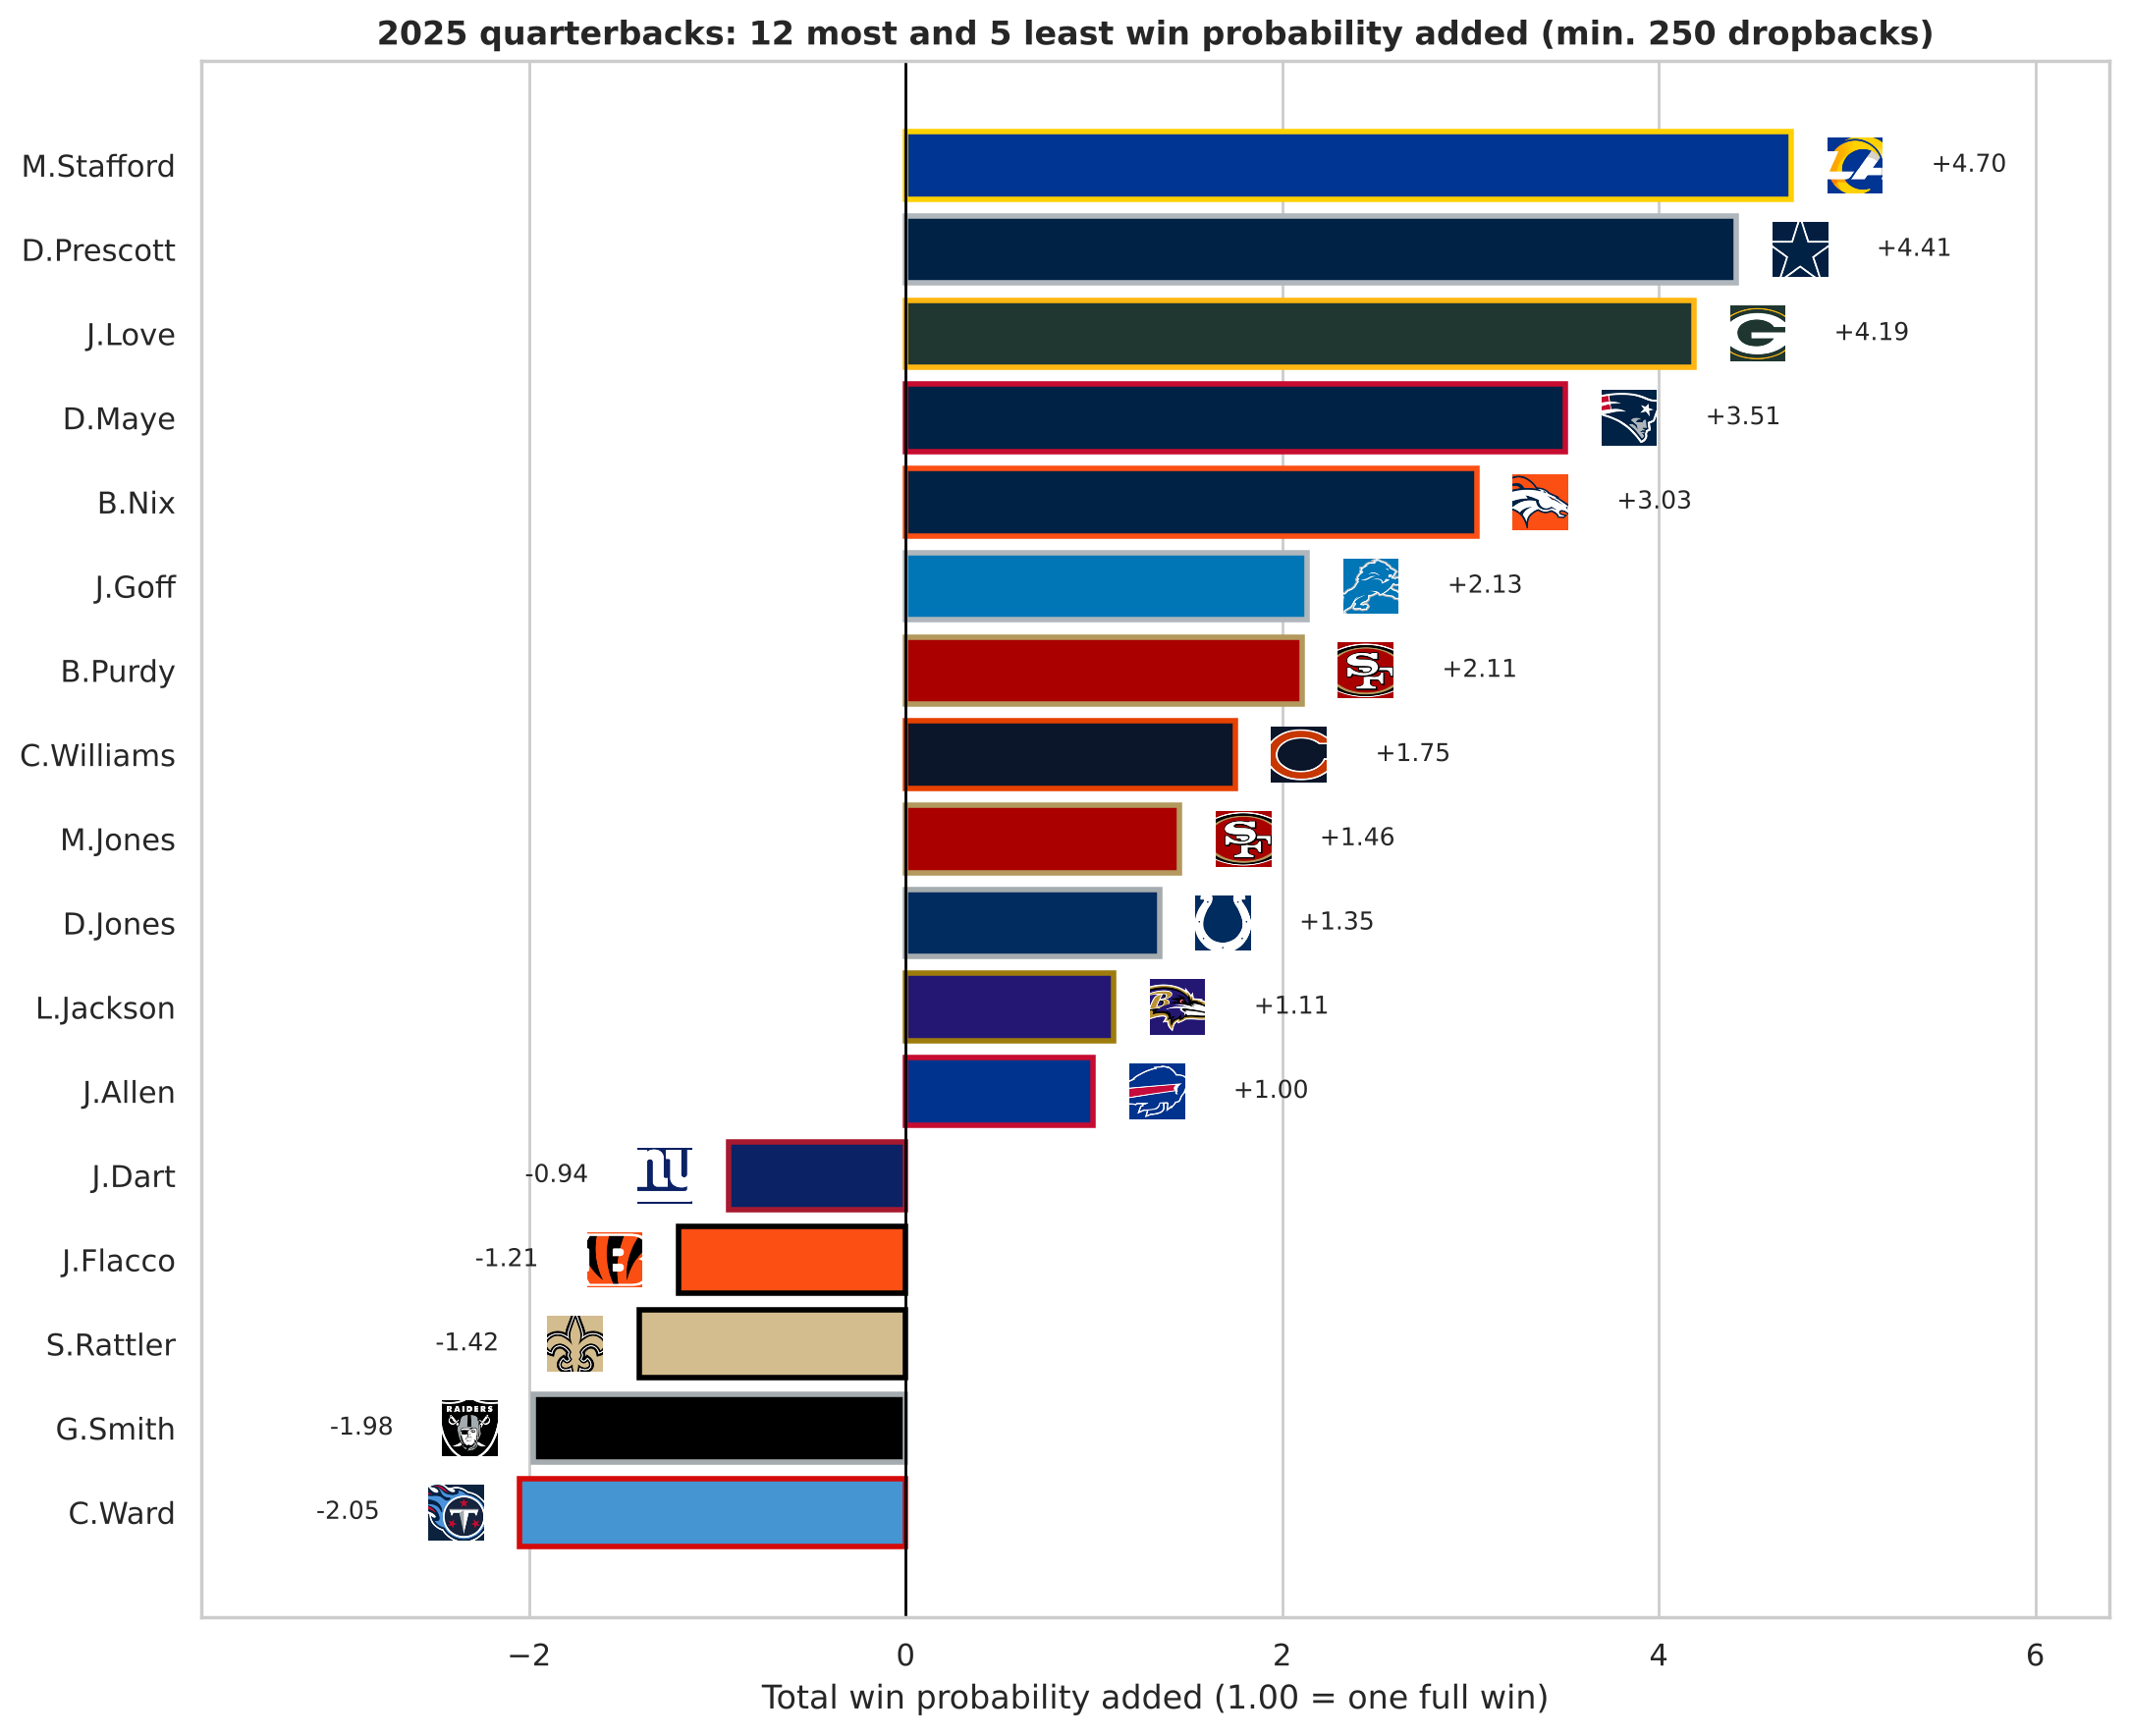

,team,dropbacks,total_wpa,total_epa
passer_player_name,,,,
M.Stafford,LA,617,4.700,141.390
D.Prescott,DAL,631,4.410,105.110
J.Love,GB,461,4.190,110.680
D.Maye,NE,540,3.510,160.860
B.Nix,DEN,638,3.030,57.920
J.Goff,DET,614,2.130,107.130
B.Purdy,SF,298,2.110,57.950
C.Williams,CHI,594,1.750,42.440
M.Jones,SF,304,1.460,38.510


In [40]:
qb = pbp[pbp.passer_player_name.notna()]
qb_tbl = (qb.groupby("passer_player_name")
            .agg(team=("posteam", lambda t: t.mode()[0]), dropbacks=("wpa", "size"),
                 total_wpa=("wpa", "sum"), total_epa=("epa", "sum"))
            .query("dropbacks >= 250")
            .sort_values("total_wpa"))

show = pd.concat([qb_tbl.head(5), qb_tbl.tail(12)]).drop_duplicates()   # 12 best + 5 worst
fig, ax = plt.subplots(figsize=(11, 9))
ax.barh(show.index, show.total_wpa, color=[COLOR.get(t, "gray") for t in show.team],
        edgecolor=[COLOR2.get(t, "white") for t in show.team], linewidth=2)
ax.axvline(0, color="black", lw=1)
xpad = (show.total_wpa.max() - show.total_wpa.min()) * 0.05
for k, (name, r) in enumerate(show.iterrows()):
    side = 1 if r.total_wpa >= 0 else -1
    add_logo(ax, r.team, r.total_wpa + side * xpad, k, zoom=0.17)
    ax.text(r.total_wpa + side * xpad * 2.2, k, f"{r.total_wpa:+.2f}", va="center",
            ha="left" if side > 0 else "right", fontsize=9)
ax.set_xlim(show.total_wpa.min() - xpad * 5, show.total_wpa.max() + xpad * 5)
ax.set_xlabel("Total win probability added (1.00 = one full win)")
ax.set_title(f"{PBP_SEASON} quarterbacks: 12 most and 5 least win probability added (min. 250 dropbacks)",
             fontsize=12, weight="bold")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

qb_tbl.sort_values("total_wpa", ascending=False).head(12).round(2)

> 🔍 **Check your understanding:** Two QBs could have the same passing yards but very different WPA. How?

<details><summary><b>Click to reveal the answer</b></summary>

WPA weights each play by the situation. Yards in a 30-point blowout barely change win probability, while a 3rd-down conversion late in a tie game changes it a lot.

</details>

## Part 8 · The 2026 season so far

We plug each team's 2026 stats into the offense and defense models from Part 4. **Actual minus expected** shows which teams are scoring (or allowing) more or less than their stats suggest.

⚠️ After 8–9 games these numbers are noisy. Teams far from expected often **regress toward the middle** later in the season.

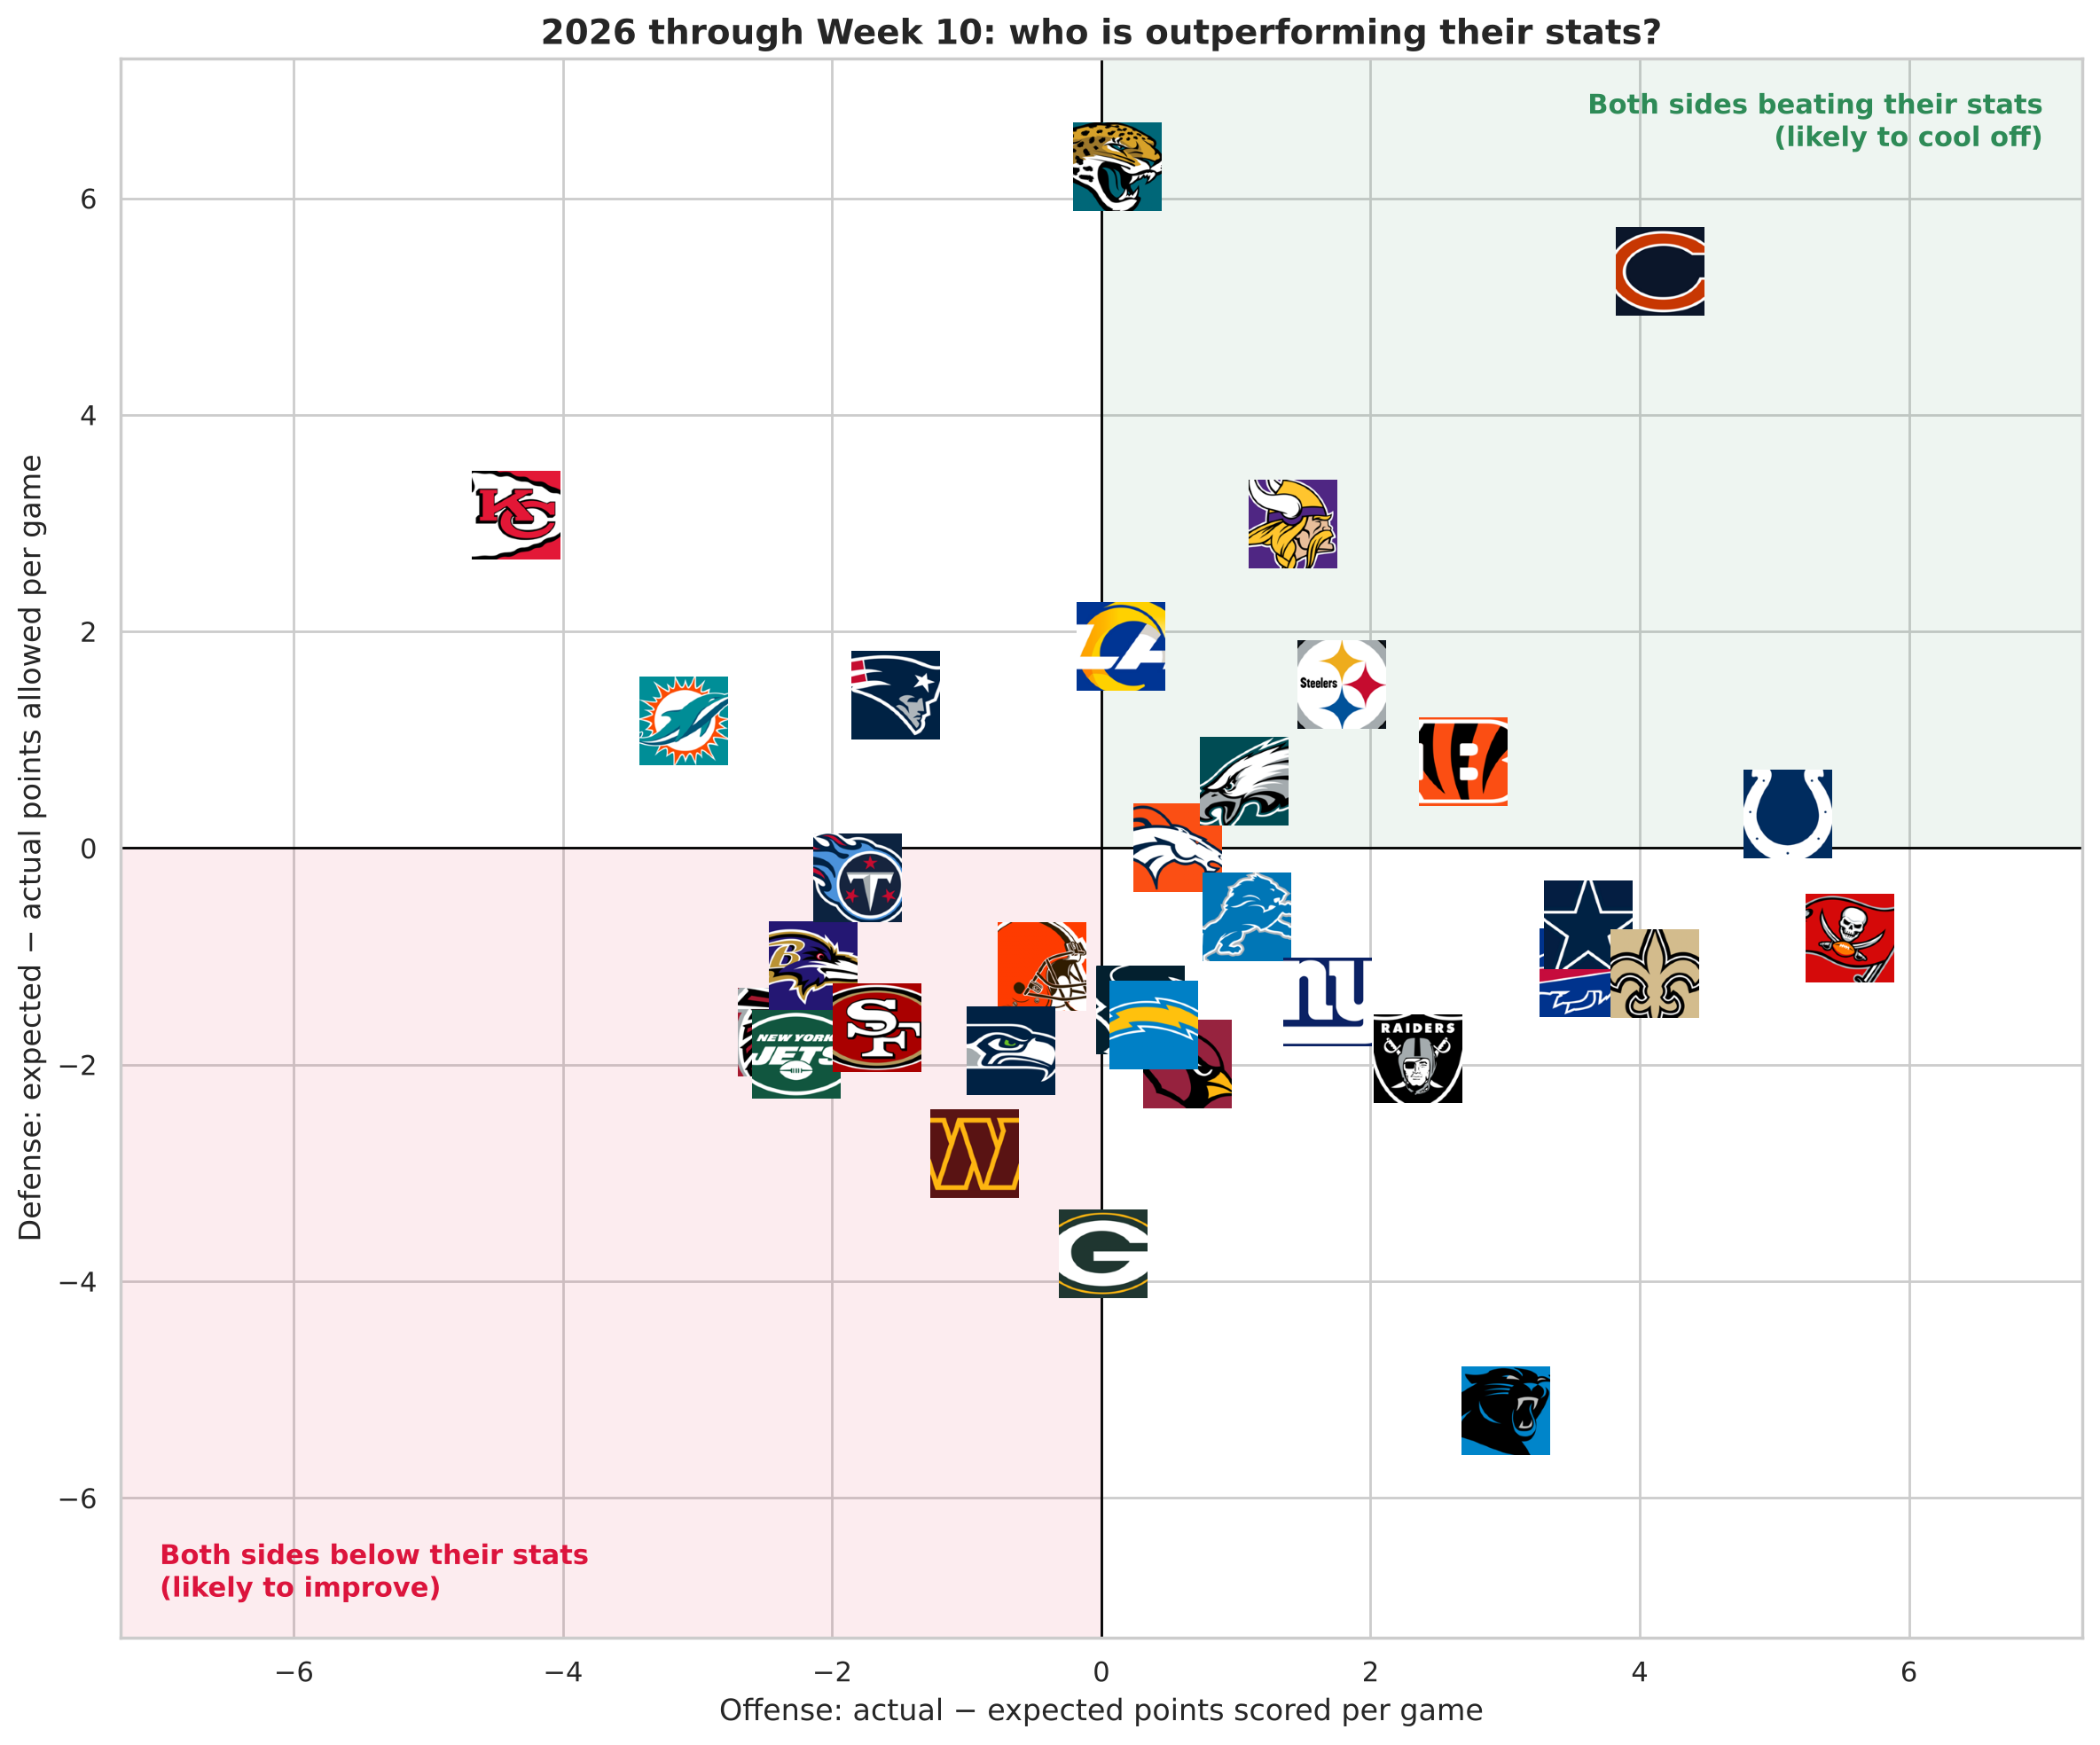

In [41]:
cur = current.copy()
cur["exp_ppg"]  = off_A.predict(cur)
cur["exp_papg"] = def_A.predict(cur)
cur["off_over"] = cur.ppg  - cur.exp_ppg     # + = scoring MORE than stats suggest
cur["def_over"] = cur.exp_papg - cur.papg    # + = allowing FEWER than stats suggest
cur["total_over"] = cur.off_over + cur.def_over
LATEST_WEEK = int(sched.loc[sched.season == CURRENT_SEASON, "week"].max())

fig, ax = plt.subplots(figsize=(12, 10))
lim = max(cur.off_over.abs().max(), cur.def_over.abs().max()) + 1
ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
ax.fill_between([0, lim], 0, lim, color="seagreen", alpha=.08)
ax.fill_between([-lim, 0], -lim, 0, color="crimson", alpha=.08)
ax.axhline(0, color="black", lw=1); ax.axvline(0, color="black", lw=1)
for _, r in cur.iterrows():
    add_logo(ax, r.team, r.off_over, r.def_over, zoom=0.30)
kw = dict(transform=ax.transAxes, fontsize=11, weight="bold")
ax.text(.98, .98, "Both sides beating their stats\n(likely to cool off)", ha="right", va="top", color="seagreen", **kw)
ax.text(.02, .02, "Both sides below their stats\n(likely to improve)", ha="left", va="bottom", color="crimson", **kw)
ax.set(xlabel="Offense: actual − expected points scored per game",
       ylabel="Defense: expected − actual points allowed per game")
ax.set_title(f"{CURRENT_SEASON} through Week {LATEST_WEEK}: who is outperforming their stats?", fontsize=14, weight="bold")
plt.tight_layout(); plt.show()

In [42]:
board = cur.sort_values("total_over", ascending=False).reset_index(drop=True)
board.insert(0, "logo", board.team)
board["record"] = [record(CURRENT_SEASON, t) for t in board.team]
cols = {"logo": "", "team": "Team", "record": "Record", "ppg": "PPG", "exp_ppg": "Exp PPG", "off_over": "Off +/-",
        "papg": "Opp PPG", "exp_papg": "Exp Opp PPG", "def_over": "Def +/-", "total_over": "Total +/-"}
board = board[list(cols)].rename(columns=cols)

v = board["Total +/-"].abs().max()
styled = (board.style
          .format({"": lambda t: logo_html(t, 30)}, escape=None)
          .format(precision=1, subset=list(board.columns[3:]))
          .background_gradient(cmap="RdYlGn", subset=["Off +/-", "Def +/-", "Total +/-"], vmin=-v, vmax=v)
          .set_properties(**{"text-align": "center", "font-family": "sans-serif"})
          .set_table_styles([{"selector": "th", "props": "background:#1f2937;color:white;padding:6px"}])
          .hide(axis="index"))
display(styled)

,Team,Record,PPG,Exp PPG,Off +/-,Opp PPG,Exp Opp PPG,Def +/-,Total +/-
,CHI,7-2,26.8,22.6,4.2,20.4,25.8,5.3,9.5
,JAX,7-2,29.9,29.8,0.1,16.0,22.3,6.3,6.4
,IND,3-7,20.8,15.7,5.1,27.1,27.4,0.3,5.4
,TB,3-6,22.4,16.9,5.6,19.8,18.9,-0.8,4.7
,MIN,7-2,19.6,18.1,1.4,14.0,17.0,3.0,4.4
,CIN,7-2,30.9,28.2,2.7,21.4,22.2,0.8,3.5
,PIT,6-3,22.0,20.2,1.8,20.2,21.7,1.5,3.3
,NO,3-6,22.4,18.3,4.1,26.2,25.1,-1.2,3.0
,DAL,4-6,28.6,25.0,3.6,28.2,27.5,-0.7,2.9
,BUF,8-1,31.9,28.3,3.6,22.1,21.0,-1.2,2.4


## Part 9 · Limitations and exercises

### What these models can't tell us
* **Explaining vs. forecasting.** The season models use stats from the same season as the points, so they explain *how* teams scored, not what will happen next year. (Exercise 4 tests that.)
* **Correlation isn't causation.** Teams that are winning big run the ball late to burn clock, so winning *causes* some of the rushing.
* **Rows aren't fully independent.** The same franchise appears every season, and plays from the same game are linked.
* **Points include non-offense scores.** Defensive and return touchdowns count in `ppg` even though our offense stats don't cause them.
* **Era effects.** Passing has become more efficient over time.

### Checking the linear model's assumptions
Linear regression assumes the **residuals** (actual − predicted) are random noise: no pattern versus the fitted values, and roughly bell-shaped.

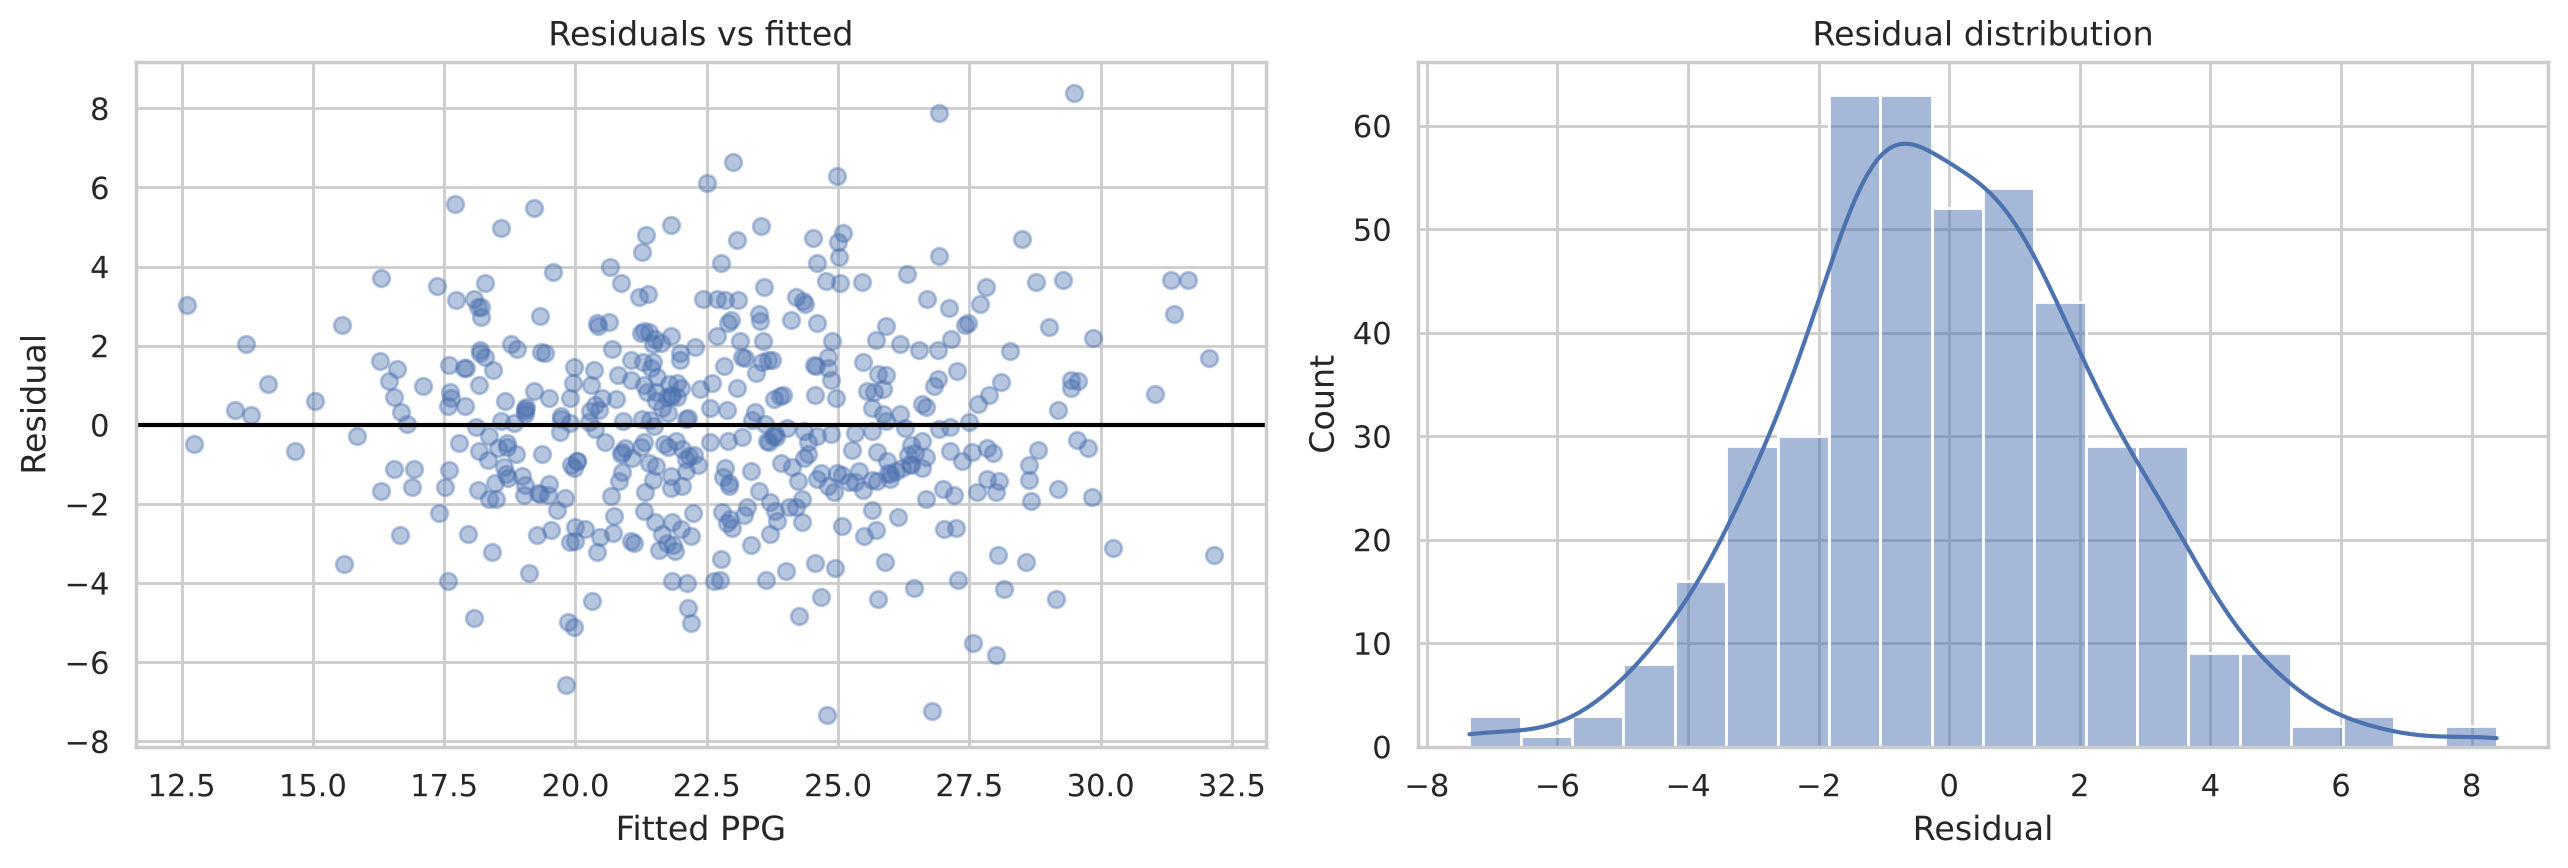

In [43]:
# Quick residual diagnostics for the offense model
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(off_A.fittedvalues, off_A.resid, alpha=.4)
axes[0].axhline(0, color="black"); axes[0].set(title="Residuals vs fitted", xlabel="Fitted PPG", ylabel="Residual")
sns.histplot(off_A.resid, kde=True, ax=axes[1]); axes[1].set(title="Residual distribution", xlabel="Residual")
plt.tight_layout(); plt.show()

### ✏️ Exercises

**Linear regression**
1. **Add a variable.** Pick a stat from `games.columns` (for example `passing_air_yards` or `passing_yards_after_catch`), build its season rate, add it to the offense model, and check whether the **test MAE** improves.
2. **Symmetry test.** Is a takeaway worth the same as a giveaway avoided? Run `combo.t_test("def_to_pg + off_to_pg = 0")` and interpret the p-value.
3. **Era adjustment.** Add `C(season)` to the offense model. How does the passing coefficient change? What does that say about league-wide trends?
4. **True prediction.** Use each team's stats from season *t* to predict its points per game in season *t + 1* (hint: `groupby("team").shift(1)`). How much does R² drop?

**Logistic regression**

5. **Remove the engineered feature.** Refit the win-probability model without `lead_per_time`. How much worse is the 2025 Brier score?
6. **Fix a blind spot.** Create `red_zone = (yardline_100 <= 20).astype(int)` and a "late red zone" feature `red_zone * (min_left < 2)`. Add both to the model, interpret their odds ratios, and check whether the 2025 Brier score and the goal-line disagreements improve.
7. **Your own situation.** Use `win_prob()` to find how big a lead a team needs with 5 minutes left to have a 90% chance of winning.

**Plays and players**

8. **Clutch receivers.** Repeat the clutch-QB chart for `receiver_player_name`. Who are the most clutch pass catchers?
9. **Pick a 2026 team** that is far from expected in Part 8. Argue whether the gap is skill (red zone, kicker, scheme) or luck.